# Sistem Peringatan Dini Volatilitas IHSG 5 Hari ke Depan

**Write-up analisis untuk PT Investion**

**TIM : habis lomba ini kita naik gunung**

- Dani Shofi Nur Izza
- Nino Ahmadiy
- Haidar Adlan Ar-Rozaq Al Bustomi

**Universitas Pembangunan Nasional "Veteran" Jawa Timur**

Tujuan: memperkirakan **seberapa besar** IHSG bergerak 5 hari ke depan, memberi alarm lebih awal, dan menjelaskan alasannya tanpa mengintip masa depan.

## Daftar Isi

| Bab | Isi |
|---|---|
| 1 sampai 3 | Tujuan, data, pembersihan |
| 4 | EDA |
| 5 | **Task 1:** fitur |
| 6 | **Task 2:** anti-leakage |
| 7 | **Task 3:** model dan akurasi |
| 8 | Sistem alarm |
| 9 | **Task 3:** XAI |
| 10 | Kesimpulan dan **lembar jawaban (10.2)** |
| Lampiran | Uji tambahan (opsional, untuk pemeriksaan lebih dalam) |

# Bab 1. Business Understanding

## 1.1 Apa yang diprediksi

**Y** = simpangan baku log return IHSG hari t+1 sampai t+5 (dibuktikan di 2.3), tipikal 0,007 (0,7% per hari). Sinyal terbit pagi t+1 dengan data sampai t. Y berisik (hanya 5 return) dan window-nya tumpang tindih (butuh jeda 5 hari).

## 1.2 Bagaimana hasilnya dinilai

**Akurasi diukur dengan tiga ukuran yang saling melengkapi, dan ketiganya selalu dilaporkan berdampingan:**

| Ukuran | Peran | Alasan |
|---|---|---|
| **RMSE dan MAE** | Metrik resmi studi kasus | Diminta Task 3 untuk benchmark terhadap baseline |
| **QLIKE** | Ukuran galat utama untuk membandingkan model volatilitas | Y hanya dihitung dari 5 return, jadi berisik. Patton (2011): dengan target berisik seperti ini, hanya MSE dan QLIKE yang tetap memberi urutan model yang benar. QLIKE menilai galat relatif, jadi hari tenang tidak tenggelam oleh hari krisis. |
| **R2 out-of-sample** | Ukuran kecocokan | R2 biasa membandingkan model dengan rata-rata periode uji yang belum diketahui saat memprediksi. R2 out-of-sample membandingkan dengan rata-rata historis yang tersedia (Campbell dan Thompson, 2008). |

| Pertanyaan lain | Alat ukur | Bab |
|---|---|---|
| Berguna sebagai alarm? | AUC, hit rate, presisi, episode | 8 |
| Melihat masa depan? | Uji potong data, perturbasi, kontrol | 6 |
| Kenapa memprediksi begitu? | SHAP | 9 |

## 1.4 Setup Environment dan load data

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import lightgbm as lgb
import shap
from arch import arch_model
from arch.univariate import EGARCH, ConstantMean, StudentsT
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import HuberRegressor, LinearRegression, LogisticRegression, LogisticRegressionCV, QuantileRegressor, Ridge, RidgeCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score, roc_auc_score, roc_curve, average_precision_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, QuantileTransformer, RobustScaler, StandardScaler

# statsmodels memasang filter peringatannya sendiri saat diimpor, jadi filter ini harus dipasang sesudah import
warnings.filterwarnings("ignore", message=".*frequency information")

**Memuat data**

In [2]:
df = pd.read_csv("dataset peserta.csv", parse_dates=["Date"])

In [3]:
df.head()

,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
0,2010-01-04,81.510002,1117.699951,9364.200195,1132.989990,2575.312988,20.040001,5.134206,6.5,0.11,0.007705
1,2010-01-05,81.769997,1118.099976,9305.200195,1136.520020,2605.175537,19.350000,5.134206,6.5,0.11,0.007437
2,2010-01-06,83.180000,1135.900024,9218.099609,1137.140015,2603.195557,19.160000,5.134206,6.5,0.11,0.009762
3,2010-01-07,82.660004,1133.099976,9272.500000,1141.689941,2586.794189,19.059999,5.134206,6.5,0.11,0.008496
4,2010-01-08,82.750000,1138.199951,9212.700195,1144.979980,2614.268311,18.129999,5.134206,6.5,0.11,0.007840


In [4]:
df.shape

(4266, 11)

In [5]:
df.columns.tolist()

['Date',
 'OIL',
 'GOLD',
 'USDIDR',
 'SP500',
 'IHSG',
 'VIX',
 'CPI',
 'BI_rate',
 'US_rate',
 'Target_Volatilitas_Y']

# Bab 2. Data Understanding

Dua pertanyaan: apakah **nilainya** masuk akal, dan apakah **tanggalnya** sama dengan saat informasinya diketahui?

## 2.1 Bentuk dan kelengkapan data

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4266 entries, 0 to 4265
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  4266 non-null   datetime64[us]
 1   OIL                   4266 non-null   float64       
 2   GOLD                  4266 non-null   float64       
 3   USDIDR                4266 non-null   float64       
 4   SP500                 4266 non-null   float64       
 5   IHSG                  4266 non-null   float64       
 6   VIX                   4266 non-null   float64       
 7   CPI                   4266 non-null   float64       
 8   BI_rate               4266 non-null   float64       
 9   US_rate               4266 non-null   float64       
 10  Target_Volatilitas_Y  3907 non-null   float64       
dtypes: datetime64[us](1), float64(10)
memory usage: 366.7 KB


In [7]:
df.isna().sum()

Date                      0
OIL                       0
GOLD                      0
USDIDR                    0
SP500                     0
IHSG                      0
VIX                       0
CPI                       0
BI_rate                   0
US_rate                   0
Target_Volatilitas_Y    359
dtype: int64

Hanya Y yang kosong (359 baris), dan memang itu rekayasa panitia: data 2025 ke atas sengaja disiapkan sebagai data uji tanpa jawaban.

In [8]:
df['Date'].duplicated().sum()

np.int64(0)

In [9]:
df.drop(columns="Date").duplicated().sum()

np.int64(1)

Tidak ada tanggal kembar. Satu baris identik (25 Desember 2018) adalah hari libur berharga disalin, bukan duplikat.

**Apakah ada hari kerja yang hilang?** Kalau ada, window 5 hari diam-diam mencakup rentang yang lebih panjang.

In [10]:
pd.bdate_range(df["Date"].min(), df["Date"].max()).difference(df["Date"])

DatetimeIndex(['2024-12-25', '2024-12-26', '2024-12-27', '2024-12-30',
               '2024-12-31', '2025-01-01', '2025-04-18', '2025-12-25',
               '2026-01-01'],
              dtype='datetime64[us]', freq=None)

In [11]:
df["IHSG"].diff().eq(0).groupby(df["Date"].dt.year).sum()

Date
2010    15
2011    13
2012    15
2013    17
2014    19
2015    17
2016    15
2017    22
2018    21
2019    16
2020    20
2021    14
2022    14
2023    21
2024    22
2025    22
2026    12
Name: IHSG, dtype: int64

Hanya 9 hari kerja tanpa baris (sekitar Natal dan Tahun Baru). Hari libur dicatat konsisten dari train sampai test.

In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,4266,2018-03-08 13:37:33.164557,2010-01-04 00:00:00,2014-02-04 06:00:00,2018-03-07 12:00:00,2022-04-07 18:00:00,2026-05-22 00:00:00,NaN
OIL,4266.0,71.802815,-37.630001,55.099998,71.724998,88.757502,123.699997,20.811306
GOLD,4266.0,1735.313923,1050.800049,1271.900024,1531.400024,1851.300049,5318.399902,747.512696
USDIDR,4266.0,13143.230766,888.109985,11552.0,13797.5,14849.875,17777.0,2475.850617
SP500,4266.0,3035.651755,1022.580017,1838.255005,2642.204956,4146.707642,7501.240234,1590.731819
IHSG,4266.0,5577.936443,2475.475586,4562.614502,5708.639404,6652.172119,9134.700195,1331.838628
VIX,4266.0,18.419341,9.14,13.79,16.74,21.0875,82.690002,6.793602
CPI,4266.0,3.857985,0.76,3.030585,3.669387,5.134206,6.412495,1.677919
BI_rate,4266.0,5.631622,3.5,4.75,5.75,6.5,7.75,1.216699
US_rate,4266.0,1.464191,0.05,0.1,0.36,2.4,5.33,1.817596


## 2.2 Hal yang janggal pada data

USDIDR minimum 888 dan OIL minimum negatif perlu diperiksa.

In [13]:
df[df["USDIDR"] < 5000][["Date", "USDIDR"]]

,Date,USDIDR
215,2010-11-01,888.109985
546,2012-02-07,892.000000


In [14]:
df["USDIDR"].value_counts().head(3)

USDIDR
9612.450195     28
12285.000000     8
13296.000000     7
Name: count, dtype: int64

In [15]:
df[df["OIL"] < 0][["Date", "OIL"]]

,Date,OIL
2685,2020-04-20,-37.630001


In [16]:
(df["IHSG"].diff() == 0).sum()

np.int64(295)

In [17]:
(df["Target_Volatilitas_Y"] == 0).sum()

np.int64(16)

In [18]:
df[["CPI", "BI_rate", "US_rate"]].nunique()

CPI        17
BI_rate    18
US_rate    81
dtype: int64

## 2.3 Apa sebenarnya Y?

Hari mana yang dipakai Y? Kami hitung ulang Y dari harga IHSG.

In [19]:
np.log(df["IHSG"]).diff().rolling(5).std().shift(-5).corr(df["Target_Volatilitas_Y"])

np.float64(0.9994807762910775)

| Temuan | Artinya |
|---|---|
| USDIDR 888,11 dan 892,00 | Salah ketik, kurang satu digit. Diperbaiki. |
| USDIDR 9.612,45 muncul 28 kali | Nilai macet. Diperbaiki. |
| OIL -37,63 (20 April 2020) | Asli. Dipertahankan. |
| 295 hari IHSG datar | Hari libur. Dipertahankan. |
| CPI, BI_rate, US_rate | Berbentuk tangga. |
| Korelasi hitung ulang Y 0,9995 | Y memakai **t+1 sampai t+5**. Fitur hanya boleh memakai data sampai t. |

## 2.4 Kapan data makro diketahui pasar?

Kalau tangga suku bunga naik sebelum tanggal pengumuman, model memakai informasi yang belum ada.

In [20]:
for k in ["US_rate", "BI_rate", "CPI"]:
    tgl = df.loc[df[k].diff().fillna(0) != 0, "Date"]
    print(f"{k}: {len(tgl)} perubahan, {(tgl.dt.day <= 4).sum()} terjadi pada tanggal 1 sampai 4")

US_rate: 131 perubahan, 131 terjadi pada tanggal 1 sampai 4
BI_rate: 48 perubahan, 11 terjadi pada tanggal 1 sampai 4
CPI: 16 perubahan, 16 terjadi pada tanggal 1 sampai 4


In [21]:
tgl_bi = df.loc[df["BI_rate"].diff().fillna(0) != 0, "Date"]
tgl_bi.groupby(tgl_bi.dt.year >= 2016).apply(lambda s: (s.dt.day <= 4).mean())

Date
False    1.0
True     0.0
Name: Date, dtype: float64

- **US_rate:** 131 perubahan semuanya di tanggal 1 sampai 4, padahal The Fed mengumumkan di tengah bulan.
- **BI_rate:** sebelum 2016 semuanya di awal bulan.
- **CPI:** berubah tiap Januari (inflasi setahun).

**Bersih secara nilai, bocor secara waktu.** Suku bunga ditunda 21 hari bursa, CPI tidak dipakai.

## Hasil analisis dari bab ini

- Y = volatilitas t+1 sampai t+5. Fitur hanya boleh memakai data sampai t.
- Hanya USDIDR yang perlu dibersihkan.
- Data makro bocor secara waktu: suku bunga ditunda, CPI dibuang.

# Bab 3. Membersihkan data

In [22]:
data = df.rename(columns={"Target_Volatilitas_Y": "Y"}).set_index("Date").sort_index()

**Salah ketik kurs.** Hari sebelum dan sesudahnya sekitar 8.900, jadi penjelasan paling masuk akal adalah satu digit yang hilang.

In [23]:
data.loc[data["USDIDR"] < 5000, "USDIDR"] *= 10
data.loc[["2010-11-01", "2012-02-07"], "USDIDR"]

Date
2010-11-01    8881.099854
2012-02-07    8920.000000
Name: USDIDR, dtype: float64

**Nilai macet 9.612,45.** Angka yang sama muncul 28 kali, berselang-seling dengan kurs wajar. Itu bukan perilaku kurs. Kami ganti dengan kurs hari bursa sebelumnya.

In [24]:
data["USDIDR"] = data["USDIDR"].mask(data["USDIDR"].round(2) == 9612.45).ffill()
(data["USDIDR"].round(2) == 9612.45).sum()

np.int64(0)

**Lonjakan satu hari:** kurs bergerak lebih dari 3,5% lalu berbalik besoknya. Indikasi pola salah catat, bukan kejadian pasar.

In [25]:
r_kurs = np.log(data["USDIDR"]).diff()
lonjakan = (r_kurs.abs() > 0.035) & (r_kurs.shift(-1).abs() > 0.035) & (r_kurs * r_kurs.shift(-1) < 0)
data.index[lonjakan]

DatetimeIndex(['2013-10-14', '2013-10-21', '2013-12-09', '2025-06-19'], dtype='datetime64[us]', name='Date', freq=None)

In [26]:
data["USDIDR"] = data["USDIDR"].mask(lonjakan).ffill()

Aturan ini memang melihat hari berikutnya. Itu tidak masalah, karena tujuannya membersihkan data mentah, bukan membuat fitur. Kelemahannya, lonjakan di bawah 3,5% tidak akan terdeteksi.

In [27]:
pd.DataFrame({"sebelum": df["USDIDR"].describe(), "sesudah": data["USDIDR"].describe()})

,sebelum,sesudah
count,4266.000000,4266.000000
mean,13143.230766,13152.354602
std,2475.850617,2458.086097
min,888.109985,8292.700195
25%,11552.000000,11561.000000
50%,13797.500000,13797.500000
75%,14849.875000,14849.875000
max,17777.000000,17777.000000


Jumlah baris tetap 4.266. Yang berubah hanya ujung bawah USDIDR, dari 888 menjadi sekitar 8.300. Sisa distribusinya hampir tidak bergeser, tanda bahwa perbaikan ini tidak mengubah cerita data.

## Hasil analisis dari bab ini

| Temuan | Tindakan |
|---|---|
| USDIDR 888 dan 892 | dikali 10 |
| USDIDR 9.612,45 (28 kali) | diganti kurs hari sebelumnya |
| 4 lonjakan kurs berbalik | diganti kurs hari sebelumnya |
| OIL negatif, hari libur | **dipertahankan** |

Aturan pembersih melihat hari berikutnya, tetapi hanya untuk data mentah, bukan fitur.

# Bab 4. Eksplorasi data: apa yang menggerakkan volatilitas IHSG?


## 4.1 Aturan EDA: hanya data train

EDA hanya memakai train (2010 sampai 2022), supaya keputusan fitur tidak mengintip validasi (2023 sampai 2024) dan test (2025 sampai 2026).

In [28]:
train = data.loc[:"2022"]
valid = data.loc["2023":"2024"]
test = data.loc["2025":]
len(train), len(valid), len(test)

(3390, 517, 359)

## 4.2 Analisis Univariat

In [29]:
variabel = ["OIL", "GOLD", "USDIDR", "SP500", "VIX", "CPI", "BI_rate", "US_rate"]
kolom = variabel + ["IHSG", "Y"]

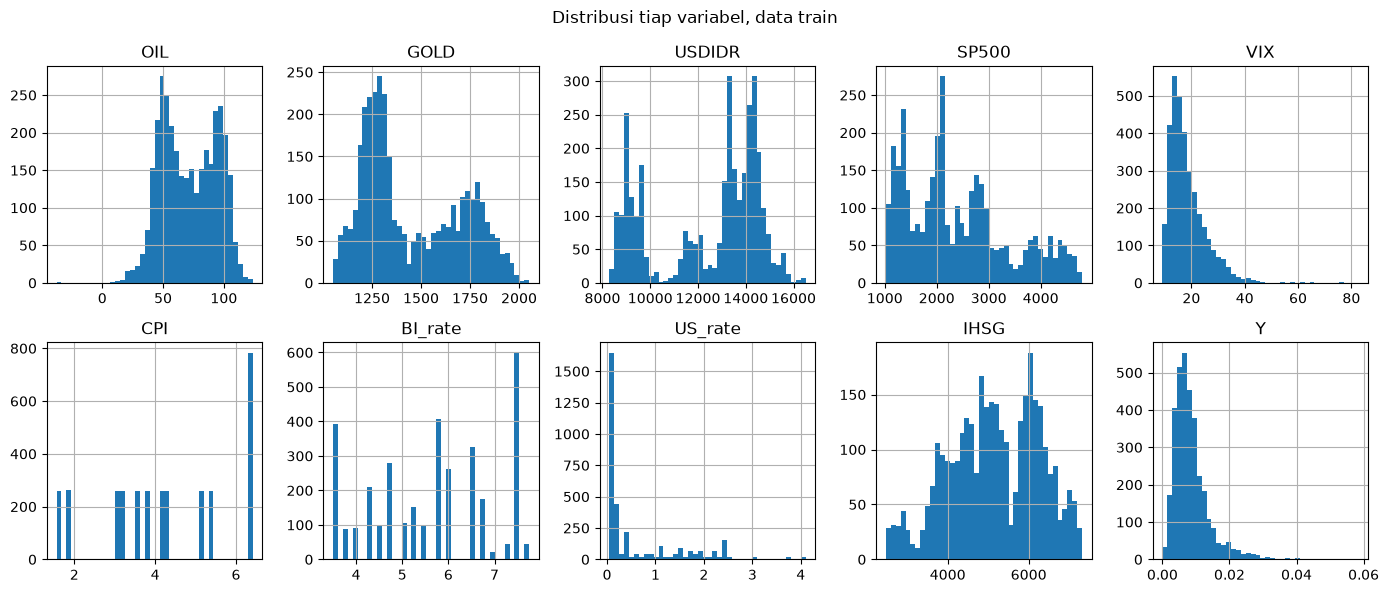

In [30]:
train[kolom].hist(bins=40, figsize=(14, 6), layout=(2, 5))
plt.suptitle("Distribusi tiap variabel, data train")
plt.tight_layout()

In [31]:
train[kolom].skew().round(2)

OIL       -0.02
GOLD       0.46
USDIDR    -0.56
SP500      0.65
VIX        2.22
CPI       -0.07
BI_rate   -0.08
US_rate    1.65
IHSG      -0.22
Y          2.58
dtype: float64

- **Y dan VIX miring ke kanan** (skewness 2,6 dan 2,2): kebanyakan hari tenang, sesekali lonjakan besar. Hari yang paling penting justru paling jarang.
- Suku bunga dan CPI bergerigi karena jarang berubah. IHSG, USDIDR, GOLD, dan SP500 menyebar lebar karena tren.

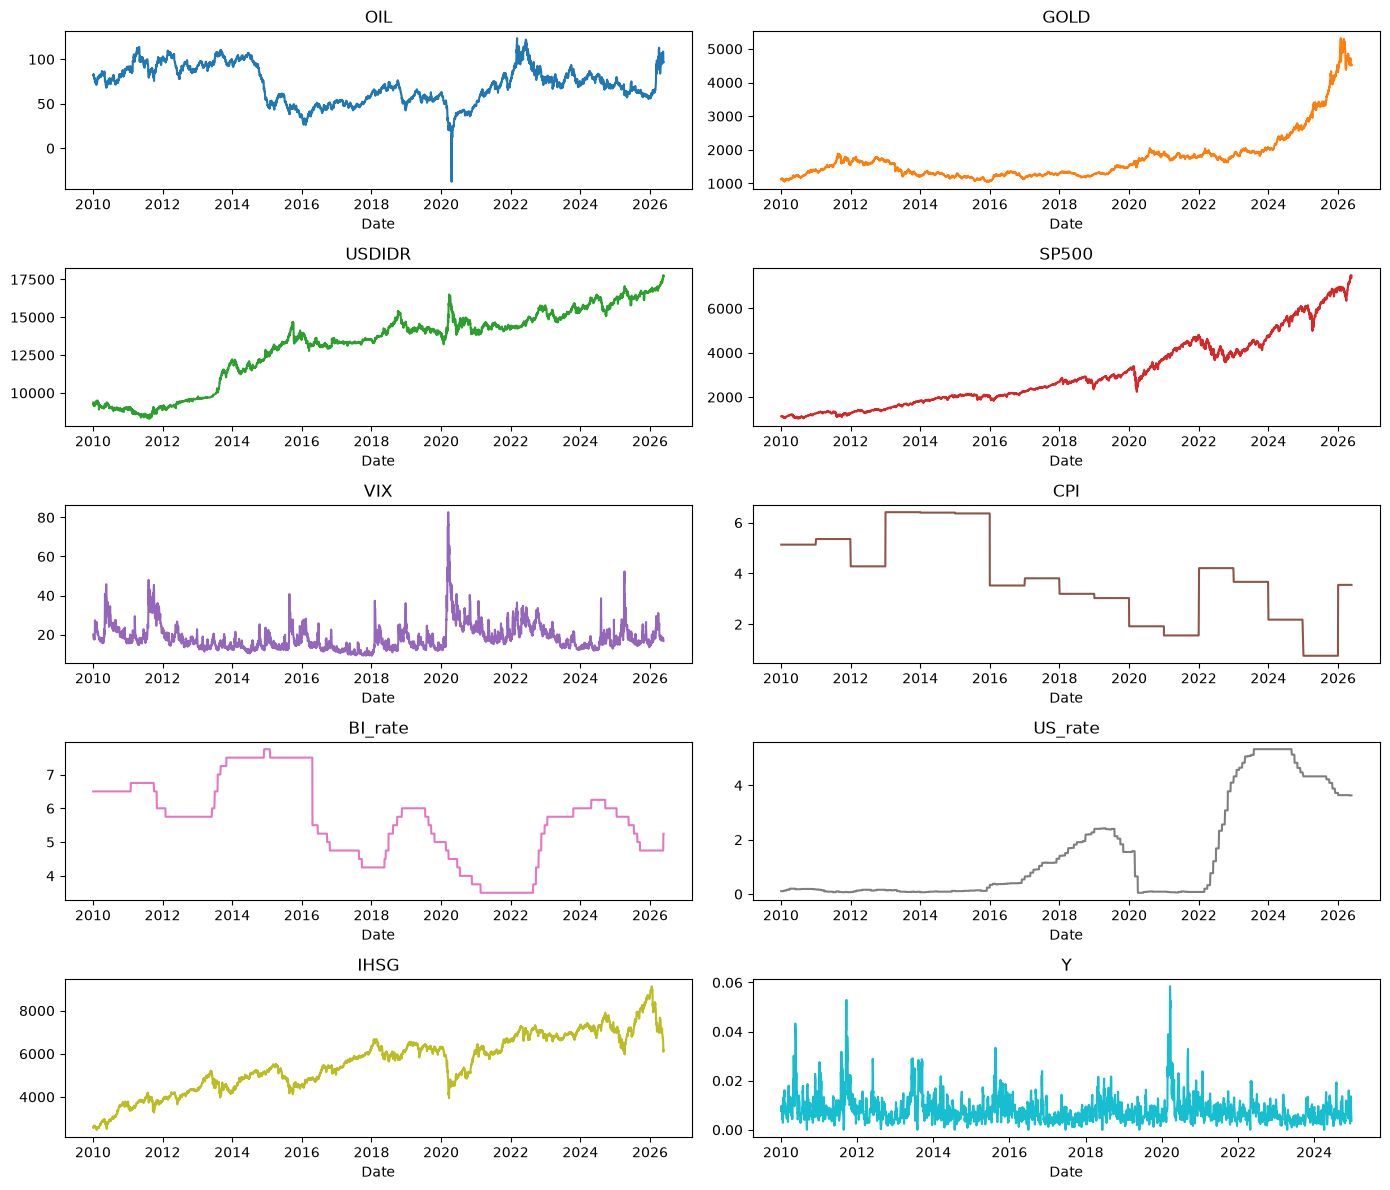

In [32]:
data[kolom].plot(subplots=True, layout=(5, 2), figsize=(14, 12), sharex=False, legend=False, title=kolom)
plt.tight_layout()

- Y melonjak **berkelompok** (2010 sampai 2011, 2013, 2015, puncak 20 Maret 2020): inilah *volatility clustering*.
- VIX melonjak bersamaan dengan Y.
- Di periode test, GOLD, SP500, dan IHSG di atas level tertinggi train, jadi level mentah tidak aman dipakai sebagai fitur.

## 4.3 Analisis Bivariat

**Tiap variabel vs volatilitas Y** 
garis oranye = rata-rata Y 20 hari agar mudah dibaca secara visual.

In [33]:
eda = train.assign(Y_20hari=train["Y"].rolling(20).mean())

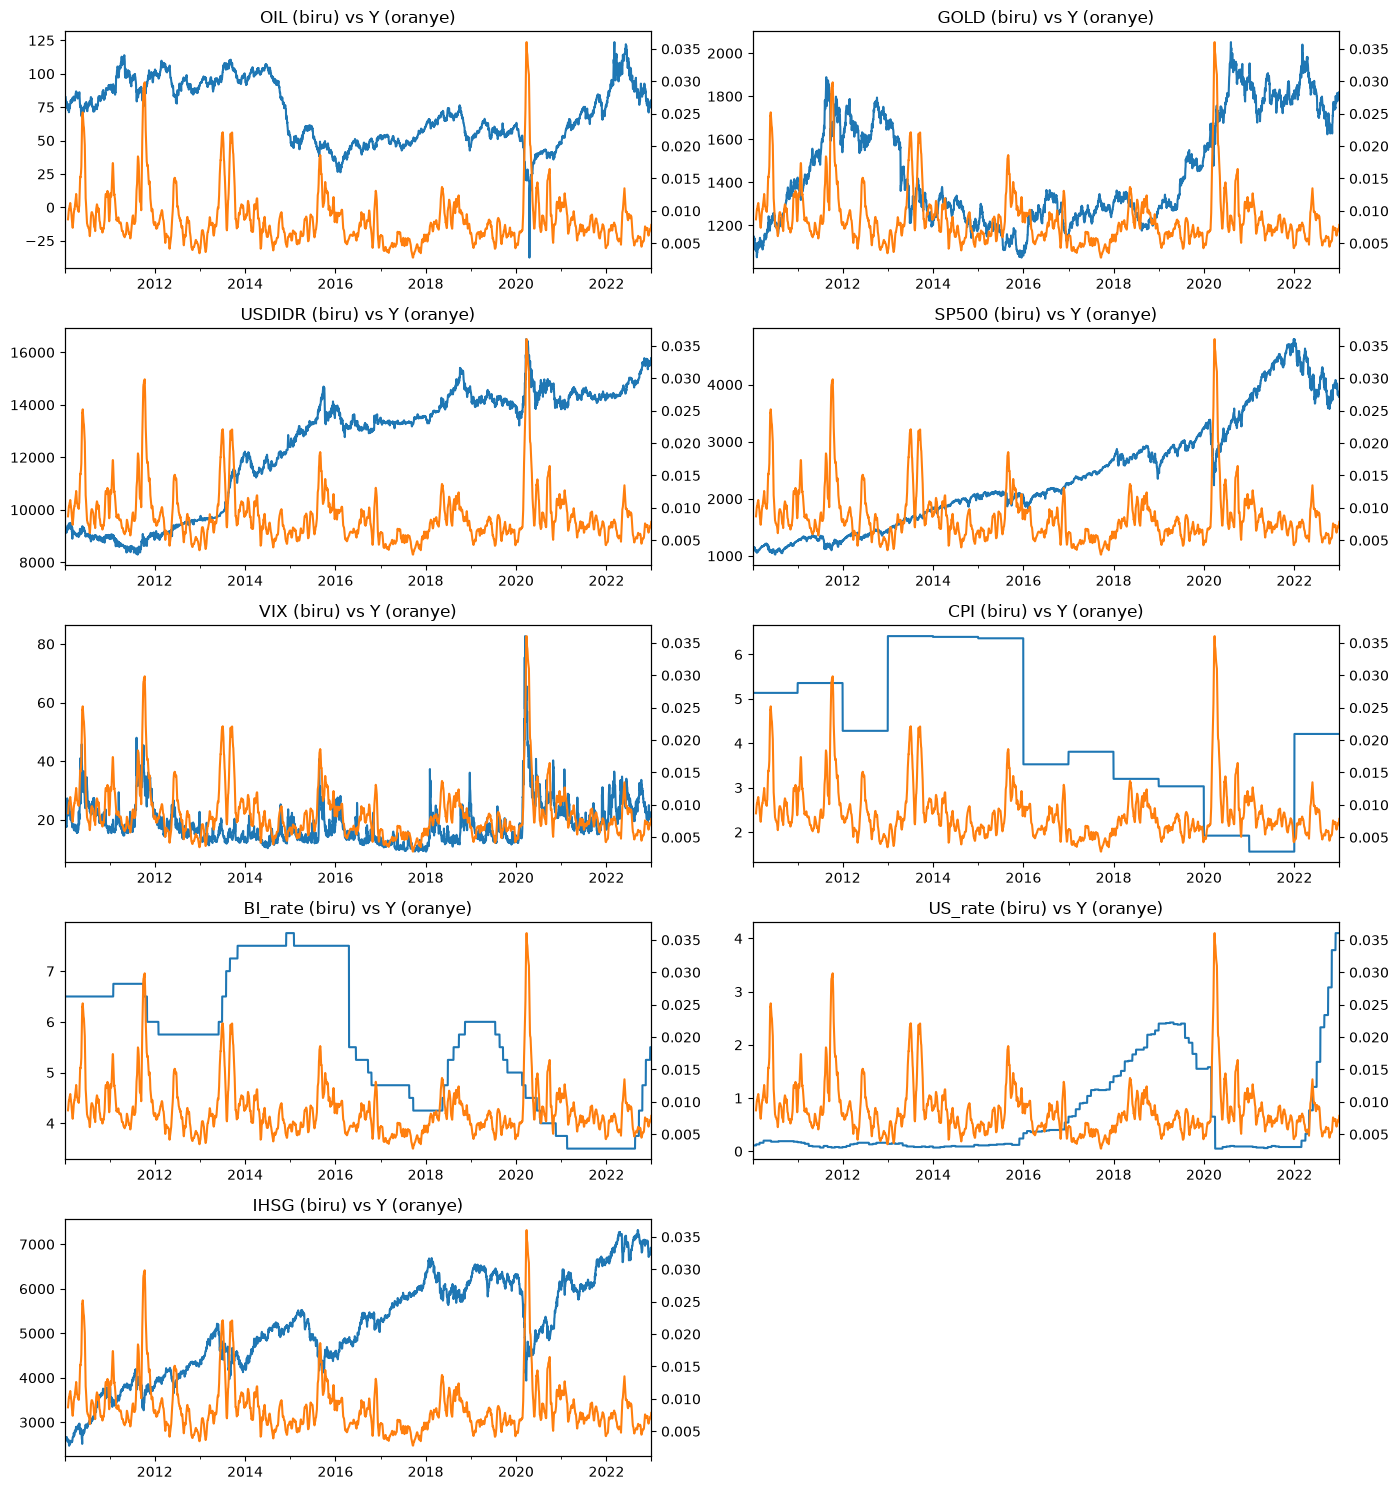

In [34]:
fig, axes = plt.subplots(5, 2, figsize=(14, 15))
for ax, k in zip(axes.ravel(), variabel + ["IHSG"]):
    eda.plot(y=[k, "Y_20hari"], secondary_y="Y_20hari", ax=ax, legend=False, xlabel="", title=f"{k} (biru) vs Y (oranye)")
axes.ravel()[-1].axis("off")
plt.tight_layout()

- **VIX** paling kompak dengan Y: melonjak bersamaan di 2011, 2015, dan 2020.
- **IHSG** berkebalikan: setiap IHSG anjlok, Y melonjak.
- Suku bunga dan CPI sebagai level hampir tidak sejalan dengan Y.

## 4.4 Multivariat

Tiga heatmap Spearman: **level**, **perubahan harian** (tren dibuang), dan **besar perubahan harian** (paling dekat dengan makna volatilitas).

Text(0.5, 1.0, 'Level')

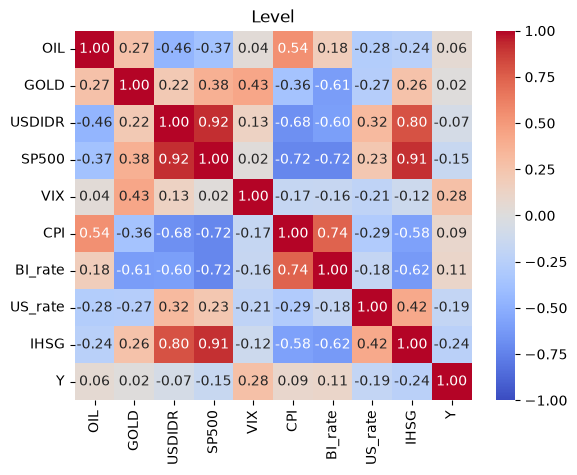

In [35]:
sns.heatmap(train[kolom].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1).set_title("Level")

Text(0.5, 1.0, 'Perubahan harian')

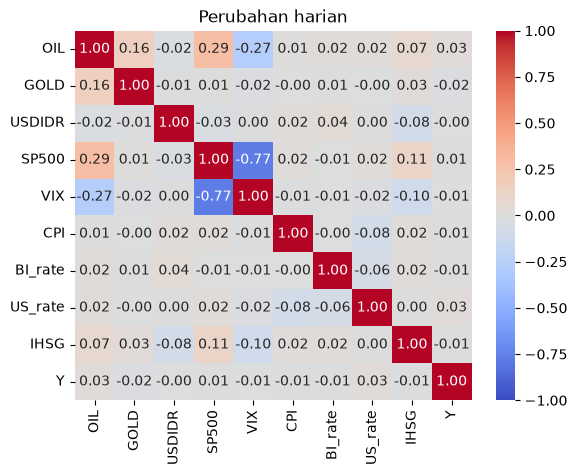

In [36]:
sns.heatmap(train[kolom].diff().corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1).set_title("Perubahan harian")

Text(0.5, 1.0, 'Besar perubahan harian')

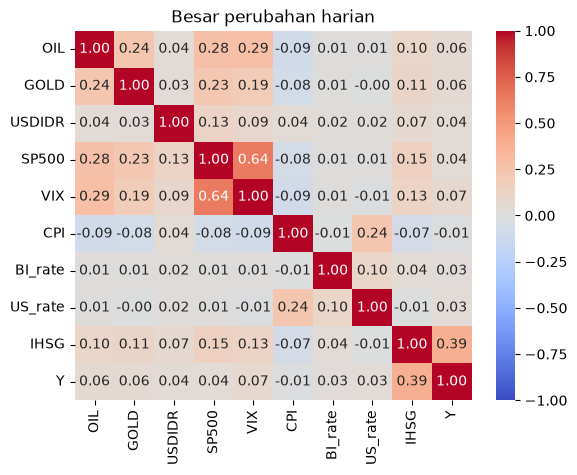

In [37]:
sns.heatmap(train[kolom].diff().abs().corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1).set_title("Besar perubahan harian")

- **Level:** SP500, USDIDR, dan IHSG berkorelasi 0,80 sampai 0,92, sebagian besar karena tren. Dengan Y: VIX 0,28, IHSG -0,24.
- **Perubahan:** hampir semua korelasi hilang, kecuali SP500 dan VIX (-0,77).
- **Besar perubahan:** hanya IHSG yang berkorelasi nyata dengan Y (0,39).

**Note : Fitur sebaiknya mengukur besar gerakan, bukan arah atau level.**

**Multikolinearitas (VIF):** di atas 10 berarti satu variabel hampir bisa ditebak dari variabel lain.

In [38]:
X_vif = sm.add_constant(train[variabel])
pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])], index=variabel).round(1).sort_values(ascending=False)

SP500      13.5
USDIDR     12.6
CPI         4.8
BI_rate     4.4
OIL         4.1
GOLD        3.9
US_rate     1.7
VIX         1.4
dtype: float64

SP500 (13,5) dan USDIDR (12,6) di atas 10, jadi level keduanya tidak dipakai.

## 4.5 Analisis Teknikal

Apakah volatilitas IHSG punya "ingatan"?

In [39]:
r = np.log(train["IHSG"]).diff()

In [40]:
pd.Series({"std harian": r.std(), "skewness": r.skew(), "kurtosis": r.kurt()}).round(4)

std harian    0.0104
skewness     -0.4289
kurtosis      8.2878
dtype: float64

Text(0.5, 1.0, 'Distribusi return harian IHSG, data train')

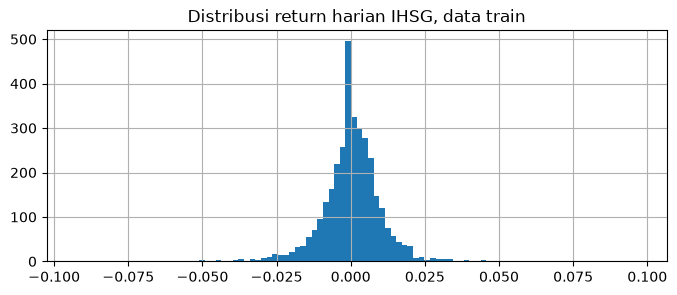

In [41]:
r.hist(bins=100, figsize=(8, 3)).set_title("Distribusi return harian IHSG, data train")

Kurtosis 8,3 berarti **ekor gemuk**, dan skewness -0,43 berarti **kejatuhan besar lebih sering daripada kenaikan besar**. Model yang menganggap return normal akan meremehkan hari buruk.

**Apakah volatilitas berkelompok?** Kami bandingkan autokorelasi return dengan autokorelasi besar return (|return|).

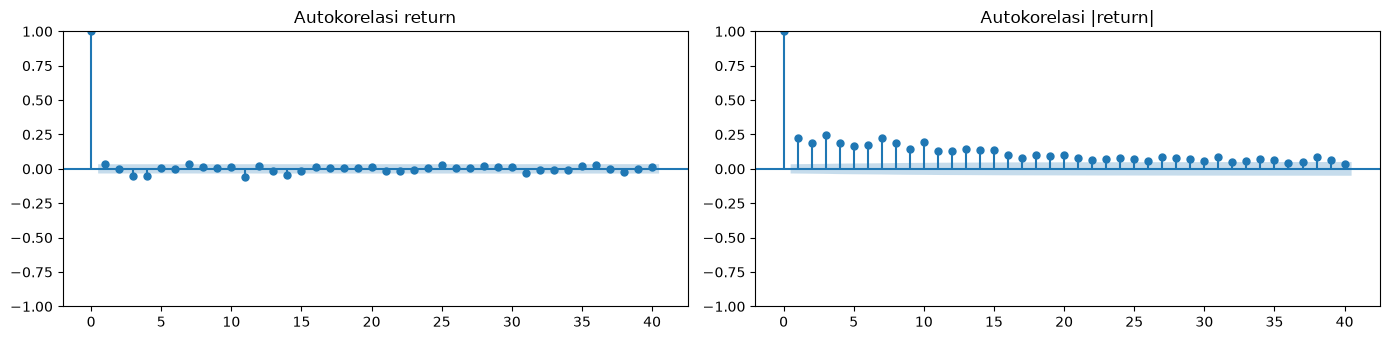

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(r.dropna(), lags=40, ax=axes[0], title="Autokorelasi return")
plot_acf(r.abs().dropna(), lags=40, ax=axes[1], title="Autokorelasi |return|")
plt.tight_layout()

**Temuan terpenting bab ini:** return hampir tidak berautokorelasi, tetapi **|return| berautokorelasi sampai sekitar 20 hari** (0,22 di lag 1, 0,10 di lag 20). Besar gerakan bisa diprediksi walaupun arahnya tidak. Dasar **H1**.

**Apakah pasar yang turun lebih bergejolak?** Median Y per kuintil return 5 hari terakhir.

In [43]:
y_per_ret5 = train["Y"].groupby(pd.qcut(np.log(train["IHSG"]).diff(5), 5)).median()

<Axes: title={'center': 'Median Y menurut kuintil return 5 hari terakhir'}, xlabel='IHSG'>

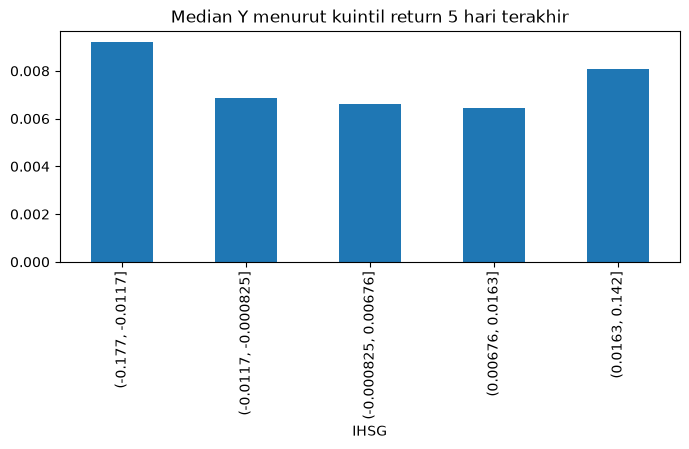

In [44]:
y_per_ret5.plot.bar(figsize=(8, 3), title="Median Y menurut kuintil return 5 hari terakhir")

Polanya U yang **tidak simetris**: Y tertinggi setelah penurunan terbesar (0,0092), lebih tinggi daripada setelah kenaikan terbesar (0,0081). Ini efek leverage, dasar **H2**.

**Bollinger BandWidth** di sekitar COVID, indikator volatilitas favorit analis teknikal.

In [45]:
ihsg = train.loc["2019-06":"2021-06", "IHSG"]
bb = pd.DataFrame({"IHSG": ihsg, "tengah": ihsg.rolling(20).mean(),
                   "atas": ihsg.rolling(20).mean() + 2 * ihsg.rolling(20).std(),
                   "bawah": ihsg.rolling(20).mean() - 2 * ihsg.rolling(20).std()})
bb["bandwidth"] = (bb["atas"] - bb["bawah"]) / bb["tengah"]

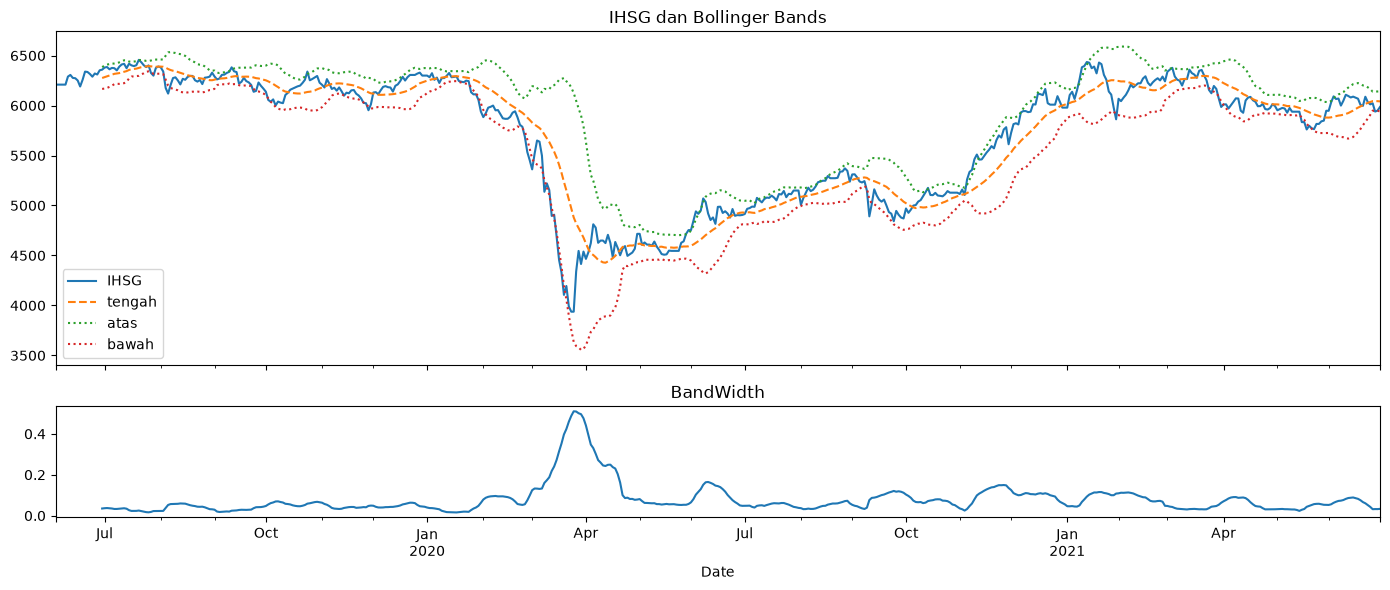

In [46]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, height_ratios=[3, 1])
bb[["IHSG", "tengah", "atas", "bawah"]].plot(ax=axes[0], style=["-", "--", ":", ":"], title="IHSG dan Bollinger Bands")
bb["bandwidth"].plot(ax=axes[1], title="BandWidth")
plt.tight_layout()

BandWidth baru melebar **setelah** harga jatuh, dan isinya mirip rv22. **Tidak dijadikan fitur.**

**Volatilitas realisasi IHSG (rv22 disetahunkan) vs VIX.**

<Axes: title={'center': 'Volatilitas realisasi IHSG (rv22 disetahunkan, %) vs VIX, data train'}, xlabel='Date'>

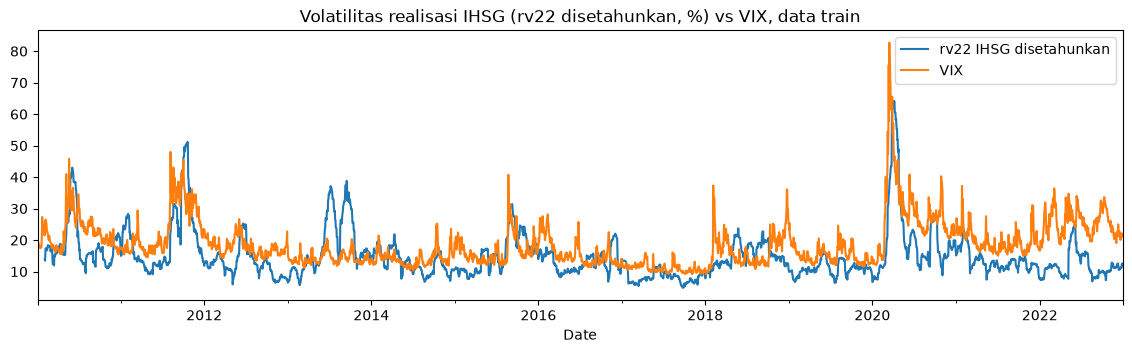

In [47]:
pd.DataFrame({"rv22 IHSG disetahunkan": r.rolling(22).std() * np.sqrt(252) * 100,
              "VIX": train["VIX"]}).plot(figsize=(14, 3.5), title="Volatilitas realisasi IHSG (rv22 disetahunkan, %) vs VIX, data train")

Keduanya bergerak bersama saat krisis global (korelasi sekitar 0,54), tetapi IHSG punya lonjakan sendiri (taper tantrum 2013). VIX menangkap guncangan **global**, volatilitas IHSG menangkap guncangan **domestik**. Model butuh keduanya.

## 4.6 Analisis Makro

Di episode makro mana volatilitas IHSG melonjak, dan apakah suku bunga berperan?

In [48]:
episode = {"Taper tantrum 2013": ("2013-05-20", "2013-09-30"), "Devaluasi yuan 2015": ("2015-08-10", "2015-09-30"),
           "Pengetatan Fed 2018": ("2018-04-01", "2018-10-31"), "COVID 2020": ("2020-02-20", "2020-04-30"),
           "Kenaikan Fed 2022": ("2022-03-01", "2022-12-31")}

In [49]:
pd.DataFrame({k: {"median Y": train.loc[a:b, "Y"].median(), "kali normal": train.loc[a:b, "Y"].median() / train["Y"].median()}
              for k, (a, b) in episode.items()}).T.round(4)

,median Y,kali normal
Taper tantrum 2013,0.0156,2.1202
Devaluasi yuan 2015,0.0137,1.8674
Pengetatan Fed 2018,0.0093,1.2730
COVID 2020,0.0242,3.2968
Kenaikan Fed 2022,0.0064,0.8743


- **COVID 2020** (3,3 kali normal) dan **taper tantrum 2013** (2,1 kali) terburuk. Sumber tiap krisis berbeda, jadi dibutuhkan fitur **stres lintas aset** (H4).
- **Kenaikan Fed 2022** justru di bawah normal (0,87 kali): kenaikan suku bunga AS tidak otomatis membuat IHSG bergejolak.

**Apakah arah suku bunga 12 bulan terakhir berkaitan dengan Y?**

In [50]:
train["Y"].groupby(pd.cut(train["BI_rate"].diff(250), [-5, -0.99, 0.99, 5], labels=["turun", "stabil", "naik"])).agg(["median", "size"])

,median,size
BI_rate,,
turun,0.007421,828
stabil,0.006971,1793
naik,0.007735,519


In [51]:
train["Y"].groupby(pd.cut(train["US_rate"].diff(250), [-5, -0.49, 0.49, 5], labels=["turun", "stabil", "naik"])).agg(["median", "size"])

,median,size
US_rate,,
turun,0.008486,358
stabil,0.007253,2032
naik,0.006609,750


- **BI_rate:** perbedaan median Y antar kelompok kecil (0,0070 sampai 0,0077).
- **Fed:** Y tertinggi saat Fed **memangkas** (0,0085) dan terendah saat menaikkan (0,0066). Sebab-akibatnya terbalik, karena Fed memangkas sebagai respons krisis. Yang menggerakkan pasar adalah **kejutan**, bukan level (Bernanke dan Kuttner).
- Jadi suku bunga dipakai sebagai **perubahan spread** (H5).

## 4.7 Apakah pengaruhnya tertunda?

Bursa AS tutup setelah Jakarta, jadi data AS hari t-1 sudah diketahui sebelum IHSG hari t dibuka. Adakah pengaruh yang datang lebih lambat lagi? Dua pertanyaan di train:
1. Return IHSG hari t vs perubahan variabel di hari t minus jeda.
2. Y vs besar gerakan variabel di hari t minus jeda (sampai 20 hari).

In [52]:
ret_pasar = pd.DataFrame({"S&P 500": np.log(train["SP500"]).diff(), "VIX": np.log(train["VIX"]).diff(),
                          "USDIDR": np.log(train["USDIDR"]).diff(), "Emas": np.log(train["GOLD"]).diff(),
                          "Minyak": train["OIL"].diff() / train["OIL"].rolling(60, min_periods=20).mean().abs()})

**Pertanyaan 1** (korelasi Spearman).

In [53]:
pd.DataFrame({k: {jeda: r.corr(v.shift(jeda), method="spearman") for jeda in range(6)} for k, v in ret_pasar.items()}).T.round(3)

,0,1,2,3,4,5
S&P 500,0.115,0.281,-0.033,0.048,-0.000,-0.002
VIX,-0.089,-0.226,0.023,-0.047,-0.011,0.008
USDIDR,-0.081,-0.021,-0.012,0.001,-0.027,0.020
Emas,0.028,0.068,0.003,0.040,0.006,0.007
Minyak,0.070,0.131,0.002,0.032,-0.029,0.015


- **Pasar AS dan VIX tertunda tepat satu hari.** Return IHSG lebih terkait dengan S&P 500 kemarin (0,281) daripada hari yang sama (0,115). Pola yang sama untuk VIX (-0,226 vs -0,089) dan minyak (0,131 vs 0,070).
- **Setelah jeda 2 hari, pengaruhnya hilang** (semua korelasi di bawah 0,05). Kurs dan emas lemah di semua jeda.
- Untuk desain sistem, ini kabar baik: data S&P 500 dan VIX hari t sudah tersedia sebelum Jakarta buka pada t+1, jadi jeda satu hari itu **otomatis tertangkap**.

**Pertanyaan 2.** Pengaruh yang tertunda akan memuncak di jeda tertentu, bukan di jeda 0.

In [54]:
besar = ret_pasar.abs().assign(**{"IHSG |return|": r.abs(), "VIX level": train["VIX"]})
pd.DataFrame({k: {jeda: train["Y"].corr(besar[k].shift(jeda), method="spearman") for jeda in [0, 1, 2, 3, 5, 10, 20]} for k in besar}).T.round(3)

,0,1,2,3,5,10,20
S&P 500,0.147,0.111,0.107,0.094,0.097,0.090,0.090
VIX,0.084,0.053,0.042,0.037,0.050,0.032,0.034
USDIDR,0.142,0.124,0.115,0.100,0.093,0.120,0.077
Emas,0.079,0.071,0.081,0.071,0.070,0.050,0.072
Minyak,0.058,0.033,0.036,0.024,0.020,0.010,0.011
IHSG |return|,0.173,0.157,0.152,0.138,0.126,0.125,0.100
VIX level,0.276,0.259,0.241,0.227,0.211,0.207,0.195


- **Tidak ada puncak di jeda panjang.** Korelasi tertinggi di jeda 0, lalu meluruh perlahan (VIX level 0,276 di jeda 0 dan 0,195 di jeda 20). Pengaruhnya **bertahan lalu memudar**, bukan tertunda lalu muncul belakangan.
- Volatilitas IHSG sendiri paling kuat di jeda 0 (0,173) dan masih 0,100 di jeda 20, cocok dengan *volatility clustering* di 4.5.
- Jadi window ke belakang sudah cukup. Fitur berjeda diuji formal di Lampiran B.1, dan uji Granger di Lampiran A.

## 4.8 Pola kalender: hari libur bursa

Hari libur (295 hari IHSG datar) memberi return nol, jadi window Y yang memuat libur seharusnya lebih rendah karena rumusnya, bukan karena pasar tenang. Libur dikenali dari harga **hanya untuk EDA**.

In [55]:
libur_harga = data["IHSG"].diff().eq(0).astype(int)

In [56]:
train["Y"].groupby(libur_harga.rolling(5).sum().shift(-5).loc[:"2022"].rename("hari libur di t+1 sampai t+5")).agg(["median", "mean", "size"]).round(4)

,median,mean,size
hari libur di t+1 sampai t+5,,,
0.0,0.0075,0.0089,2623
1.0,0.0073,0.0087,565
2.0,0.0055,0.0063,130
3.0,0.0050,0.0057,36
4.0,0.0034,0.0052,23
5.0,0.0000,0.0000,13


Efeknya besar. Window tanpa hari libur punya median Y 0,0075, dengan 2 hari libur turun ke 0,0055, dengan 4 hari libur ke 0,0034, dan window yang seluruhnya libur (Lebaran panjang) bernilai 0. Penyebabnya mekanis: return nol pada hari libur menekan simpangan baku. Sekitar 23% window di train memuat minimal satu hari libur.

Sayangnya, informasi ini tidak bisa dipakai. Dataset tidak memuat kalender, aturan lomba hanya mengizinkan `dataset peserta.csv`, dan dari harga hari libur baru terlihat setelah harinya lewat. Pola ini kami catat sebagai keterbatasan.

## 4.9 Lonjakan VIX: tekanan sesaat atau berlanjut?

Setelah VIX melonjak, apakah Y naik lebih tinggi daripada volatilitas yang sudah terlihat (`rv5`)? Pertanyaan ini muncul lagi di analisis kesalahan (9.4).

In [57]:
lonjak = train.assign(vix_chg5=np.log(train["VIX"]).diff(5), rv5=r.rolling(5).std())

In [58]:
lonjak.groupby(pd.qcut(lonjak["vix_chg5"], 5))[["rv5", "Y"]].median().round(4)

,rv5,Y
vix_chg5,,
"(-0.56, -0.109]",0.0072,0.0070
"(-0.109, -0.0379]",0.0071,0.0071
"(-0.0379, 0.0173]",0.0071,0.0073
"(0.0173, 0.1]",0.0073,0.0072
"(0.1, 1.141]",0.0082,0.0083


In [59]:
lonjak.groupby(pd.qcut(lonjak["VIX"], 5))[["rv5", "Y"]].median().round(4)

,rv5,Y
VIX,,
"(9.139000000000001, 13.1]",0.0056,0.0058
"(13.1, 15.536]",0.0071,0.0071
"(15.536, 18.33]",0.0075,0.0075
"(18.33, 23.222]",0.0074,0.0074
"(23.222, 82.69]",0.0095,0.0093


- **Perubahan VIX 5 hari:** hanya kuintil teratas (VIX naik lebih dari 10%) yang diikuti Y lebih tinggi (median 0,0083 vs sekitar 0,0071). Tetapi di kuintil itu `rv5` juga sudah naik (0,0082), jadi Y kira-kira sama dengan volatilitas yang sudah terlihat.
- **Level VIX:** Y naik bertahap dari 0,0058 (VIX di bawah 13) ke 0,0093 (VIX di atas 23). Level VIX menandai **rezim**.
- Pelajarannya: lonjakan VIX yang singkat tidak otomatis berarti IHSG akan bergejolak lama. Ini muncul lagi di analisis kesalahan (9.4).

## Hasil analisis dari bab ini

| Temuan EDA | Bukti | Keputusan untuk fitur |
|---|---|---|
| Lonjakan Y berkelompok | autokorelasi \|return\| sampai 20 hari (4.5) | Volatilitas masa lalu (H1) jadi tulang punggung |
| Pasar yang turun lebih bergejolak | median Y 0,0092 setelah penurunan terbesar vs 0,0081 setelah kenaikan terbesar | Fitur sisi turun (H2) |
| VIX paling kompak dengan Y | 4.3, 4.9 | Fitur rasa takut global (H3), diuji kestabilannya |
| Tiap krisis punya sumber berbeda | 4.6 | Fitur stres serentak lintas aset (H4) |
| Suku bunga: kejutan lebih penting dari level | 4.6 | Perubahan spread yang ditunda 21 hari (H5) |
| Pengaruh AS dan VIX tertunda satu hari, lalu hilang | 4.7 | Window ke belakang cukup |
| Level harga bertren, VIF tinggi | 4.4 | Level mentah harga tidak dipakai |
| Hari libur menurunkan Y secara mekanis | 4.8 | Tidak dijadikan fitur (kalender di luar dataset) |

# Bab 5. Task 1: dari temuan EDA ke fitur

Setiap fitur berasal dari satu temuan EDA dan satu logika ekonomi. Bukti: korelasi (5.4), ablation (7.7), nilai tambah di atas HAR (7.9).

## 5.1 Rancangan fitur: lima hipotesis

Semua fitur memakai data **sampai hari t**.

| Hipotesis | Fitur | Rumus | Dasar |
|---|---|---|---|
| **H1. Volatilitas berkelompok** | `abs_ret`, `rv5`, `rv10`, `rv22`, `ewma_vol` | \|r\|, std r 5/10/22 hari, EWMA lambda 0,94 | ACF \|return\| (4.5), HAR Corsi, RiskMetrics |
| **H2. Sisi turun lebih menakutkan** | `downside_vol20`, `drawdown_60` | akar rata-rata r negatif kuadrat 20 hari; IHSG dibagi puncak 60 hari minus 1 | Asimetri (4.5), GJR dan EGARCH |
| **H3. Rasa takut global** | `vix`, `vix_chg5` | level VIX; log perubahan VIX 5 hari | Bivariat (4.3), Bekaert dan Hoerova |
| **H4. Stres serentak lintas aset** | `turbulence_5d`, `rv20_gold`, `usdidr_ret5` | jarak Mahalanobis return IHSG, S&P 500, USDIDR, emas terhadap rata-rata dan kovarian **sampai kemarin**, rata-rata 5 hari; std return emas 20 hari; log perubahan kurs 5 hari | Kritzman dan Li, Baur dan Lucey |
| **H5. Perubahan, bukan level, suku bunga** | `spread_chg60` | perubahan (BI_rate minus US_rate) 60 hari, dari nilai yang **ditunda 21 hari bursa** | Analisis makro (4.6), Bernanke dan Kuttner |

**Tiga fitur andalan:**
- **X1 `turbulence_5d`:** rupiah, emas, Wall Street, dan IHSG bergejolak bersamaan, tanda dana asing keluar.
- **X2 `drawdown_60`:** makin dalam di bawah puncak, makin besar tekanan jual paksa.
- **X3 `vix_chg5`:** kecepatan naiknya rasa takut global, sampai di Jakarta dalam satu hari (4.7). Dipilih daripada level VIX karena korelasi level VIX berbalik di validasi (0,28 menjadi -0,01), sedangkan `vix_chg5` tetap positif di kedua periode. Sinyal ambang, jadi korelasinya kecil (0,11) tetapi menaikkan AUC (7.9).

**Aturan memilih andalan:** satu fitur dari tiap hipotesis **di luar** volatilitas IHSG sendiri (H2, H3, H4), karena nilai tambah di atas HAR hanya bisa datang dari informasi baru.

**Tidak dipakai:** CPI (bocor), level harga (bertren), minyak (gagal di 7.9), BandWidth, RSI. **Turbulence expanding:** hari t hanya memakai return sampai t-1.

## 5.2 Fitur kalender tidak dipakai

Hari libur ke depan butuh kalender dari luar dataset, dan mengenalinya dari harga berarti mengintip masa depan.

## 5.2 Membuat semua fitur dalam satu fungsi

Rumus fitur dibungkus dalam satu fungsi karena dipakai lagi di uji anti-leakage dan walk-forward. 

In [60]:
def buat_fitur(d):
    r = np.log(d["IHSG"]).diff()
    ret_aset = np.log(d[["IHSG", "SP500", "USDIDR", "GOLD"]]).diff().fillna(0)
    spread = (d["BI_rate"] - d["US_rate"]).shift(21)
    # turbulence: jarak return hari t dari rata-rata dan kovarian return sampai t-1 (minimal 250 hari)
    z = (ret_aset - ret_aset.expanding(250).mean().shift(1)).to_numpy()
    kov = ret_aset.expanding(250).cov().to_numpy().reshape(-1, 4, 4)
    kov = np.concatenate([np.full((1, 4, 4), np.nan), kov[:-1]])
    turbulence = pd.Series(np.einsum("ni,nij,nj->n", z, np.linalg.inv(kov), z), index=d.index)
    return pd.DataFrame({
        # H1 volatilitas berkelompok
        "abs_ret": r.abs(),
        "rv5": r.rolling(5).std(),
        "rv10": r.rolling(10).std(),
        "rv22": r.rolling(22).std(),
        "ewma_vol": np.sqrt((r ** 2).ewm(alpha=0.06).mean()),
        # H2 sisi turun
        "downside_vol20": np.sqrt((r.clip(upper=0) ** 2).rolling(20).mean()),
        "drawdown_60": d["IHSG"] / d["IHSG"].rolling(60).max() - 1,
        # H3 rasa takut global
        "vix": d["VIX"],
        "vix_chg5": np.log(d["VIX"]).diff(5),
        # H4 stres lintas aset
        "turbulence_5d": turbulence.rolling(5).mean(),
        "rv20_gold": np.log(d["GOLD"]).diff().rolling(20).std(),
        "usdidr_ret5": np.log(d["USDIDR"]).diff(5),
        # H5 suku bunga, ditunda 21 hari bursa
        "spread_chg60": spread.diff(60),
    })

In [61]:
fitur = buat_fitur(data)

In [62]:
fitur.tail()

,abs_ret,rv5,rv10,rv22,ewma_vol,downside_vol20,drawdown_60,vix,vix_chg5,turbulence_5d,rv20_gold,usdidr_ret5,spread_chg60
Date,,,,,,,,,,,,,
2026-05-18,0.018628,0.009744,0.013817,0.012475,0.014662,0.013884,-0.207034,17.820000,-0.030942,3.845003,0.013537,0.013050,0.0
2026-05-19,0.035248,0.014979,0.015158,0.013737,0.016632,0.015932,-0.234498,18.059999,0.003883,6.157828,0.012831,0.016404,0.0
2026-05-20,0.008224,0.014881,0.014230,0.013721,0.016250,0.016030,-0.232771,17.440001,-0.024357,5.496807,0.012771,0.012909,0.0
2026-05-21,0.036023,0.016040,0.013602,0.014896,0.018058,0.017261,-0.259917,16.760000,-0.029397,8.243495,0.012772,0.009011,0.0
2026-05-22,0.010950,0.019715,0.015231,0.015471,0.017712,0.015459,-0.231362,16.700001,-0.098571,6.974099,0.012716,0.009165,0.0


In [63]:
fitur.isna().sum()

abs_ret             1
rv5                 5
rv10               10
rv22               22
ewma_vol            1
downside_vol20     20
drawdown_60        59
vix                 0
vix_chg5            5
turbulence_5d     254
rv20_gold          20
usdidr_ret5         5
spread_chg60       81
dtype: int64

Kosong hanya di baris awal (window belum penuh). Dibuang, **tidak diisi**.

## 5.4 Uji validitas kuantitatif

Korelasi Spearman tiap fitur dengan Y, terpisah di train dan validasi. Fitur yang baik: cukup kuat dan tandanya sama di kedua periode.

In [64]:
tabel = fitur.join(data["Y"])

In [65]:
kor_fitur = pd.DataFrame({"train": tabel.loc[:"2022"].corr(method="spearman")["Y"],
                          "validasi": tabel.loc["2023":"2024"].corr(method="spearman")["Y"]}).drop("Y").sort_values("train")
kor_fitur.round(3)

,train,validasi
drawdown_60,-0.303,-0.180
usdidr_ret5,0.098,0.012
vix_chg5,0.107,0.036
spread_chg60,0.147,0.290
abs_ret,0.173,0.108
rv20_gold,0.212,0.323
vix,0.276,-0.014
rv5,0.305,0.227
turbulence_5d,0.320,0.357
rv10,0.330,0.259


<Axes: title={'center': 'Korelasi Spearman fitur dengan Y'}>

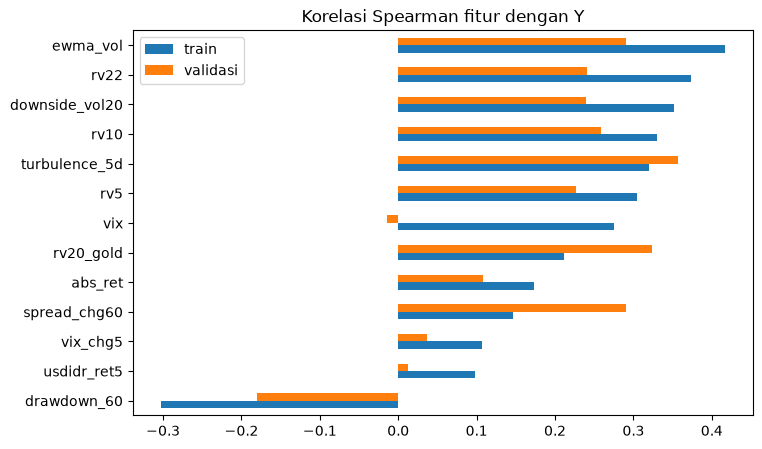

In [66]:
kor_fitur.plot.barh(figsize=(8, 5), title="Korelasi Spearman fitur dengan Y")

**Kestabilan per tahun** (2011 sampai 2024): fitur andal punya arah yang sama di sebagian besar tahun.

In [67]:
tahunan = tabel.loc["2011":"2024"]
kor_tahunan = tahunan.groupby(tahunan.index.year).corr(method="spearman")["Y"].unstack().drop(columns="Y")

Text(0.5, 1.0, 'Korelasi Spearman fitur dengan Y per tahun')

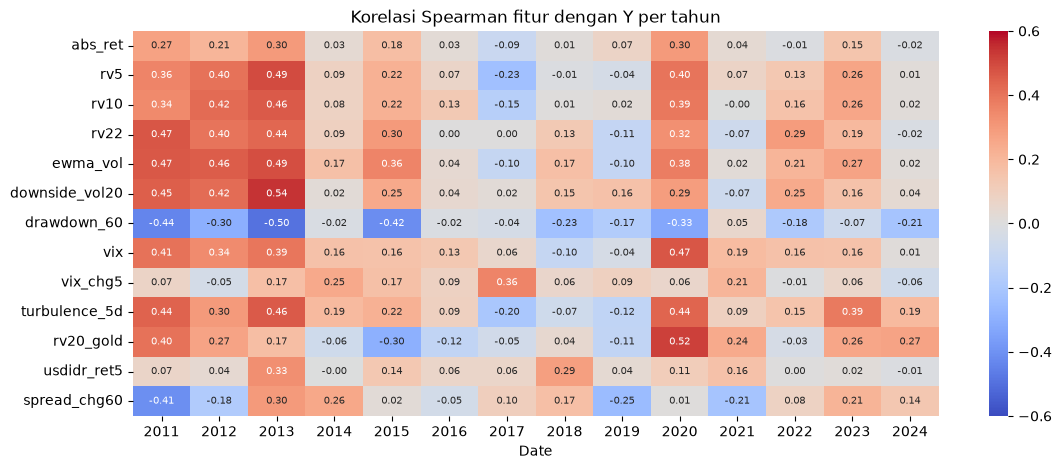

In [68]:
plt.figure(figsize=(13, 5))
sns.heatmap(kor_tahunan.T, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.6, vmax=0.6, annot_kws={"size": 7}).set_title("Korelasi Spearman fitur dengan Y per tahun")

In [69]:
np.sign(kor_tahunan).eq(np.sign(kor_fitur["train"]), axis=1).mean().sort_values().round(2).rename("porsi tahun dengan arah sama seperti train")

rv20_gold         0.57
spread_chg60      0.64
rv22              0.79
abs_ret           0.79
turbulence_5d     0.79
vix_chg5          0.79
rv5               0.79
ewma_vol          0.86
vix               0.86
usdidr_ret5       0.86
rv10              0.86
drawdown_60       0.93
downside_vol20    0.93
Name: porsi tahun dengan arah sama seperti train, dtype: float64

- **Paling konsisten:** `drawdown_60` dan `downside_vol20` (93% tahun).
- **VIX:** hampir nol di validasi, tetapi searah di 86% tahun.
- **Paling tidak stabil:** `rv20_gold` (57%), `spread_chg60` (64%).

| Hipotesis | Korelasi train / validasi | Arah sama per tahun | Kesimpulan |
|---|---|---|---|
| H1 | `ewma_vol` 0,42 / 0,29, `rv22` 0,37 / 0,24 | 79% sampai 86% | **Terbukti**, stabil |
| H2 | `downside_vol20` 0,35 / 0,24, `drawdown_60` -0,30 / -0,18 | 93% | **Terbukti**, paling konsisten |
| H3 | `vix` 0,28 / -0,01, `vix_chg5` 0,11 / 0,04 | 79% sampai 86% | Lemah di validasi |
| H4 | `turbulence_5d` 0,32 / 0,36, `rv20_gold` 0,21 / 0,32 | 57% sampai 86% | Turbulence **terbukti**, menguat |
| H5 | `spread_chg60` 0,15 / 0,29 | 64% | Tidak stabil |

**Redundansi antar fitur.** Apakah ada fitur yang sebenarnya mengukur hal yang sama?

Text(0.5, 1.0, 'Korelasi Spearman antar fitur, data train')

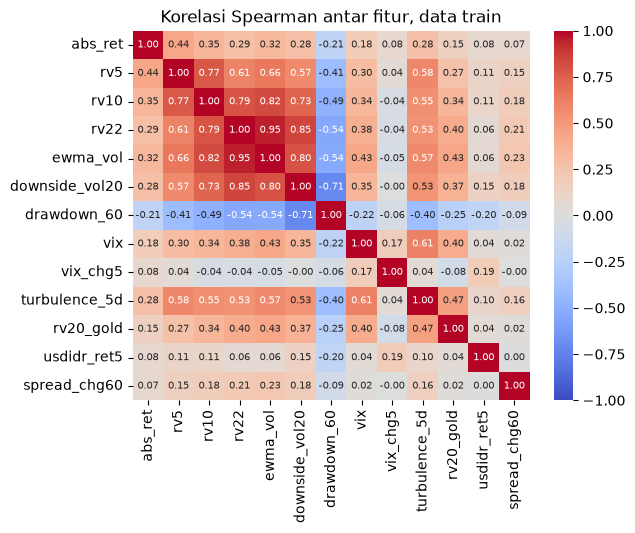

In [70]:
sns.heatmap(fitur.loc[:"2022"].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}).set_title("Korelasi Spearman antar fitur, data train")

H1 dan H2 saling berkorelasi tinggi. H3 sampai H5 lebih independen dan membawa informasi baru.

**Fitur vs Y dari waktu ke waktu**, dengan episode makro diarsir. Ini cara paling intuitif untuk melihat apakah fitur "bangun" saat volatilitas naik.

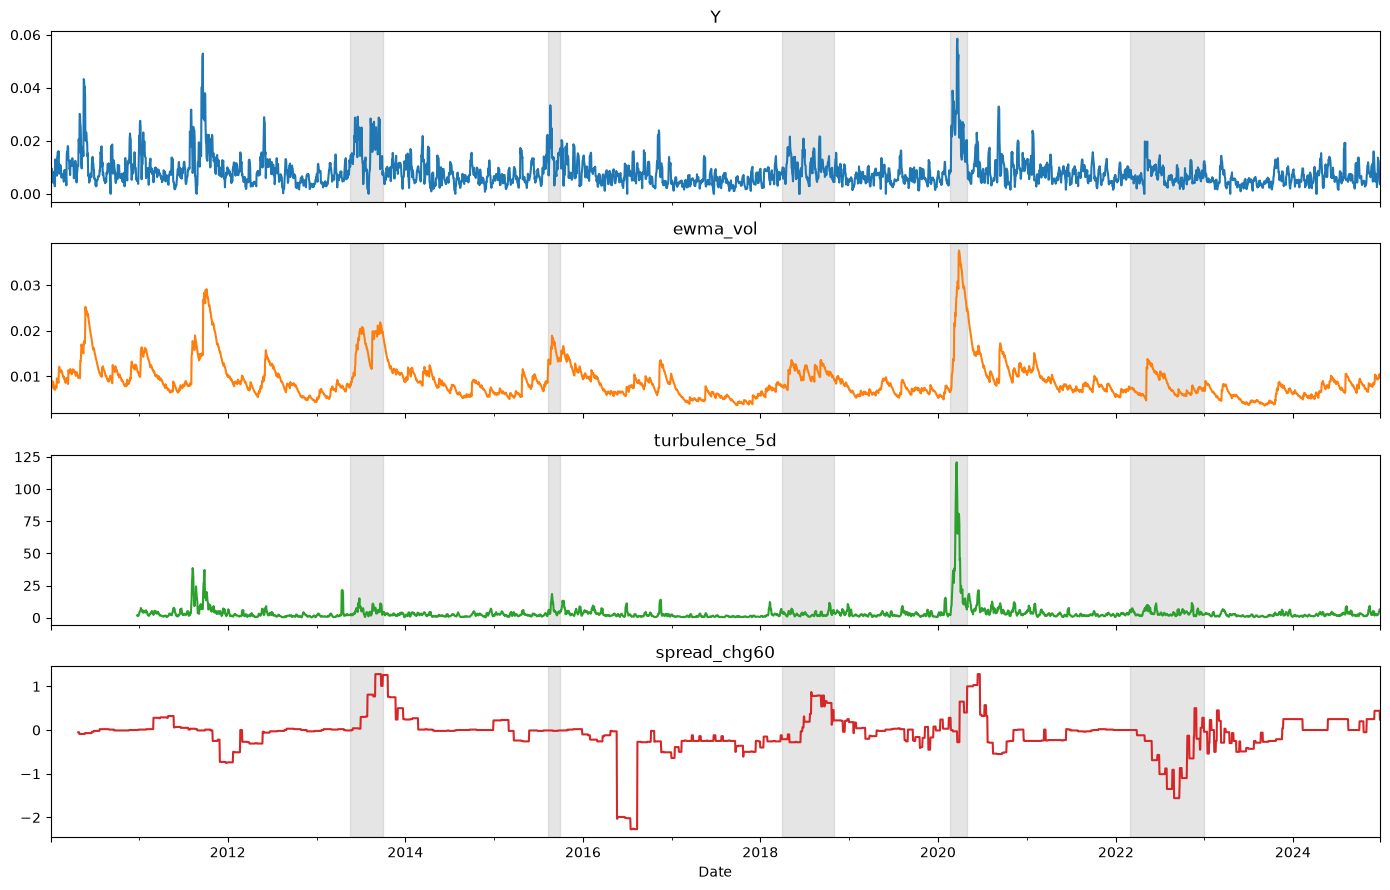

In [71]:
axes = tabel.loc[:"2024", ["Y", "ewma_vol", "turbulence_5d", "spread_chg60"]].plot(subplots=True, figsize=(14, 9), legend=False, title=["Y", "ewma_vol", "turbulence_5d", "spread_chg60"])
for ax in axes:
    for a, b in episode.values():
        ax.axvspan(a, b, color="grey", alpha=0.2)
plt.tight_layout()

`ewma_vol` dan `turbulence_5d` naik di setiap episode krisis. `spread_chg60` hanya bereaksi di 2020.

**Apakah hubungan fitur andalan dengan Y bertingkat?** Data train dibagi lima kelompok (kuintil) per fitur, lalu median Y dibandingkan. Untuk `drawdown_60`, Q1 adalah penurunan paling dalam.

In [72]:
andalan = ["turbulence_5d", "drawdown_60", "vix_chg5"]

In [73]:
tabel_tr = tabel.loc[:"2022"]
y_kuintil = pd.DataFrame({c: tabel_tr["Y"].groupby(pd.qcut(tabel_tr[c], 5, labels=["Q1 terendah", "Q2", "Q3", "Q4", "Q5 tertinggi"])).median() for c in andalan})
y_kuintil.round(4)

,turbulence_5d,drawdown_60,vix_chg5
Q1 terendah,0.0058,0.0109,0.0070
Q2,0.0069,0.0073,0.0071
Q3,0.0071,0.0069,0.0073
Q4,0.0079,0.0063,0.0072
Q5 tertinggi,0.0096,0.0066,0.0083


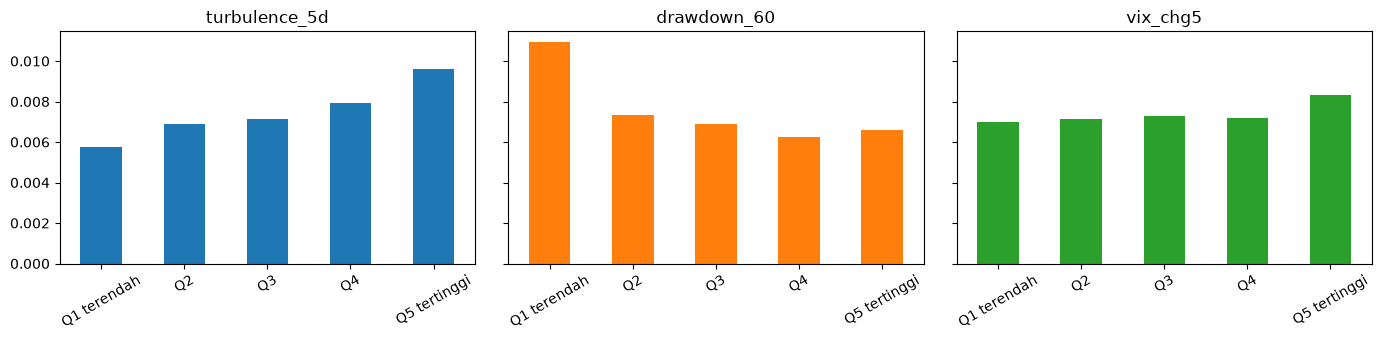

In [74]:
y_kuintil.plot.bar(subplots=True, layout=(1, 3), figsize=(14, 3.5), legend=False, sharey=True, rot=30, title=andalan)
plt.tight_layout()

- **X1 `turbulence_5d` bertingkat:** median Y 0,0058 naik ke 0,0096.
- **X2 `drawdown_60` di ujung:** kuintil terdalam 0,0109, lainnya 0,0063 sampai 0,0073.
- **X3 `vix_chg5` ambang:** datar, baru naik di Q5 (0,0083).

Kontribusi di dalam model diuji di 7.7 (ablation), 7.9 (nilai tambah), dan Bab 9 (SHAP).

## Hasil analisis dari bab ini

- H1, H2, H4 terbukti. H3 lemah di validasi. H5 tidak stabil.
- Tiga fitur andalan saling melengkapi: bertingkat, di ujung, dan ambang.

# Bab 6. Task 2: pemisahan data berurutan dan bukti anti-leakage

Kami mencoba **membobol fitur sendiri** dengan lima uji. Satu uji menemukan kebocoran.

## 6.1 Aturan pembagian data

- **Tanpa acak:** train 2010 sampai 2022, validasi 2023 sampai 2024, test 2025 ke atas.
- **Embargo 5 hari** di ujung train.
- **Tidak ada nilai yang diisi.**
- **Scaler di-`fit` hanya di data latih** (bukti di 7.3).
- **Sinyal terbit pagi t+1**, saat data S&P 500 dan VIX hari t sudah tersedia.

In [75]:
fitur_cols = fitur.columns.tolist()
tr = tabel.loc[:"2022"].dropna().iloc[:-5]
va = tabel.loc["2023":"2024"]
te = tabel.loc["2025":]

In [76]:
pd.DataFrame({"mulai": [d.index.min().date() for d in (tr, va, te)],
              "selesai": [d.index.max().date() for d in (tr, va, te)],
              "baris": [len(d) for d in (tr, va, te)]}, index=["train", "validasi", "test"])

,mulai,selesai,baris
train,2010-12-24,2022-12-23,3131
validasi,2023-01-02,2024-12-24,517
test,2025-01-02,2026-05-22,359


In [77]:
va[fitur_cols].isna().sum().sum(), te[fitur_cols].isna().sum().sum()

(np.int64(0), np.int64(0))

Train 24 Desember 2010 sampai 23 Desember 2022 (embargo). Validasi dan test tanpa fitur kosong.

## 6.2 Bukti 1: uji potong data di satu tanggal

Data sesudah 29 Juni 2018 dihapus, fitur dihitung ulang. Fitur yang mengintip masa depan akan berubah.

In [78]:
fitur_potong = buat_fitur(data.loc[:"2018-06-29"])

In [79]:
(fitur_potong - fitur.loc[:"2018-06-29"]).abs().max()

abs_ret           0.0
rv5               0.0
rv10              0.0
rv22              0.0
ewma_vol          0.0
downside_vol20    0.0
drawdown_60       0.0
vix               0.0
vix_chg5          0.0
turbulence_5d     0.0
rv20_gold         0.0
usdidr_ret5       0.0
spread_chg60      0.0
dtype: float64

Selisih maksimum seluruh fitur adalah 0. Nilai fitur pada hari t identik walaupun data setelah t tidak ada. **Tidak ada fitur yang mengambil informasi dari t+1.**

Sebagai pembanding, beginilah wujud variabel yang memang memakai masa depan. Target Y yang dihitung ulang dari data terpotong langsung kosong di 5 hari terakhir:

In [80]:
np.log(data.loc[:"2018-06-29", "IHSG"]).diff().rolling(5).std().shift(-5).tail(7)

Date
2018-06-21    0.010144
2018-06-22    0.016460
2018-06-25         NaN
2018-06-26         NaN
2018-06-27         NaN
2018-06-28         NaN
2018-06-29         NaN
Name: IHSG, dtype: float64

## 6.3 Bukti 2: uji potong data di banyak tanggal

Uji yang sama di **20 tanggal acak**.

In [81]:
rng = np.random.default_rng(42)
t_acak = rng.choice(np.arange(300, len(data) - 10), 20, replace=False)

In [82]:
max((buat_fitur(data.iloc[:t + 1]).iloc[-1] - fitur.iloc[t]).abs().max() for t in t_acak)

np.float64(0.0)

Selisih maksimum 0 di 20 tanggal.

## 6.4 Bukti 3: uji perturbasi masa depan

Harga sesudah hari t dikali angka acak 0,3 sampai 3. Fitur sampai hari t tidak boleh berubah.

In [83]:
kolom_harga = data.columns.get_indexer(["OIL", "GOLD", "USDIDR", "SP500", "IHSG", "VIX"])
selisih_acak = []
for t in t_acak[:10]:
    data_acak = data.copy()
    data_acak.iloc[t + 1:, kolom_harga] *= rng.uniform(0.3, 3.0, size=(len(data) - t - 1, len(kolom_harga)))
    selisih_acak.append((buat_fitur(data_acak).iloc[:t + 1] - fitur.iloc[:t + 1]).abs().max().max())
max(selisih_acak)

np.float64(0.0)

Selisih maksimum 0 pada 10 tanggal. Fitur pada hari t atau sebelumnya tidak bergeming walaupun seluruh harga sesudahnya diacak-acak.

## 6.5 Bukti 4: uji penundaan suku bunga

BI_rate dinaikkan 3 poin mulai 20 baris sebelum t. `spread_chg60` sampai t tidak boleh berubah. **Kontrol:** versi tanpa penundaan harus gagal.

In [84]:
kolom_bi = data.columns.get_indexer(["BI_rate"])
selisih_tunda, selisih_kontrol = [], []
for t in t_acak[:10]:
    data_bunga = data.copy()
    data_bunga.iloc[t - 20:, kolom_bi] += 3
    selisih_tunda.append((buat_fitur(data_bunga)["spread_chg60"].iloc[:t + 1] - fitur["spread_chg60"].iloc[:t + 1]).abs().max())
    tanpa_tunda = lambda d: (d["BI_rate"] - d["US_rate"]).diff(60)
    selisih_kontrol.append((tanpa_tunda(data_bunga).iloc[:t + 1] - tanpa_tunda(data).iloc[:t + 1]).abs().max())
max(selisih_tunda), max(selisih_kontrol)

(np.float64(0.0), np.float64(3.0000000000000004))

Dengan penundaan, selisihnya 0. **Tanpa penundaan, fitur berubah** (selisih 3). Uji ini memang mampu mendeteksi kebocoran, dan penundaan 21 hari terbukti bekerja.

## 6.6 Bukti 5: uji kontrol kebocoran halus pada turbulence

Kami menghitung ulang kovarian hanya sampai tanggal potong dikarenakan pada pengujian awal terdapat indikasi kebocoran

In [85]:
ret4 = np.log(data[["IHSG", "SP500", "USDIDR", "GOLD"]]).diff().fillna(0)

def turbulence_lama(sampai):
    z = (ret4 - ret4.loc[:sampai].mean()).to_numpy()
    return pd.Series(np.einsum("ni,ij,nj->n", z, np.linalg.inv(ret4.loc[:sampai].cov()), z), index=ret4.index).rolling(5).mean()

In [86]:
pd.Series({"versi lama (kovarian seluruh train)": (turbulence_lama("2022") - turbulence_lama("2018-06-29")).loc[:"2018-06-29"].abs().max(),
           "versi baru (expanding sampai kemarin)": (fitur_potong["turbulence_5d"] - fitur.loc[:"2018-06-29", "turbulence_5d"]).abs().max()})

versi lama (kovarian seluruh train)      8.105575
versi baru (expanding sampai kemarin)    0.000000
dtype: float64

**Versi lama bocor** (berubah sampai 8,1 satuan). **Versi expanding:** selisih 0.

## 6.7 Validasi silang berurutan untuk tuning

`TimeSeriesSplit` dengan `gap=5`, hanya di train.

In [87]:
cv = TimeSeriesSplit(n_splits=5, gap=5)

In [88]:
pd.DataFrame([(tr.index[a[-1]].date(), tr.index[b[0]].date(), tr.index[b[-1]].date()) for a, b in cv.split(tr)],
             columns=["akhir latih", "awal uji", "akhir uji"])

,akhir latih,awal uji,akhir uji
0,2012-12-21,2012-12-31,2014-12-29
1,2014-12-22,2014-12-30,2016-12-27
2,2016-12-20,2016-12-28,2018-12-26
3,2018-12-19,2018-12-27,2020-12-24
4,2020-12-17,2020-12-25,2022-12-23


## Hasil analisis dari bab ini

| Uji | Hasil |
|---|---|
| Potong data, 1 tanggal | selisih 0 |
| Potong data, 20 tanggal | selisih 0 |
| Perturbasi masa depan | selisih 0 |
| Penundaan suku bunga vs kontrol | 0 vs 3 |
| Turbulence lama vs expanding | **8,1 (bocor)** vs 0 |


# Bab 7. Task 3 (model dan akurasi): seberapa akurat prediksi volatilitas?

Model dipilih dari **CV berurutan di train**. Validasi hanya melapor. Walk-forward 10 tahun menguji kestabilan. Akurasi dinilai dengan tiga ukuran di 1.2: RMSE (metrik studi kasus), QLIKE, dan R2 out-of-sample.

## Model utama dan alasannya

**Ridge Regression** pada 13 fitur, karena target berisik (model fleksibel menghafal noise), fitur berkorelasi (penalti L2 membagi bobot), dan SHAP-nya eksak.

**Model yang lebih kompleks sudah diuji, dan tidak ada yang lebih baik:**

| Model | R2 out-of-fold train | AUC walk-forward | Bagian |
|---|---|---|---|
| **Ridge 13 fitur (dipakai)** | **0,338** | **0,679** | 7.2, 7.6 |
| Ridge + ramalan GJR-GARCH | 0,345 | 0,683 | B.1 (naik tipis, tidak sepadan) |
| LightGBM dituning (40 kombinasi) | 0,256 | 0,651 | B.1 |
| Random Forest dituning + GARCH | 0,296 | 0,642 | B.2 |
| GJR-GARCH + kalibrasi | 0,338 | 0,629 | B.1 |
| HAR | 0,250 | 0,586 | B.1 |

Pembanding utama: baseline naif, EWMA, HAR.

In [89]:
y_tr, y_va = tr["Y"], va["Y"]

## 7.1 Baseline

In [90]:
har_cols = ["abs_ret", "rv5", "rv22"]

In [91]:
har = LinearRegression().fit(tr[har_cols], y_tr)

In [92]:
prediksi = {"Rata-rata train": np.full(len(va), y_tr.mean()),
            "Naif rv5": va["rv5"],
            "EWMA (lambda 0,94)": va["ewma_vol"],
            "HAR (abs_ret, rv5, rv22)": har.predict(va[har_cols])}

## 7.2 Pemilihan model dan bentuk target lewat CV

Kandidat dibandingkan dengan CV berurutan di train: HAR, Ridge pada Y, Ridge pada akar Y, dan LightGBM.

In [93]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TimeSeriesSplit(n_splits=5, gap=5)))
lgbm_awal = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.01, num_leaves=7, min_child_samples=50, subsample=0.7,
                              subsample_freq=1, colsample_bytree=0.6, reg_lambda=5, random_state=42, verbose=-1)

In [94]:
kandidat_cv = {"HAR": (LinearRegression(), har_cols),
               "Ridge, target Y": (ridge, fitur_cols),
               "Ridge, target akar Y": (TransformedTargetRegressor(ridge, func=np.sqrt, inverse_func=np.square), fitur_cols),
               "LightGBM, target akar Y": (TransformedTargetRegressor(lgbm_awal, func=np.sqrt, inverse_func=np.square), fitur_cols)}

In [95]:
pd.DataFrame({k: {"RMSE CV (rata-rata fold)": -cross_val_score(m, tr[c], y_tr, cv=cv, scoring="neg_root_mean_squared_error").mean(),
                  "R2 CV (rata-rata fold)": cross_val_score(m, tr[c], y_tr, cv=cv, scoring="r2").mean()} for k, (m, c) in kandidat_cv.items()}).T.round(5)

,RMSE CV (rata-rata fold),R2 CV (rata-rata fold)
HAR,0.00457,0.14521
"Ridge, target Y",0.00432,0.21541
"Ridge, target akar Y",0.00435,0.22590
"LightGBM, target akar Y",0.00454,0.15851


- **Ridge mengalahkan HAR** (RMSE 0,00432 vs 0,00457) dan LightGBM (0,00454).
- **Target Y** dipilih daripada akar Y.

R2 di tabel ini rata-rata per fold (Ridge 0,215). Di 7.5 dan Lampiran B dipakai **R2 out-of-fold** gabungan (0,34).

## 7.3 Hyperparameter tuning

`RidgeCV`: 25 nilai `alpha` (0,01 sampai 10.000), CV berurutan **hanya di train**. Pembanding juga dituning: LightGBM 40 kombinasi (B.1), Random Forest (B.2).

In [96]:
model = clone(ridge).fit(tr[fitur_cols], y_tr)

In [97]:
model[-1].alpha_

np.float64(562.341325190349)

**Kurva tuning `alpha`.** RMSE CV pada fold berurutan yang sama untuk setiap kandidat `alpha`. Garis putus-putus menandai `alpha` yang dipilih `RidgeCV`.

In [98]:
alpha_grid = np.logspace(-2, 4, 25)
rmse_alpha = pd.Series({a: -cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)), tr[fitur_cols], y_tr, cv=cv, scoring="neg_root_mean_squared_error").mean()
                        for a in alpha_grid})
rmse_alpha.round(5)

0.010000        0.00442
0.017783        0.00442
0.031623        0.00442
0.056234        0.00442
0.100000        0.00441
0.177828        0.00441
0.316228        0.00441
0.562341        0.00441
1.000000        0.00441
1.778279        0.00441
3.162278        0.00441
5.623413        0.00441
10.000000       0.00440
17.782794       0.00439
31.622777       0.00438
56.234133       0.00437
100.000000      0.00435
177.827941      0.00434
316.227766      0.00432
562.341325      0.00431
1000.000000     0.00431
1778.279410     0.00432
3162.277660     0.00436
5623.413252     0.00444
10000.000000    0.00457
dtype: float64

Text(0, 0.5, 'RMSE CV')

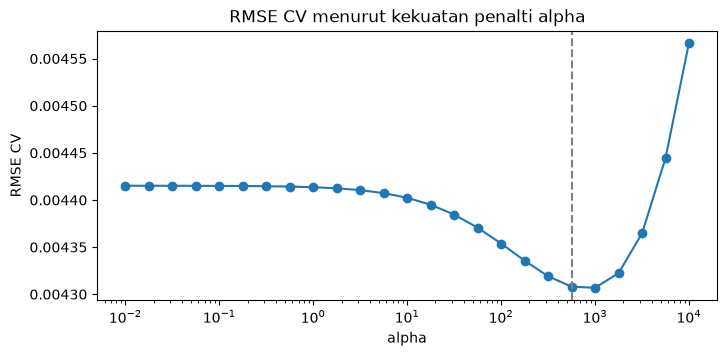

In [99]:
ax = rmse_alpha.plot(logx=True, marker="o", figsize=(8, 3.5), title="RMSE CV menurut kekuatan penalti alpha")
ax.axvline(model[-1].alpha_, ls="--", color="gray")
ax.set_xlabel("alpha"); ax.set_ylabel("RMSE CV")

Optimum di alpha 562 sampai 1.000 (RMSE 0,00431), di dasar kurva, bukan di tepi grid. Kurva ini memakai scaler yang di-fit ulang per fold.

**Pencarian kombinasi hyperparameter.** Alpha dicari bersama penskala (Standard, Robust, MinMax) dan bentuk target (Y atau akar Y): 150 kombinasi, CV berurutan hanya di train.

In [100]:
kombinasi = TransformedTargetRegressor(make_pipeline(StandardScaler(), Ridge()))
grid_kombinasi = [{"regressor__standardscaler": [StandardScaler(), RobustScaler(), MinMaxScaler()], "regressor__ridge__alpha": np.logspace(-2, 4, 25),
                   "func": [f], "inverse_func": [g]} for f, g in [(None, None), (np.sqrt, np.square)]]
cari = GridSearchCV(kombinasi, grid_kombinasi, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(tr[fitur_cols], y_tr)

In [101]:
hasil_cari = pd.DataFrame(cari.cv_results_).assign(
    penskala=lambda d: d["param_regressor__standardscaler"].astype(str).str.replace("()", "", regex=False),
    target=lambda d: np.where(d["param_func"].astype(str).str.contains("sqrt"), "akar Y", "Y"),
    alpha=lambda d: d["param_regressor__ridge__alpha"].astype(float), rmse=lambda d: -d["mean_test_score"],
    galat_baku=lambda d: d["std_test_score"] / np.sqrt(cv.n_splits))
hasil_cari.loc[hasil_cari.groupby(["penskala", "target"])["rmse"].idxmin(), ["penskala", "target", "alpha", "rmse", "galat_baku"]].sort_values("rmse").round(5)

,penskala,target,alpha,rmse,galat_baku
135,StandardScaler,akar Y,1000.00000,0.00430,0.00039
60,StandardScaler,Y,1000.00000,0.00431,0.00035
116,MinMaxScaler,akar Y,17.78279,0.00431,0.00040
41,MinMaxScaler,Y,17.78279,0.00432,0.00037
61,RobustScaler,Y,1000.00000,0.00433,0.00035
136,RobustScaler,akar Y,1000.00000,0.00433,0.00039


In [102]:
terbaik = hasil_cari.loc[hasil_cari["rmse"].idxmin()]
dipakai = hasil_cari.query("penskala == 'StandardScaler' and target == 'Y'")["rmse"].min()
pd.Series({"RMSE terbaik": terbaik["rmse"], "batas satu galat baku": terbaik["rmse"] + terbaik["galat_baku"],
           "RMSE konfigurasi dipakai (StandardScaler, Y)": dipakai}).round(5)

RMSE terbaik                                    0.00430
batas satu galat baku                           0.00469
RMSE konfigurasi dipakai (StandardScaler, Y)    0.00431
dtype: float64

Semua kombinasi hampir sama (RMSE 0,00430 sampai 0,00433). Kombinasi terbaik secara angka (akar Y, alpha 1.000) hanya 0,00001 di bawah konfigurasi yang dipakai, jauh di dalam batas satu galat baku (0,00469). Dengan **aturan satu galat baku** (Hastie, Tibshirani, dan Friedman, 2009), dipilih konfigurasi paling sederhana: **StandardScaler dengan target Y**, yang juga membuat SHAP terbaca langsung dalam skala volatilitas. Alpha 562 dan 1.000 setara (kurva di atas).

**Bukti anti-leakage preprocessing.** Rata-rata yang dipelajari scaler harus sama dengan rata-rata data train, dan berbeda dari rata-rata seluruh data.

In [103]:
pd.DataFrame({"scaler": model[0].mean_, "train": tr[fitur_cols].mean(), "seluruh data": tabel[fitur_cols].mean()}, index=fitur_cols).round(4).head(6)

,scaler,train,seluruh data
abs_ret,0.0069,0.0069,0.0070
rv5,0.0085,0.0085,0.0086
rv10,0.0089,0.0089,0.0090
rv22,0.0092,0.0092,0.0092
ewma_vol,0.0093,0.0093,0.0094
downside_vol20,0.0064,0.0064,0.0064


In [104]:
np.allclose(model[0].mean_, tr[fitur_cols].mean())

True

**Koefisien** pada fitur yang sudah distandarkan (satu satuan = satu simpangan baku fitur). Nilai positif menaikkan prediksi Y.

In [105]:
pd.Series(model[-1].coef_, index=fitur_cols).sort_values().round(5)

drawdown_60      -0.00079
rv22             -0.00015
rv5               0.00010
spread_chg60      0.00021
abs_ret           0.00025
usdidr_ret5       0.00036
rv10              0.00036
rv20_gold         0.00037
vix_chg5          0.00040
vix               0.00041
downside_vol20    0.00047
ewma_vol          0.00057
turbulence_5d     0.00067
dtype: float64

Semua koefisien positif kecuali `drawdown_60` (-0,00079, sesuai H2: makin dalam penurunan, makin tinggi prediksi) dan `rv22` (kecil, perannya diambil `ewma_vol`). Koefisien positif terbesar: `turbulence_5d` (0,00067).

## 7.4 Evaluasi di data validasi

In [106]:
pred_va = pd.Series(model.predict(va[fitur_cols]), index=va.index)

In [107]:
prediksi["Ridge (model utama)"] = pred_va

In [108]:
hasil = pd.DataFrame({k: {"RMSE": root_mean_squared_error(y_va, p), "MAE": mean_absolute_error(y_va, p), "R2": r2_score(y_va, p)} for k, p in prediksi.items()}).T
hasil["vs naif rv5 (%)"] = (1 - hasil["RMSE"] / hasil.loc["Naif rv5", "RMSE"]) * 100
hasil.round(5)

,RMSE,MAE,R2,vs naif rv5 (%)
Rata-rata train,0.00394,0.00347,-0.53546,2.22585
Naif rv5,0.00403,0.00297,-0.60617,0.00000
"EWMA (lambda 0,94)",0.00329,0.00258,-0.06573,18.54301
"HAR (abs_ret, rv5, rv22)",0.00329,0.00263,-0.06952,18.39831
Ridge (model utama),0.00322,0.00263,-0.02179,20.24022


- RMSE 0,00322, **20,2% di bawah naif rv5** (0,00403).
- Sekitar 2% di bawah EWMA dan HAR (0,00329). Dua tahun tenang terlalu pendek untuk membuktikan selisih sekecil ini. Pembuktiannya di walk-forward 10 tahun (7.6).
- R2 sklearn -0,022, tertinggi di antara pembanding (dibedah di 7.5).

**Apakah selisihnya signifikan?** Uji Diebold-Mariano: rata-rata selisih galat kuadrat diuji terhadap nol, dengan galat baku HAC (lag 5) karena window Y tumpang tindih. Selisih negatif berarti Ridge lebih akurat.

In [109]:
def uji_dm(y, p1, p2):
    d = (np.asarray(y) - np.asarray(p1)) ** 2 - (np.asarray(y) - np.asarray(p2)) ** 2
    hasil = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return pd.Series({"selisih MSE (x1e6)": hasil.params[0] * 1e6, "t": hasil.tvalues[0], "p-value": hasil.pvalues[0]})

In [110]:
pd.DataFrame({k: uji_dm(y_va, pred_va, prediksi[k]) for k in ["Rata-rata train", "Naif rv5", "EWMA (lambda 0,94)", "HAR (abs_ret, rv5, rv22)"]}).T.round(3)

,selisih MSE (x1e6),t,p-value
Rata-rata train,-5.204,-5.452,0.000
Naif rv5,-5.920,-3.359,0.001
"EWMA (lambda 0,94)",-0.445,-0.620,0.535
"HAR (abs_ret, rv5, rv22)",-0.484,-0.995,0.320


Ridge **signifikan lebih akurat** daripada rata-rata train (p < 0,001) dan naif rv5 (p = 0,001). Terhadap EWMA dan HAR belum signifikan di dua tahun ini (lihat 7.6).

<Axes: title={'center': 'Validasi 2023 sampai 2024'}, xlabel='Date'>

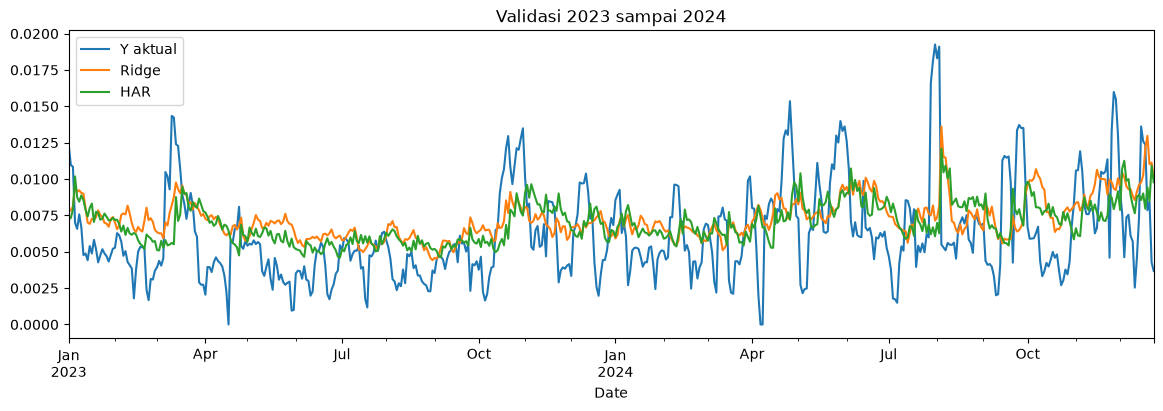

In [111]:
pd.DataFrame({"Y aktual": y_va, "Ridge": pred_va, "HAR": prediksi["HAR (abs_ret, rv5, rv22)"]}).plot(figsize=(14, 4), title="Validasi 2023 sampai 2024")

Prediksi lebih halus daripada Y dan **tidak mengikuti lonjakan** (April, Juli, November 2024). Model mengenali pasar yang sedang bergejolak, bukan guncangan pertama.

## 7.5 Seberapa jauh volatilitas bisa ditangkap?

Kelemahan model atau batas data? Empat pemeriksaan.

**(a) Dibanding tebakan konstan di rata-rata validasi.**

In [112]:
pd.Series({"RMSE Ridge": root_mean_squared_error(y_va, pred_va),
           "RMSE tebakan konstan = rata-rata validasi": root_mean_squared_error(y_va, np.full(len(y_va), y_va.mean()))}).round(5)

RMSE Ridge                                   0.00322
RMSE tebakan konstan = rata-rata validasi    0.00318
dtype: float64

In [113]:
r2_score(y_va, pred_va)

-0.021785089970951965

RMSE Ridge (0,00322) sedikit di atas tebakan konstan (0,00318), tetapi tebakan itu memakai rata-rata validasi yang belum diketahui saat memprediksi. Pembanding yang adil di bawah.

**R2 out-of-sample** (ukuran ketiga di 1.2), ditambah R2 Mincer-Zarnowitz (kuadrat korelasi prediksi dengan Y) sebagai pelengkap.

In [114]:
mse = lambda p: np.mean((y_va - np.asarray(p)) ** 2)
pd.DataFrame({k: {"R2 sklearn": r2_score(y_va, p), "R2 out-of-sample": 1 - mse(p) / mse(prediksi["Rata-rata train"]),
                  "R2 Mincer-Zarnowitz": np.corrcoef(p, y_va)[0, 1] ** 2}
              for k, p in prediksi.items() if k != "Rata-rata train"}).T.round(3)

,R2 sklearn,R2 out-of-sample,R2 Mincer-Zarnowitz
Naif rv5,-0.606,-0.046,0.041
"EWMA (lambda 0,94)",-0.066,0.306,0.052
"HAR (abs_ret, rv5, rv22)",-0.070,0.303,0.043
Ridge (model utama),-0.022,0.335,0.104


**Dari mana R2 sklearn yang negatif?** Kami pecah galat validasi menjadi bias level dan sisanya.

In [115]:
pd.Series({"rata-rata Y validasi": y_va.mean(), "rata-rata prediksi Ridge": pred_va.mean(),
           "porsi MSE dari bias": (pred_va - y_va).mean() ** 2 / mse(pred_va),
           "R2 sklearn bila bias dihapus (diagnosis saja)": r2_score(y_va, pred_va - (pred_va - y_va).mean())}).round(4)

rata-rata Y validasi                             0.0062
rata-rata prediksi Ridge                         0.0073
porsi MSE dari bias                              0.1126
R2 sklearn bila bias dihapus (diagnosis saja)    0.0933
dtype: float64

**Ridge terbaik:** R2 out-of-sample 0,335 (EWMA 0,306, HAR 0,303), Mincer-Zarnowitz 0,104 (sekitar dua kali pembanding).

R2 sklearn negatif karena **bias level**: prediksi rata-rata 0,0073, Y 0,0062. Penalti menarik prediksi ke rata-rata train yang lebih bergejolak. Koreksinya diuji di Lampiran D.

**(b) Noise bawaan Y.** Simulasi: volatilitas sebenarnya konstan, Y dihitung dari 5 return acak.

In [116]:
rng = np.random.default_rng(0)
y_normal = rng.standard_normal((200000, 5)).std(axis=1, ddof=1)
y_normal.std() / y_normal.mean()

np.float64(0.3635069599658749)

In [117]:
y_gemuk = (rng.standard_t(4, (200000, 5)) / np.sqrt(2)).std(axis=1, ddof=1)
y_gemuk.std() / y_gemuk.mean()

np.float64(0.5463693572006771)

Walau volatilitas konstan, Y berfluktuasi **36% sampai 55%** dari rata-ratanya. Di validasi 51%, setara noise murni.

**Batas bawah RMSE** untuk model yang tahu volatilitas sebenarnya.

In [118]:
pd.Series({"batas bawah, return normal": y_normal.std() / y_normal.mean() * y_va.mean(),
           "batas bawah, ekor gemuk (t4)": y_gemuk.std() / y_gemuk.mean() * y_va.mean(),
           "RMSE Ridge": root_mean_squared_error(y_va, pred_va)}).round(5)

batas bawah, return normal      0.00225
batas bawah, ekor gemuk (t4)    0.00337
RMSE Ridge                      0.00322
dtype: float64

Batas bawah 0,00225 sampai 0,00337. **Ridge (0,00322) sudah di dalamnya.** Hambatannya di target, bukan algoritma.

**(c) Prediksi out-of-fold 2013 sampai 2022**, periode penuh krisis.

In [119]:
oof = pd.concat([pd.Series(clone(model).fit(tr[fitur_cols].iloc[a], y_tr.iloc[a]).predict(tr[fitur_cols].iloc[b]), index=tr.index[b])
                 for a, b in cv.split(tr)])

In [120]:
r2_score(y_tr.loc[oof.index], oof)

0.3375187946282735

<Axes: title={'center': 'Prediksi out-of-fold, 2013 sampai 2022'}, xlabel='Date'>

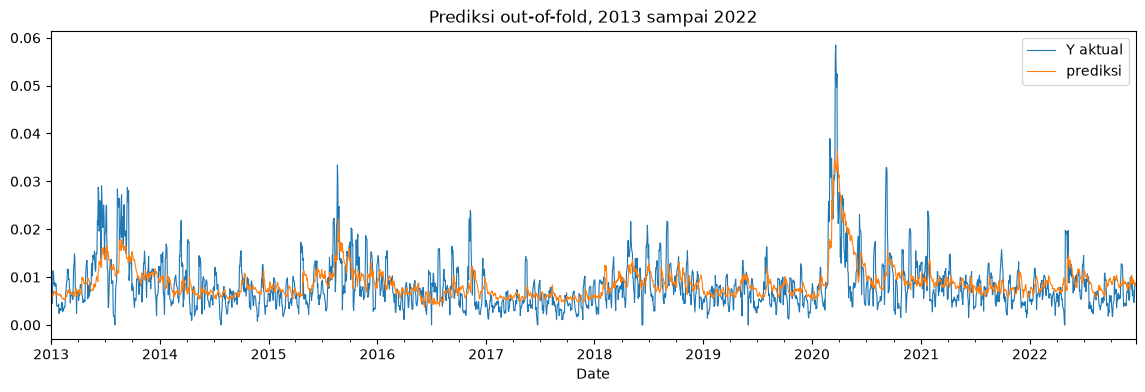

In [121]:
pd.DataFrame({"Y aktual": y_tr.loc[oof.index], "prediksi": oof}).plot(figsize=(14, 4), lw=0.8, title="Prediksi out-of-fold, 2013 sampai 2022")

R2 out-of-fold **0,34**. Prediksi mengikuti gelombang volatilitas krisis, tetapi bereaksi setelah guncangan terlihat.

**(d) Apakah prediksi tinggi diikuti Y tinggi?** Prediksi dibagi 10 desil.

<Axes: title={'center': 'Rata-rata Y aktual per desil prediksi'}, xlabel='prediksi'>

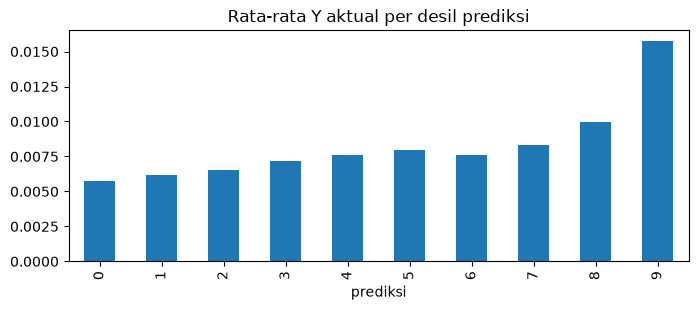

In [122]:
kal = pd.DataFrame({"Y": y_tr.loc[oof.index], "prediksi": oof})
kal.groupby(pd.qcut(kal["prediksi"], 10, labels=False))["Y"].mean().plot.bar(figsize=(8, 3), title="Rata-rata Y aktual per desil prediksi")

In [123]:
kal.groupby(pd.qcut(kal["prediksi"], 10, labels=False))["Y"].mean().round(4)

prediksi
0    0.0057
1    0.0062
2    0.0065
3    0.0072
4    0.0076
5    0.0079
6    0.0076
7    0.0083
8    0.0099
9    0.0157
Name: Y, dtype: float64

Y aktual naik hampir monoton dari 0,0057 ke **0,0157** (2,8 kali).

**Kesimpulan 7.5:** model menangkap **rezim** volatilitas, bukan **waktu tepat** lonjakan.

## 7.6 Evaluasi walk-forward per tahun

Tiap tahun 2015 sampai 2024: latih pada data sebelumnya (embargo 5 hari), uji pada tahun itu. Kejadian untuk AUC: Y di atas persentil 80 data latih.

In [124]:
baris, wf_pred, wf_model = [], [], {}
for tahun in range(2015, 2025):
    tr_t, te_t = tabel.loc[:str(tahun - 1)].dropna().iloc[:-5], tabel.loc[str(tahun)]
    kej_t = te_t["Y"] > tr_t["Y"].quantile(0.8)
    wf_model[tahun] = clone(ridge).fit(tr_t[fitur_cols], tr_t["Y"])
    skor_t = {"Ridge": wf_model[tahun].predict(te_t[fitur_cols]), "EWMA": te_t["ewma_vol"],
              "HAR": LinearRegression().fit(tr_t[har_cols], tr_t["Y"]).predict(te_t[har_cols]), "naif rv5": te_t["rv5"]}
    wf_pred.append(pd.DataFrame(skor_t, index=te_t.index).assign(Y=te_t["Y"], ambang_kejadian=tr_t["Y"].quantile(0.9)))
    baris.append({"tahun": tahun, "kejadian": kej_t.sum(),
                  **{f"RMSE {k}": root_mean_squared_error(te_t["Y"], v) for k, v in skor_t.items()},
                  **{f"AUC {k}": roc_auc_score(kej_t, v) for k, v in skor_t.items()},
                  **{f"PR {k}": average_precision_score(kej_t, v) for k, v in skor_t.items()}})
wf = pd.DataFrame(baris).set_index("tahun")
wf_pred = pd.concat(wf_pred)

In [125]:
wf[["kejadian"] + [c for c in wf.columns if c.startswith("RMSE")]].round(5)

,kejadian,RMSE Ridge,RMSE EWMA,RMSE HAR,RMSE naif rv5
tahun,,,,,
2015,65,0.00471,0.00509,0.00496,0.00637
2016,24,0.00399,0.00426,0.00414,0.00522
2017,5,0.00261,0.00275,0.00301,0.00351
2018,54,0.00418,0.00426,0.00418,0.00556
2019,10,0.00293,0.00296,0.00299,0.00384
2020,104,0.00729,0.00878,0.00832,0.00937
2021,24,0.00333,0.00372,0.00358,0.00472
2022,23,0.00352,0.00345,0.00336,0.00431
2023,11,0.00272,0.00270,0.00276,0.00297


In [126]:
wf[[c for c in wf.columns if c.startswith("AUC") or c.startswith("PR")]].round(3)

,AUC Ridge,AUC EWMA,AUC HAR,AUC naif rv5,PR Ridge,PR EWMA,PR HAR,PR naif rv5
tahun,,,,,,,,
2015,0.721,0.742,0.738,0.704,0.571,0.505,0.493,0.461
2016,0.581,0.523,0.537,0.548,0.129,0.094,0.134,0.108
2017,0.652,0.305,0.567,0.638,0.084,0.016,0.025,0.030
2018,0.608,0.642,0.609,0.543,0.351,0.274,0.289,0.286
2019,0.682,0.392,0.425,0.486,0.083,0.037,0.037,0.040
2020,0.725,0.695,0.705,0.726,0.727,0.693,0.710,0.679
2021,0.670,0.599,0.597,0.525,0.247,0.166,0.157,0.104
2022,0.624,0.449,0.474,0.440,0.208,0.143,0.169,0.193
2023,0.941,0.624,0.697,0.816,0.372,0.059,0.095,0.173


In [127]:
wf.drop(columns="kejadian").mean().round(4)

RMSE Ridge       0.0039
RMSE EWMA        0.0042
RMSE HAR         0.0041
RMSE naif rv5    0.0051
AUC Ridge        0.6787
AUC EWMA         0.5488
AUC HAR          0.5856
AUC naif rv5     0.5969
PR Ridge         0.2945
PR EWMA          0.2119
PR HAR           0.2250
PR naif rv5      0.2231
dtype: float64

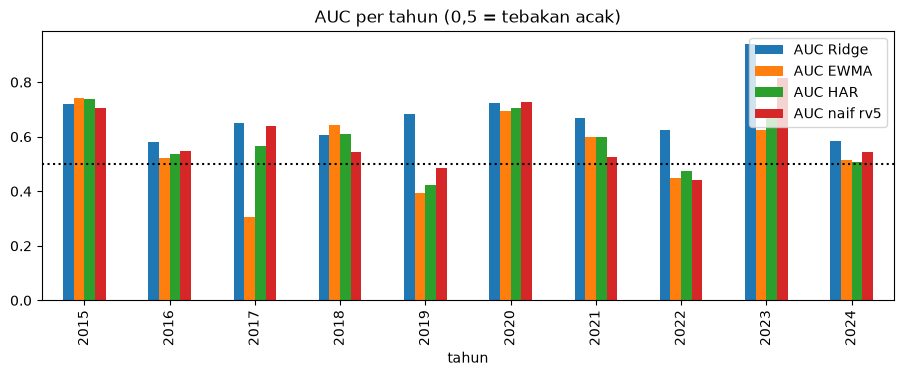

In [128]:
wf[[c for c in wf.columns if c.startswith("AUC")]].plot.bar(figsize=(11, 3.5), title="AUC per tahun (0,5 = tebakan acak)").axhline(0.5, color="black", ls=":")

In [129]:
pd.Series({"tahun Ridge unggul atas EWMA (AUC)": (wf["AUC Ridge"] > wf["AUC EWMA"]).sum(),
           "tahun Ridge unggul atas HAR (AUC)": (wf["AUC Ridge"] > wf["AUC HAR"]).sum(),
           "tahun Ridge unggul atas naif rv5 (AUC)": (wf["AUC Ridge"] > wf["AUC naif rv5"]).sum(),
           "tahun Ridge unggul atas EWMA (RMSE)": (wf["RMSE Ridge"] < wf["RMSE EWMA"]).sum(),
           "tahun Ridge unggul atas HAR (RMSE)": (wf["RMSE Ridge"] < wf["RMSE HAR"]).sum()})

tahun Ridge unggul atas EWMA (AUC)        8
tahun Ridge unggul atas HAR (AUC)         8
tahun Ridge unggul atas naif rv5 (AUC)    9
tahun Ridge unggul atas EWMA (RMSE)       8
tahun Ridge unggul atas HAR (RMSE)        9
dtype: int64

- **AUC:** Ridge 0,679, naif rv5 0,597, HAR 0,586, EWMA 0,549. Ridge unggul di 8 dari 10 tahun.
- **RMSE:** Ridge 0,0039, HAR 0,0041, EWMA 0,0042, naif 0,0051.
- Peluang menang 8 dari 10 tahun secara kebetulan hanya 5,5%.

**Uji Diebold-Mariano pada seluruh walk-forward.** Dengan 2.400-an hari dari sepuluh tahun yang berbeda rezim, uji ini jauh lebih bertenaga daripada validasi dua tahun.

In [130]:
pd.DataFrame({k: uji_dm(wf_pred["Y"], wf_pred["Ridge"], wf_pred[k]) for k in ["EWMA", "HAR", "naif rv5"]}).T.round(3)

,selisih MSE (x1e6),t,p-value
EWMA,-3.492,-4.357,0.000
HAR,-2.405,-1.833,0.067
naif rv5,-11.908,-6.715,0.000


Ridge **signifikan lebih akurat** daripada EWMA dan naif rv5 (p < 0,001). Terhadap HAR p = 0,067 dengan MSE.

**Apakah R2 negatif hanya terjadi di validasi?** R2 sklearn dihitung per tahun walk-forward untuk semua model.

In [131]:
pd.DataFrame({k: wf_pred.groupby(wf_pred.index.year).apply(lambda g: r2_score(g["Y"], g[k])) for k in ["Ridge", "EWMA", "HAR", "naif rv5"]}).round(3)

,Ridge,EWMA,HAR,naif rv5
Date,,,,
2015,0.190,0.051,0.101,-0.484
2016,-0.057,-0.204,-0.138,-0.808
2017,-0.316,-0.463,-0.751,-1.387
2018,-0.055,-0.095,-0.057,-0.870
2019,-0.185,-0.206,-0.231,-1.028
2020,0.427,0.170,0.255,0.054
2021,0.044,-0.194,-0.105,-0.919
2022,-0.137,-0.091,-0.035,-0.703
2023,-0.070,-0.050,-0.096,-0.273


R2 sklearn negatif di 7 sampai 9 dari 10 tahun **untuk semua model**. Jadi R2 validasi negatif adalah sifat target, bukan kelemahan Ridge.

**QLIKE** (ukuran kedua di 1.2) dengan uji Diebold-Mariano yang sama. Naif rv5 tidak diuji (bernilai 0 saat libur panjang).

In [132]:
qlike = lambda h: np.log(h ** 2) + wf_pred["Y"] ** 2 / h ** 2
hasil_ql = {}
for k in ["EWMA", "HAR"]:
    selisih_ql = qlike(wf_pred["Ridge"]) - qlike(wf_pred[k])
    dm_ql = sm.OLS(selisih_ql.to_numpy(), np.ones(len(selisih_ql))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    hasil_ql[k] = {"selisih QLIKE": dm_ql.params[0], "t": dm_ql.tvalues[0], "p-value": dm_ql.pvalues[0]}
pd.DataFrame(hasil_ql).T.round(4)

,selisih QLIKE,t,p-value
EWMA,-0.0562,-2.4527,0.0142
HAR,-0.0593,-2.5808,0.0099


Dengan QLIKE, Ridge **signifikan lebih akurat** daripada HAR (p = 0,010) dan EWMA (p = 0,014). Dengan MSE, terhadap HAR p = 0,067.

**Hari berbahaya:** Y di atas persentil 90 dari Y **sebelum** tahun itu. Dipakai di 7.8 dan Bab 8.

In [133]:
kej_all = wf_pred["Y"] > wf_pred["ambang_kejadian"]

## 7.7 Kontribusi tiap hipotesis: uji ablation walk-forward

Apakah model **butuh** tiap hipotesis? Satu kelompok fitur dibuang, model dilatih ulang, lalu dibandingkan dengan model lengkap.

In [134]:
hipotesis = {"H1 volatilitas berkelompok": ["abs_ret", "rv5", "rv10", "rv22", "ewma_vol"], "H2 sisi turun": ["downside_vol20", "drawdown_60"],
             "H3 rasa takut global": ["vix", "vix_chg5"], "H4 stres lintas aset": ["turbulence_5d", "rv20_gold", "usdidr_ret5"],
             "H5 suku bunga": ["spread_chg60"]}

In [135]:
baris_abl = []
for nama, buang in {"lengkap": [], **hipotesis}.items():
    kolom_abl = [c for c in fitur_cols if c not in buang]
    for tahun in range(2015, 2025):
        tr_t, te_t = tabel.loc[:str(tahun - 1)].dropna().iloc[:-5], tabel.loc[str(tahun)]
        p = clone(ridge).fit(tr_t[kolom_abl], tr_t["Y"]).predict(te_t[kolom_abl])
        baris_abl.append({"dibuang": nama, "tahun": tahun, "RMSE": root_mean_squared_error(te_t["Y"], p),
                          "AUC": roc_auc_score(te_t["Y"] > tr_t["Y"].quantile(0.8), p)})
abl = pd.DataFrame(baris_abl)

In [136]:
rmse_abl = abl.pivot(index="tahun", columns="dibuang", values="RMSE")
auc_abl = abl.pivot(index="tahun", columns="dibuang", values="AUC")
pd.DataFrame({"RMSE naik (%)": (rmse_abl.mean() / rmse_abl["lengkap"].mean() - 1) * 100,
              "AUC turun": auc_abl["lengkap"].mean() - auc_abl.mean(),
              "tahun RMSE memburuk (dari 10)": rmse_abl.gt(rmse_abl["lengkap"], axis=0).sum(),
              "tahun AUC memburuk (dari 10)": auc_abl.lt(auc_abl["lengkap"], axis=0).sum()}).drop("lengkap").round(3)

,RMSE naik (%),AUC turun,tahun RMSE memburuk (dari 10),tahun AUC memburuk (dari 10)
dibuang,,,,
H1 volatilitas berkelompok,0.497,-0.013,6,4
H2 sisi turun,0.699,0.025,8,7
H3 rasa takut global,-0.172,0.030,5,7
H4 stres lintas aset,1.381,0.015,8,7
H5 suku bunga,-0.046,0.001,6,7


| Hipotesis dibuang | RMSE | AUC | Arti |
|---|---|---|---|
| H4 stres lintas aset | naik 1,4% (8 dari 10 tahun) | turun 0,015 | Kontribusi akurasi **paling konsisten** |
| H2 sisi turun | naik 0,7% (8 tahun) | turun 0,025 | Akurasi **dan** hari berbahaya |
| H3 rasa takut global | turun 0,2% | turun 0,030 | **Paling membantu mengenali hari berbahaya** |
| H1 volatilitas berkelompok | naik 0,5% | naik 0,013 | Tumpang tindih dengan H2 dan H4 |
| H5 suku bunga | turun 0,05% | turun 0,001 | Tidak terbukti |

**H2, H3, H4 tidak tergantikan**, dan ketiga fitur andalan berasal dari sana.

## 7.8 Analisis robust dan skala data

Tujuh varian penskalaan dan loss, hanya sebagai **uji ketahanan**.

In [137]:
def wf_prediksi(tab, kolom, buat):
    hasil = []
    for t in range(2015, 2025):
        tr_t = tab.loc[:str(t - 1)].dropna(subset=kolom + ["Y"]).iloc[:-5]
        te_t = tab.loc[str(t)]
        hasil.append(pd.Series(buat().fit(tr_t[kolom].to_numpy(), tr_t["Y"]).predict(te_t[kolom].to_numpy()), index=te_t.index))
    return pd.concat(hasil)

In [138]:
idx_miring = [fitur_cols.index(c) for c in ["abs_ret", "rv5", "rv10", "rv22", "ewma_vol", "downside_vol20", "vix", "turbulence_5d", "rv20_gold"]]

def log_miring(X):
    X = X.copy()
    X[:, idx_miring] = np.log(np.clip(X[:, idx_miring], 1e-6, None))
    return X

ridge_cv = lambda: RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TimeSeriesSplit(n_splits=5, gap=5))
huber_cv = lambda: GridSearchCV(HuberRegressor(max_iter=3000), {"alpha": np.logspace(-6, 0, 7)}, cv=TimeSeriesSplit(n_splits=5, gap=5), scoring="neg_root_mean_squared_error")
varian = {"StandardScaler (dipakai)": lambda: make_pipeline(StandardScaler(), ridge_cv()),
          "RobustScaler (median dan IQR)": lambda: make_pipeline(RobustScaler(), ridge_cv()),
          "MinMaxScaler": lambda: make_pipeline(MinMaxScaler(), ridge_cv()),
          "QuantileTransformer (ke normal)": lambda: make_pipeline(QuantileTransformer(output_distribution="normal", n_quantiles=200), ridge_cv()),
          "Log fitur miring + StandardScaler": lambda: make_pipeline(FunctionTransformer(log_miring), StandardScaler(), ridge_cv()),
          "Tanpa penskalaan": lambda: ridge_cv(),
          "Huber (loss tahan outlier) + StandardScaler": lambda: make_pipeline(StandardScaler(), huber_cv())}

In [139]:
pred_varian = pd.DataFrame({nama: wf_prediksi(tabel, fitur_cols, buat) for nama, buat in varian.items()})
q80 = {t: tabel.loc[:str(t - 1)].dropna().iloc[:-5]["Y"].quantile(0.8) for t in range(2015, 2025)}
kej80 = wf_pred["Y"] > wf_pred.index.year.map(q80).to_numpy()

**Perbandingan varian.** AUC per tahun memakai kejadian persentil 80 seperti 7.6. AUC gabungan memakai kejadian persentil 90 seperti 8.3.

In [140]:
pd.DataFrame({nama: {"RMSE": root_mean_squared_error(wf_pred["Y"], p), "R2": r2_score(wf_pred["Y"], p),
                     "AUC per tahun": pd.Series({t: roc_auc_score(kej80.loc[str(t)], p.loc[str(t)]) for t in range(2015, 2025)}).mean(),
                     "AUC gabungan": roc_auc_score(kej_all, p),
                     "RMSE 2023 sampai 2024": root_mean_squared_error(wf_pred.loc["2023":, "Y"], p.loc["2023":])} for nama, p in pred_varian.items()}).T.round(4)

,RMSE,R2,AUC per tahun,AUC gabungan,RMSE 2023 sampai 2024
StandardScaler (dipakai),0.0041,0.3268,0.6787,0.8124,0.0032
RobustScaler (median dan IQR),0.0041,0.3213,0.6759,0.8156,0.0032
MinMaxScaler,0.0041,0.3263,0.6780,0.8105,0.0032
QuantileTransformer (ke normal),0.0045,0.1974,0.6532,0.7917,0.0034
Log fitur miring + StandardScaler,0.0042,0.2888,0.6677,0.8072,0.0032
Tanpa penskalaan,0.0042,0.2817,0.6807,0.8027,0.0032
Huber (loss tahan outlier) + StandardScaler,0.0041,0.3358,0.6750,0.8212,0.0031


- **Standard, Robust, MinMax:** hampir identik (RMSE 0,0041).
- **QuantileTransformer terburuk** (R2 0,197): membuang besarnya lonjakan.
- **Tanpa penskalaan** lebih buruk (R2 0,282).
- **Huber** setara. **StandardScaler dipertahankan.**

**Skala data: sebelum dan sesudah.** Kemiringan (skewness) fitur di train, mentah dan setelah log. Penskalaan linear tidak mengubah bentuk distribusi, hanya log yang melakukannya.

In [141]:
pd.DataFrame({"skewness mentah": tr[fitur_cols].skew(), "skewness setelah log": pd.DataFrame(log_miring(tr[fitur_cols].to_numpy()), columns=fitur_cols).skew().set_axis(fitur_cols)}).round(2)

,skewness mentah,skewness setelah log
abs_ret,3.12,-2.35
rv5,2.60,-5.07
rv10,2.66,0.51
rv22,2.68,0.76
ewma_vol,2.37,0.80
downside_vol20,2.61,0.42
drawdown_60,-2.63,-2.63
vix,2.38,0.79
vix_chg5,0.93,0.93
turbulence_5d,9.76,0.52


Log menurunkan kemiringan sebagian besar fitur, tetapi `rv5` dan `abs_ret` justru berbalik miring ke kiri (-5,1 dan -2,4) karena hari libur membuat nilainya nol. Itu sebabnya log tidak membantu.

**Tanpa periode ekstrem:** model dilatih ulang tanpa COVID atau outlier, diuji 2021 sampai 2024.

In [142]:
saring = {"semua data": lambda a: a, "tanpa 2020": lambda a: a.drop(a.loc["2020"].index),
          "tanpa Maret sampai April 2020": lambda a: a.drop(a.loc["2020-03":"2020-04"].index),
          "tanpa Y di atas persentil 99": lambda a: a[a["Y"] <= a["Y"].quantile(0.99)]}
baris_sens = {}
for nama, f in saring.items():
    hasil = []
    for t in range(2021, 2025):
        a = f(tabel.loc[:str(t - 1)].dropna().iloc[:-5])
        b = tabel.loc[str(t)]
        hasil.append(pd.DataFrame({"p": clone(ridge).fit(a[fitur_cols], a["Y"]).predict(b[fitur_cols]), "Y": b["Y"], "q": a["Y"].quantile(0.8)}, index=b.index))
    h = pd.concat(hasil)
    baris_sens[nama] = {"RMSE 2021 sampai 2024": root_mean_squared_error(h["Y"], h["p"]), "AUC (persentil 80)": roc_auc_score(h["Y"] > h["q"], h["p"])}
pd.DataFrame(baris_sens).T.round(4)

,RMSE 2021 sampai 2024,AUC (persentil 80)
semua data,0.0033,0.6728
tanpa 2020,0.0033,0.6645
tanpa Maret sampai April 2020,0.0033,0.6556
tanpa Y di atas persentil 99,0.0033,0.6391


RMSE tetap 0,0033, AUC 0,639 sampai 0,673. **Model tidak bergantung pada COVID.**

**Stabilitas tanda koefisien** di 10 model tahunan.

In [143]:
koef_tahun = pd.DataFrame({t: m[-1].coef_ for t, m in wf_model.items()}, index=fitur_cols)
pd.DataFrame({"koefisien rata-rata": koef_tahun.mean(axis=1), "porsi tahun searah rata-rata": np.sign(koef_tahun).eq(np.sign(koef_tahun.mean(axis=1)), axis=0).mean(axis=1)}).sort_values("porsi tahun searah rata-rata").round(5)

,koefisien rata-rata,porsi tahun searah rata-rata
rv22,-0.00022,0.8
turbulence_5d,0.00028,0.8
rv5,0.00014,1.0
abs_ret,0.00027,1.0
ewma_vol,0.00064,1.0
downside_vol20,0.00032,1.0
drawdown_60,-0.00096,1.0
rv10,0.00054,1.0
vix,0.00061,1.0
vix_chg5,0.00033,1.0


11 dari 13 fitur bertanda sama di semua tahun. `turbulence_5d` negatif tipis di 2 model, diuji di bawah.

**Dugaan: kolinearitas.** Kalau benar, di model HAR + turbulence tandanya positif di semua tahun.

In [144]:
koef_turb = {}
for t, m in wf_model.items():
    latih_t = tabel.loc[:str(t - 1)].dropna().iloc[:-5]
    koef_turb[t] = {"model 13 fitur": m[-1].coef_[fitur_cols.index("turbulence_5d")],
                    "model HAR + turbulence": clone(ridge).fit(latih_t[har_cols + ["turbulence_5d"]], latih_t["Y"])[-1].coef_[-1]}
pd.DataFrame(koef_turb).T.round(5)

,model 13 fitur,model HAR + turbulence
2015,-0.00000,0.00063
2016,0.00016,0.00059
2017,0.00010,0.00058
2018,0.00003,0.00062
2019,0.00005,0.00056
2020,-0.00002,0.00046
2021,0.00061,0.00176
2022,0.00060,0.00170
2023,0.00067,0.00164
2024,0.00061,0.00157


In [145]:
tabel.loc[:"2019", fitur_cols].corr()["turbulence_5d"].drop("turbulence_5d").sort_values().round(2)

drawdown_60      -0.46
usdidr_ret5       0.07
spread_chg60      0.11
vix_chg5          0.15
abs_ret           0.38
rv20_gold         0.44
rv22              0.56
downside_vol20    0.59
ewma_vol          0.60
vix               0.63
rv10              0.65
rv5               0.69
Name: turbulence_5d, dtype: float64

**Terbukti.** Positif di 10 dari 10 tahun. Dua nilai negatif di model 13 fitur praktis nol (-0,00002). **Arah pengaruh turbulence konsisten.**

## 7.9 Tiga fitur andalan: nilai tambah di atas HAR

**Kalau HAR diberi fitur andalan, apakah prediksinya membaik?** Walk-forward 2015 sampai 2024.

Dua kandidat yang tidak dipakai ikut diuji supaya penolakannya berbasis bukti: `rv20_oil` (volatilitas minyak) dan `spread_level` (level selisih suku bunga).

In [146]:
tab_tambah = tabel.assign(rv20_oil=np.log(data["OIL"].where(data["OIL"] > 0).ffill()).diff().rolling(20).std(),
                          spread_level=(data["BI_rate"] - data["US_rate"]).shift(21)).dropna()

In [147]:
set_tambah = {"HAR": har_cols, **{f"HAR + {c}": har_cols + [c] for c in andalan + ["rv20_oil", "spread_chg60"]},
              "HAR + tiga andalan": har_cols + andalan,
              "13 fitur": fitur_cols, "13 fitur + rv20_oil": fitur_cols + ["rv20_oil"], "13 fitur + spread_level": fitur_cols + ["spread_level"]}
pred_tambah = pd.DataFrame({k: wf_prediksi(tab_tambah, c, lambda: make_pipeline(StandardScaler(), ridge_cv())) for k, c in set_tambah.items()})

In [148]:
galat2 = pred_tambah.sub(wf_pred["Y"], axis=0).pow(2)
rmse_tambah = galat2.groupby(galat2.index.year).mean().pow(0.5)
auc_tambah = pd.DataFrame({t: pred_tambah.loc[str(t)].apply(lambda p: roc_auc_score(kej80.loc[str(t)], p)) for t in range(2015, 2025)}).T

**Hasil.** Baris "HAR + ..." dibandingkan dengan HAR. Baris "13 fitur + ..." dibandingkan dengan model 13 fitur yang dipakai. RMSE negatif dan AUC positif berarti membaik.

In [149]:
acuan = {k: "HAR" if k.startswith("HAR +") else "13 fitur" for k in set_tambah if k not in ("HAR", "13 fitur")}
pd.DataFrame({k: {"RMSE berubah (%)": (np.sqrt(galat2[k].mean() / galat2[a].mean()) - 1) * 100,
                  "AUC per tahun berubah": auc_tambah[k].mean() - auc_tambah[a].mean(),
                  "tahun RMSE membaik (dari 10)": (rmse_tambah[k] < rmse_tambah[a]).sum(),
                  "tahun AUC membaik (dari 10)": (auc_tambah[k] > auc_tambah[a]).sum(),
                  "p-value DM": uji_dm(wf_pred["Y"], pred_tambah[k], pred_tambah[a])["p-value"]} for k, a in acuan.items()}).T.round(3)

,RMSE berubah (%),AUC per tahun berubah,tahun RMSE membaik (dari 10),tahun AUC membaik (dari 10),p-value DM
HAR + turbulence_5d,-4.517,0.016,7.0,8.0,0.102
HAR + drawdown_60,-2.465,0.050,9.0,7.0,0.315
HAR + vix_chg5,-1.182,0.057,7.0,9.0,0.055
HAR + rv20_oil,1.474,0.002,6.0,6.0,0.251
HAR + spread_chg60,-0.015,0.003,6.0,5.0,0.956
HAR + tiga andalan,-5.945,0.088,8.0,9.0,0.130
13 fitur + rv20_oil,-1.818,-0.001,5.0,5.0,0.213
13 fitur + spread_level,-0.530,-0.004,9.0,3.0,0.177


- **X1 `turbulence_5d`:** RMSE turun 4,5%.
- **X2 `drawdown_60`:** RMSE turun 2,5% di 9 dari 10 tahun.
- **X3 `vix_chg5`:** AUC naik 0,057 di 9 dari 10 tahun.
- **Ketiganya:** RMSE turun 5,9%, AUC naik 0,088.

**Ditolak:** `spread_chg60` (p = 0,96), `spread_level` (AUC memburuk), `rv20_oil` (RMSE naik 1,5%).

**Nilai tambah dengan QLIKE.** Uji Diebold-Mariano yang sama diulang dengan QLIKE (7.6), supaya ukuran galat yang dipakai konsisten di seluruh bab.

In [150]:
ql_tambah = np.log(pred_tambah ** 2).add((1 / pred_tambah ** 2).mul(wf_pred["Y"] ** 2, axis=0))
hasil_ql_tambah = {}
for k in ["HAR + turbulence_5d", "HAR + drawdown_60", "HAR + vix_chg5", "HAR + tiga andalan"]:
    selisih_qlt = ql_tambah[k] - ql_tambah["HAR"]
    dm_qlt = sm.OLS(selisih_qlt.to_numpy(), np.ones(len(selisih_qlt))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    hasil_ql_tambah[k] = {"selisih QLIKE": dm_qlt.params[0], "p-value QLIKE": dm_qlt.pvalues[0],
                          "p-value MSE": uji_dm(wf_pred["Y"], pred_tambah[k], pred_tambah["HAR"])["p-value"]}
pd.DataFrame(hasil_ql_tambah).T.round(4)

,selisih QLIKE,p-value QLIKE,p-value MSE
HAR + turbulence_5d,-0.0400,0.0042,0.1024
HAR + drawdown_60,-0.0176,0.1902,0.3146
HAR + vix_chg5,-0.0140,0.1419,0.0545
HAR + tiga andalan,-0.0491,0.0110,0.1300


**Ketiganya signifikan memperbaiki HAR dengan QLIKE (p = 0,011)**, `turbulence_5d` sendirian juga (p = 0,004). Turbulence untuk akurasi, drawdown dan lonjakan VIX untuk mengenali hari berbahaya.

**Dari mana datangnya perbaikan minyak?** Kalau minyak benar-benar membawa informasi, perbaikannya seharusnya muncul di banyak tahun, bukan di satu krisis saja.

In [151]:
(rmse_tambah["13 fitur + rv20_oil"] / rmse_tambah["13 fitur"] - 1).mul(100).round(1).rename("perubahan RMSE (%) bila rv20_oil ditambah")

Date
2015    1.2
2016    0.6
2017    3.3
2018   -0.4
2019   -2.6
2020   -6.0
2021    0.7
2022   -2.1
2023    0.3
2024   -0.5
Name: perubahan RMSE (%) bila rv20_oil ditambah, dtype: float64

Perbaikan dari minyak hampir seluruhnya dari 2020 (-6,0%). Tahun lain campur. **Minyak tidak dipakai.**

## Hasil yang dipelajari dari bab ini

- RMSE 0,00322, **20,2% di bawah baseline** (p = 0,001). R2 out-of-sample 0,335.
- Signifikan lebih akurat daripada HAR dan EWMA dengan QLIKE.
- Fitur andalan terbukti menambah nilai (QLIKE p = 0,011).
- Batas akurasi ada pada target. Hasil tahan terhadap penskalaan dan outlier.

# Bab 8. Dari prediksi ke sistem peringatan dini

Komite butuh sinyal **tenang, waspada, atau bahaya**. Hit rate selalu dilaporkan bersama persentase hari beralarm.

## 8.1 Sebagai sistem peringatan dini

**Hari berbahaya:** Y di atas persentil 90 train. AUC mengukur kemampuan mengurutkannya.

In [152]:
ambang = y_tr.quantile(0.9)

In [153]:
pd.Series({"ambang Y": ambang, "hari berbahaya di validasi": (y_va > ambang).sum(),
           "AUC Ridge": roc_auc_score(y_va > ambang, pred_va),
           "AUC HAR": roc_auc_score(y_va > ambang, prediksi["HAR (abs_ret, rv5, rv22)"])}).round(4)

ambang Y                      0.0146
hari berbahaya di validasi    8.0000
AUC Ridge                     0.7326
AUC HAR                       0.5312
dtype: float64

Validasi hanya punya 8 hari berbahaya. Ridge mengurutkannya jauh lebih baik daripada HAR (AUC 0,73 vs 0,53).

## 8.2 Evaluasi sinyal ala BIS

Hit rate, alarm palsu, dan presisi (BIS, 2018). Ambang: menangkap minimal **dua pertiga** kejadian dengan alarm palsu paling sedikit, dipilih dari out-of-fold train.

In [154]:
oof_har = pd.concat([pd.Series(clone(har).fit(tr[har_cols].iloc[a], y_tr.iloc[a]).predict(tr[har_cols].iloc[b]), index=tr.index[b])
                     for a, b in cv.split(tr)])

In [155]:
kejadian = y_tr.loc[oof.index] > ambang
skor = {"Ridge": oof, "HAR": oof_har, "EWMA": tr.loc[oof.index, "ewma_vol"], "Naif rv5": tr.loc[oof.index, "rv5"]}

In [156]:
kejadian.sum(), kejadian.mean().round(3)

(np.int64(242), np.float64(0.093))

In [157]:
pd.Series({k: roc_auc_score(kejadian, v) for k, v in skor.items()}).round(3)

Ridge       0.790
HAR         0.772
EWMA        0.798
Naif rv5    0.745
dtype: float64

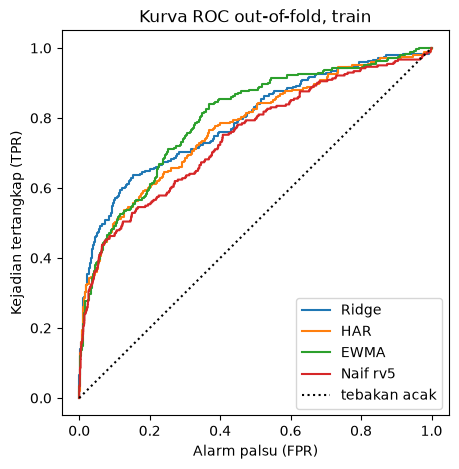

In [158]:
fig, ax = plt.subplots(figsize=(5, 5))
for k, v in skor.items():
    fpr, tpr, _ = roc_curve(kejadian, v)
    ax.plot(fpr, tpr, label=k)
ax.plot([0, 1], [0, 1], "k:", label="tebakan acak")
ax.set(xlabel="Alarm palsu (FPR)", ylabel="Kejadian tertangkap (TPR)", title="Kurva ROC out-of-fold, train")
ax.legend()

AUC out-of-fold: Ridge 0,790, EWMA 0,798, HAR 0,772. Ridge unggul pada uji per tahun (7.6, 8.3).

**Memilih ambang alarm** untuk Ridge: titik pertama di kurva ROC yang menangkap minimal dua pertiga kejadian, yaitu titik dengan alarm palsu paling sedikit.

In [159]:
fpr, tpr, ambang_prediksi = roc_curve(kejadian, oof)
ambang_alarm = ambang_prediksi[np.argmax(tpr >= 2 / 3)]
ambang_alarm

np.float64(0.009433140646116923)

In [160]:
sinyal = oof > ambang_alarm
pd.Series({"hit rate (TPR)": (sinyal & kejadian).sum() / kejadian.sum(),
           "alarm palsu (FPR)": (sinyal & ~kejadian).sum() / (~kejadian).sum(),
           "noise-to-signal": ((sinyal & ~kejadian).sum() / (~kejadian).sum()) / ((sinyal & kejadian).sum() / kejadian.sum()),
           "presisi (alarm yang benar)": (sinyal & kejadian).sum() / sinyal.sum(),
           "hari beralarm": sinyal.mean()}).round(3)

hit rate (TPR)                0.665
alarm palsu (FPR)             0.235
noise-to-signal               0.354
presisi (alarm yang benar)    0.225
hari beralarm                 0.275
dtype: float64

Ambang alarm **0,0094** menangkap **66,5%** kejadian dengan alarm palsu 23,5%. Presisinya **22,5%**, yaitu 1 dari 4 alarm diikuti hari berbahaya, 2,4 kali laju dasar.

**Uji di validasi 2023 sampai 2024**, dengan ambang alarm yang **tidak diubah** dari train.

In [161]:
kej_va = y_va > ambang
alarm_va = pred_va > ambang_alarm
pd.crosstab(alarm_va, kej_va, rownames=["alarm"], colnames=["kejadian"])

kejadian,False,True
alarm,,
False,463,8
True,46,0


In [162]:
pd.Series({"hit rate (TPR)": (alarm_va & kej_va).sum() / kej_va.sum(),
           "alarm palsu (FPR)": (alarm_va & ~kej_va).sum() / (~kej_va).sum(),
           "hari beralarm": alarm_va.mean()}).round(3)

hit rate (TPR)       0.000
alarm palsu (FPR)    0.090
hari beralarm        0.089
dtype: float64

**0 dari 8 hari berbahaya** validasi tertangkap dengan ambang train. Delapan hari itu dari 3 episode, dan episode November tetap didahului alarm. Lihat 8.3 dan 8.4.

## 8.3 Sistem validasi peringatan dini (walk-forward)

Seperti pemakaian nyata sejak 2016: prediksi dan ambang hanya dari tahun-tahun sebelumnya. EWMA, HAR, naif rv5 diberi aturan sama.

In [163]:
def ambang_bis(skor, kej, target=2 / 3):
    fpr, tpr, thr = roc_curve(kej, skor)
    return thr[np.argmax(tpr >= target)]

def metrik_alarm(alarm, kej):
    # tahun tanpa kejadian atau tanpa alarm sengaja menghasilkan NaN/inf, jadi peringatan pembagian nol dimatikan
    with np.errstate(divide="ignore", invalid="ignore"):
        tpr, fpr = (alarm & kej).sum() / kej.sum(), (alarm & ~kej).sum() / (~kej).sum()
        return pd.Series({"hit rate (TPR)": tpr, "alarm palsu (FPR)": fpr, "noise-to-signal": fpr / tpr,
                          "presisi": (alarm & kej).sum() / alarm.sum(), "laju dasar": kej.mean(), "hari beralarm": alarm.mean()})

In [164]:
def awal_episode(kej, jeda=10):
    t = np.flatnonzero(kej.values)
    return t[np.r_[True, np.diff(t) > jeda]]

def kategori_episode(alarm, kej, mundur=10):
    baris = []
    for m in awal_episode(kej)[awal_episode(kej) >= mundur]:
        w = alarm.values[m - mundur:m + 1]
        status = "sudah menyala" if w[0] else "baru menyala" if w.any() else "tanpa alarm"
        baris.append((kej.index[m], status, mundur - np.flatnonzero(w)[0] if status == "baru menyala" else np.nan))
    return pd.DataFrame(baris, columns=["mulai", "status", "lead"]).set_index("mulai")

def ringkas(alarm, kej):
    kat = kategori_episode(alarm, kej)
    run = (alarm & ~alarm.shift(fill_value=False)).cumsum()[alarm]
    awal = pd.Series(False, index=kej.index)
    awal.iloc[awal_episode(kej)] = True
    dalam_10_hari = awal.iloc[::-1].rolling(11, min_periods=1).max().iloc[::-1].astype(bool)
    return pd.Series({**kat["status"].value_counts().reindex(["sudah menyala", "baru menyala", "tanpa alarm"], fill_value=0),
                      "median lead (baru menyala)": kat["lead"].median(), "run alarm": run.nunique(),
                      "run berujung episode": dalam_10_hari[alarm].groupby(run.values).any().sum(), "hari beralarm": alarm.mean()})

In [165]:
alarm_wf = {}
for k in ["Ridge", "EWMA", "HAR", "naif rv5"]:
    potong = []
    for tahun in range(2016, 2025):
        lalu = wf_pred.loc[:str(tahun - 1)].index[:-5]
        potong.append(wf_pred.loc[str(tahun), k] > ambang_bis(wf_pred.loc[lalu, k], kej_all.loc[lalu]))
    alarm_wf[k] = pd.concat(potong)
kej_wf = kej_all.loc["2016":]

**Ukuran per hari, 2016 sampai 2024** (ambang dari tahun-tahun sebelumnya).

In [166]:
pd.DataFrame({k: metrik_alarm(v, kej_wf) for k, v in alarm_wf.items()}).T.round(3)

,hit rate (TPR),alarm palsu (FPR),noise-to-signal,presisi,laju dasar,hari beralarm
Ridge,0.709,0.188,0.266,0.178,0.054,0.216
EWMA,0.614,0.158,0.258,0.182,0.054,0.183
HAR,0.606,0.207,0.342,0.144,0.054,0.229
naif rv5,0.654,0.277,0.423,0.119,0.054,0.297


- Ridge menangkap **70,9% hari berbahaya**, tertinggi, dengan alarm palsu 18,8%. EWMA hanya 61,4%.
- Presisi 17,8%, 3,3 kali laju dasar.

**Per episode:** apakah episode krisis didahului alarm dalam 10 hari?

In [167]:
pd.DataFrame({k: ringkas(v, kej_wf) for k, v in alarm_wf.items()}).round(2)

,Ridge,EWMA,HAR,naif rv5
sudah menyala,10.00,8.00,10.00,8.0
baru menyala,3.00,1.00,2.00,9.0
tanpa alarm,7.00,11.00,8.00,3.0
median lead (baru menyala),6.00,2.00,2.50,5.0
run alarm,69.00,30.00,126.00,146.0
run berujung episode,16.00,6.00,19.00,26.0
hari beralarm,0.22,0.18,0.23,0.3


Dari 20 episode: **Ridge 13**, HAR 12, EWMA 9, naif rv5 17 (tetapi alarm di 30% hari). 3 dari 4 run alarm tidak berujung episode: alarm berarti "waspada", bukan "bertindak".

**Per tahun untuk Ridge.** Tahun dengan sedikit kejadian sangat berisik, jadi yang kami baca adalah polanya, bukan angka satu tahun.

In [168]:
pd.DataFrame({tahun: metrik_alarm(alarm_wf["Ridge"].loc[str(tahun)], kej_wf.loc[str(tahun)]) for tahun in range(2016, 2025)}).T.assign(kejadian=kej_wf.groupby(kej_wf.index.year).sum().values).round(2)

,hit rate (TPR),alarm palsu (FPR),noise-to-signal,presisi,laju dasar,hari beralarm,kejadian
2016,0.00,0.06,inf,0.00,0.02,0.06,5
2017,NaN,0.01,NaN,0.00,0.00,0.01,0
2018,0.62,0.57,0.93,0.11,0.10,0.58,26
2019,0.50,0.21,0.42,0.02,0.01,0.21,2
2020,0.92,0.80,0.87,0.31,0.28,0.84,74
2021,0.60,0.05,0.08,0.20,0.02,0.06,5
2022,0.29,0.12,0.43,0.06,0.03,0.13,7
2023,NaN,0.00,NaN,NaN,0.00,0.00,0
2024,0.00,0.06,inf,0.00,0.03,0.06,8


Kuat di tahun krisis (2020: 92%), lemah pada guncangan mendadak di tahun tenang (2016 dan 2024: 0%), tidak berisik di tahun tenang (2017, 2023).

**Bootstrap blok bulanan** (1.000 kali): apakah keunggulan AUC Ridge bukan kebetulan?

In [169]:
bulan = wf_pred.index.to_period("M")
posisi = {b: np.flatnonzero(bulan == b) for b in bulan.unique()}
k_arr, s_arr = kej_all.to_numpy(), wf_pred[["Ridge", "EWMA", "HAR", "naif rv5"]].to_numpy()
rng_b = np.random.default_rng(1)
selisih_auc = []
for _ in range(1000):
    i = np.concatenate([posisi[b] for b in rng_b.choice(list(posisi), len(posisi))])
    auc = [roc_auc_score(k_arr[i], s_arr[i, j]) for j in range(4)]
    selisih_auc.append([auc[0] - auc[1], auc[0] - auc[2], auc[0] - auc[3]])
selisih_auc = pd.DataFrame(selisih_auc, columns=["Ridge - EWMA", "Ridge - HAR", "Ridge - naif rv5"])

In [170]:
pd.Series({k: roc_auc_score(kej_all, wf_pred[k]) for k in ["Ridge", "EWMA", "HAR", "naif rv5"]}).round(3).rename("AUC gabungan 2015 sampai 2024")

Ridge       0.812
EWMA        0.802
HAR         0.752
naif rv5    0.747
Name: AUC gabungan 2015 sampai 2024, dtype: float64

In [171]:
selisih_auc.quantile([0.025, 0.5, 0.975]).T.assign(**{"porsi bootstrap > 0": (selisih_auc > 0).mean()}).round(3)

,0.025,0.5,0.975,porsi bootstrap > 0
Ridge - EWMA,-0.058,0.012,0.077,0.651
Ridge - HAR,0.002,0.060,0.131,0.978
Ridge - naif rv5,0.000,0.067,0.138,0.976


- **AUC gabungan:** Ridge 0,812, EWMA 0,802, HAR 0,752, naif 0,747.
- **Selisih AUC vs HAR signifikan** [0,002; 0,131]. Vs EWMA tidak signifikan.

EWMA setara di AUC gabungan karena levelnya mengikuti rezim. Untuk mengurutkan hari **di dalam** tahun yang sama, Ridge unggul (AUC per tahun 0,68 vs 0,55, episode 13 vs 9).

## 8.4 Alarm yang lebih peka: mode sampai 90% hari berbahaya

Bisakah alarm menangkap 90% hari berbahaya, dan berapa harganya? Ambang tetap dipilih dari masa lalu.

In [172]:
def alarm_target(skor, target):
    hasil = []
    for t in range(2016, 2025):
        lalu = wf_pred.loc[:str(t - 1)].index[:-5]
        hasil.append(wf_pred.loc[str(t), skor] > ambang_bis(wf_pred.loc[lalu, skor], kej_all.loc[lalu], target))
    return pd.concat(hasil)

def baris_target(target, skor="Ridge"):
    a = alarm_target(skor, target)
    r = ringkas(a, kej_wf)
    return pd.concat([metrik_alarm(a, kej_wf)[["hit rate (TPR)", "alarm palsu (FPR)", "presisi", "hari beralarm"]],
                      pd.Series({"episode terdeteksi": r.iloc[:3].sum() - r["tanpa alarm"], "episode total": r.iloc[:3].sum()})])

**Target hit rate harian dinaikkan bertahap** (Ridge, ambang walk-forward 2016 sampai 2024).

In [173]:
pd.DataFrame({f"target {t:.2f}": baris_target(t) for t in [2 / 3, 0.8, 0.9, 0.95, 0.97]}).T.round(3)

,hit rate (TPR),alarm palsu (FPR),presisi,hari beralarm,episode terdeteksi,episode total
target 0.67,0.709,0.188,0.178,0.216,13.0,20.0
target 0.80,0.803,0.398,0.104,0.420,19.0,20.0
target 0.90,0.898,0.537,0.087,0.557,20.0,20.0
target 0.95,0.969,0.663,0.077,0.679,20.0,20.0
target 0.97,1.000,0.770,0.069,0.783,20.0,20.0


- **Per hari mahal:** hit rate 89,8% butuh alarm di 56% hari.
- **Per episode murah:** alarm di 42% hari sudah mendeteksi 19 dari 20 episode.
- Di target 0,9: Ridge 20 episode, HAR 19, EWMA 15.

**Kurva biaya.** Setiap titik adalah satu target. Sumbu x adalah porsi hari beralarm, sumbu y porsi hari berbahaya yang tertangkap. Makin melengkung ke kiri atas, makin murah kepekaannya.

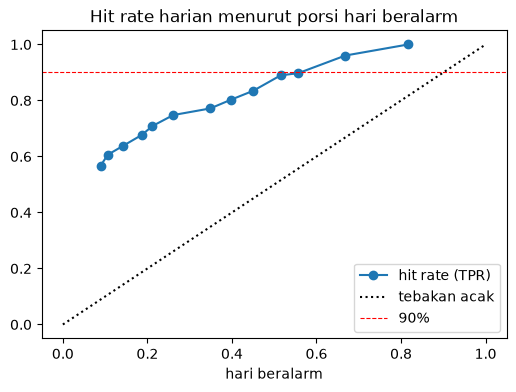

In [174]:
kurva = pd.DataFrame({t: baris_target(t) for t in np.linspace(0.5, 0.98, 13)}).T
ax = kurva.plot(x="hari beralarm", y=["hit rate (TPR)"], marker="o", figsize=(6, 4), title="Hit rate harian menurut porsi hari beralarm")
ax.plot([0, 1], [0, 1], "k:", label="tebakan acak")
ax.axhline(0.9, color="red", ls="--", lw=0.8, label="90%")
ax.legend()

**Pembanding adil di target 0,9.** Ridge, EWMA, HAR, dan naif rv5 diberi aturan ambang yang sama.

In [175]:
pd.DataFrame({k: baris_target(0.9, k) for k in ["Ridge", "EWMA", "HAR", "naif rv5"]}).T.round(3)

,hit rate (TPR),alarm palsu (FPR),presisi,hari beralarm,episode terdeteksi,episode total
Ridge,0.898,0.537,0.087,0.557,20.0,20.0
EWMA,0.850,0.408,0.107,0.432,15.0,20.0
HAR,0.811,0.538,0.080,0.553,19.0,20.0
naif rv5,0.890,0.619,0.076,0.633,20.0,20.0


**Konsistensi per tahun di target 0,95** (target yang menghasilkan hit rate nyata di atas 90%).

In [176]:
a95 = alarm_target("Ridge", 0.95)
pd.DataFrame({t: metrik_alarm(a95.loc[str(t)], kej_wf.loc[str(t)]) for t in range(2016, 2025)}).T.assign(kejadian=kej_wf.groupby(kej_wf.index.year).sum().values).round(2)

,hit rate (TPR),alarm palsu (FPR),noise-to-signal,presisi,laju dasar,hari beralarm,kejadian
2016,0.80,0.63,0.79,0.02,0.02,0.63,5
2017,NaN,0.19,NaN,0.00,0.00,0.19,0
2018,0.92,0.90,0.98,0.10,0.10,0.90,26
2019,1.00,0.72,0.72,0.01,0.01,0.72,2
2020,1.00,0.91,0.91,0.30,0.28,0.94,74
2021,1.00,0.85,0.85,0.02,0.02,0.85,5
2022,1.00,0.88,0.88,0.03,0.03,0.88,7
2023,NaN,0.39,NaN,0.00,0.00,0.39,0
2024,0.88,0.59,0.67,0.05,0.03,0.60,8


Di target 0,95, hit rate minimal 80% di setiap tahun, tetapi alarm palsu 59% sampai 91% hari normal.

**Tiga mode kepekaan:**

| Mode | Target | Hit rate hari | Episode | Hari beralarm | Presisi |
|---|---|---|---|---|---|
| SEIMBANG | 0,67 | 71% | 13 dari 20 | 22% | 18% |
| PEKA | 0,80 | 80% | 19 dari 20 | 42% | 10% |
| SANGAT PEKA | 0,95 | 97% | 20 dari 20 | 68% | 8% |

**Ketiga mode di validasi 2023 sampai 2024**, dengan ambang dari tahun-tahun sebelumnya.

In [177]:
mode = {"SEIMBANG": 2 / 3, "PEKA": 0.8, "SANGAT PEKA": 0.95}
hasil_mode = {}
for nama, target in mode.items():
    a_mode, k_mode = alarm_target("Ridge", target).loc["2023":], kej_wf.loc["2023":]
    r_mode = ringkas(a_mode, k_mode)
    hasil_mode[nama] = {"hari berbahaya tertangkap": (a_mode & k_mode).sum(), "dari": k_mode.sum(), "episode terdeteksi": r_mode["sudah menyala"] + r_mode["baru menyala"],
                        "episode total": r_mode.iloc[:3].sum(), "hari beralarm": a_mode.mean(), "presisi": (a_mode & k_mode).sum() / a_mode.sum()}
pd.DataFrame(hasil_mode).T.round(3)

,hari berbahaya tertangkap,dari,episode terdeteksi,episode total,hari beralarm,presisi
SEIMBANG,0.0,8.0,1.0,3.0,0.031,0.000
PEKA,2.0,8.0,2.0,3.0,0.207,0.019
SANGAT PEKA,7.0,8.0,3.0,3.0,0.493,0.027


- **SEIMBANG:** alarm hanya 3% hari, 0 dari 8 hari, 1 dari 3 episode.
- **PEKA:** 2 dari 3 episode, alarm 21% hari.
- **SANGAT PEKA:** 7 dari 8 hari, 3 dari 3 episode, alarm 49% hari.

Ambang seimbang dipelajari dari masa bergejolak, jadi jarang menyala di masa tenang. Aturan "mode peka saat tenang" diuji di walk-forward 2016 sampai 2022 dan **tidak lebih baik** daripada ambang tetap dengan jumlah alarm setara (Lampiran D). Pilihan mode tetap soal toleransi alarm palsu komite.

## 8.5 Pita risiko dan status berjenjang

Komite juga perlu tahu "skenario buruk yang masih wajar". **Pita P90 dan P95** dibuat dengan regresi kuantil linear pada fitur yang sama.

In [178]:
kuantil = [0.5, 0.9, 0.95]

In [179]:
model_q = {q: make_pipeline(StandardScaler(), QuantileRegressor(quantile=q, alpha=0, solver="highs")).fit(tr[fitur_cols], y_tr) for q in kuantil}

Model kuantil dilatih terpisah, jadi bisa saja saling bersilangan (misalnya P90 di bawah P50). Silangan dihilangkan dengan mengurutkan ketiga prediksi per hari.

In [180]:
pita_va = pd.DataFrame({q: m.predict(va[fitur_cols]) for q, m in model_q.items()}, index=va.index)
pita_va = pd.DataFrame(np.sort(pita_va.values, axis=1), index=va.index, columns=kuantil)

**Kalibrasi:** kalau pita benar, Y aktual berada di bawah P50 pada 50% hari, di bawah P90 pada 90%, dan di bawah P95 pada 95%.

In [181]:
pita_va.ge(y_va, axis=0).mean().round(3)

0.50    0.619
0.90    0.928
0.95    0.977
dtype: float64

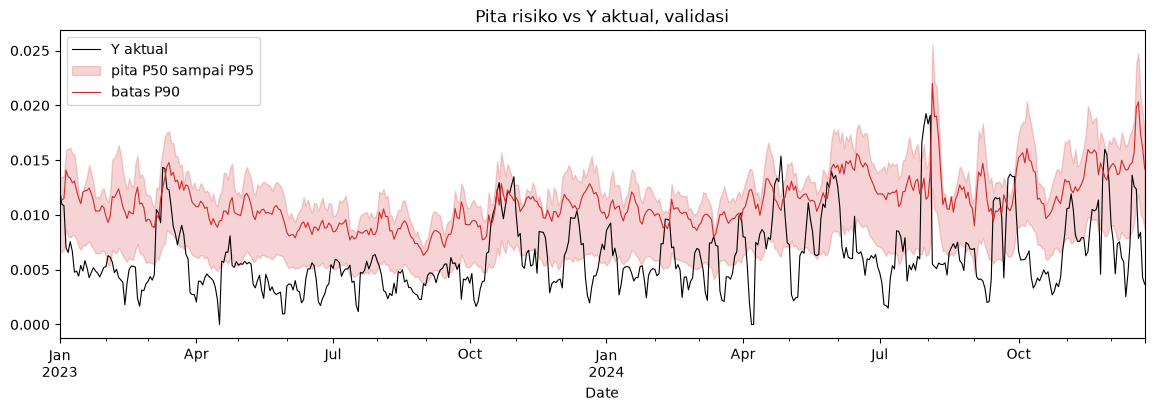

In [182]:
ax = y_va.plot(figsize=(14, 4), color="black", lw=0.8, label="Y aktual", title="Pita risiko vs Y aktual, validasi")
ax.fill_between(va.index, pita_va[0.5], pita_va[0.95], color="tab:red", alpha=0.2, label="pita P50 sampai P95")
pita_va[0.9].plot(ax=ax, color="tab:red", lw=0.8, label="batas P90")
ax.legend()

**Kasus 31 Juli 2024**, hari dengan kesalahan terbesar di validasi, dilihat bersama pita risikonya.

In [183]:
pd.DataFrame({"Y aktual": y_va, "P50": pita_va[0.5], "P90": pita_va[0.9], "P95": pita_va[0.95]}).loc["2024-07-29":"2024-08-09"].round(4)

,Y aktual,P50,P90,P95
Date,,,,
2024-07-29,0.0166,0.0064,0.0124,0.0152
2024-07-30,0.0181,0.0071,0.0134,0.0165
2024-07-31,0.0193,0.0063,0.0114,0.0143
2024-08-01,0.0183,0.0064,0.0117,0.0146
2024-08-02,0.0191,0.0073,0.0139,0.0170
2024-08-05,0.0055,0.0124,0.0220,0.0256
2024-08-06,0.0053,0.0104,0.0189,0.0221
2024-08-07,0.0051,0.0103,0.0190,0.0217
2024-08-08,0.0056,0.0091,0.0169,0.0188


Y di bawah P90 pada 92,8% hari dan di bawah P95 pada 97,7%: sedikit konservatif. **31 Juli 2024** melampaui P95, karena guncangannya tanpa jejak.

**Status berjenjang:** WASPADA di ambang yang menangkap dua pertiga kejadian, BAHAYA di ambang yang menangkap sepertiga kejadian.

In [184]:
ambang_bahaya = ambang_prediksi[np.argmax(tpr >= 1 / 3)]
pd.Series({"ambang WASPADA": ambang_alarm, "ambang BAHAYA": ambang_bahaya}).round(4)

ambang WASPADA    0.0094
ambang BAHAYA     0.0140
dtype: float64

`mean` = porsi hari berstatus itu yang diikuti kejadian.

In [185]:
status_oof = pd.cut(oof, [-np.inf, ambang_alarm, ambang_bahaya, np.inf], labels=["NORMAL", "WASPADA", "BAHAYA"])
kejadian.groupby(status_oof, observed=False).agg(["mean", "size"]).round(3)

,mean,size
NORMAL,0.043,1888
WASPADA,0.138,585
BAHAYA,0.606,132


In [186]:
status_va = pd.cut(pred_va, [-np.inf, ambang_alarm, ambang_bahaya, np.inf], labels=["NORMAL", "WASPADA", "BAHAYA"])
kej_va.groupby(status_va, observed=False).agg(["mean", "size"]).round(3)

,mean,size
NORMAL,0.017,471
WASPADA,0.000,46
BAHAYA,NaN,0


Train: NORMAL 4,3%, WASPADA 13,8%, **BAHAYA 60,6%** diikuti kejadian (laju dasar 9,3%). Validasi tanpa hari BAHAYA.

## 8.6 Prediksi periode test

Model dilatih ulang pada data berlabel sampai 2024 (embargo 5 hari). Ambang dari walk-forward.

In [187]:
trva = tabel.loc[:"2024"].dropna().iloc[:-5]
model_akhir = clone(ridge).fit(trva[fitur_cols], trva["Y"])
pred_te = pd.Series(model_akhir.predict(te[fitur_cols]), index=te.index)

In [188]:
model_q_akhir = {q: make_pipeline(StandardScaler(), QuantileRegressor(quantile=q, alpha=0, solver="highs")).fit(trva[fitur_cols], trva["Y"]) for q in kuantil}
pita_te = pd.DataFrame({q: m.predict(te[fitur_cols]) for q, m in model_q_akhir.items()}, index=te.index)
pita_te = pd.DataFrame(np.sort(pita_te.values, axis=1), index=te.index, columns=kuantil)

In [189]:
lalu_akhir = wf_pred.index[:-5]
ambang_waspada_akhir = ambang_bis(wf_pred.loc[lalu_akhir, "Ridge"], kej_all.loc[lalu_akhir])
ambang_bahaya_akhir = ambang_bis(wf_pred.loc[lalu_akhir, "Ridge"], kej_all.loc[lalu_akhir], 1 / 3)
pd.Series({"WASPADA (train OOF, 8.5)": ambang_alarm, "BAHAYA (train OOF, 8.5)": ambang_bahaya,
           "WASPADA (walk-forward, dipakai)": ambang_waspada_akhir, "BAHAYA (walk-forward, dipakai)": ambang_bahaya_akhir}).round(4)

WASPADA (train OOF, 8.5)           0.0094
BAHAYA (train OOF, 8.5)            0.0140
WASPADA (walk-forward, dipakai)    0.0092
BAHAYA (walk-forward, dipakai)     0.0141
dtype: float64

In [190]:
status_te = pd.cut(pred_te, [-np.inf, ambang_waspada_akhir, ambang_bahaya_akhir, np.inf], labels=["NORMAL", "WASPADA", "BAHAYA"])
status_te.value_counts()

NORMAL     174
WASPADA    112
BAHAYA      73
Name: count, dtype: int64

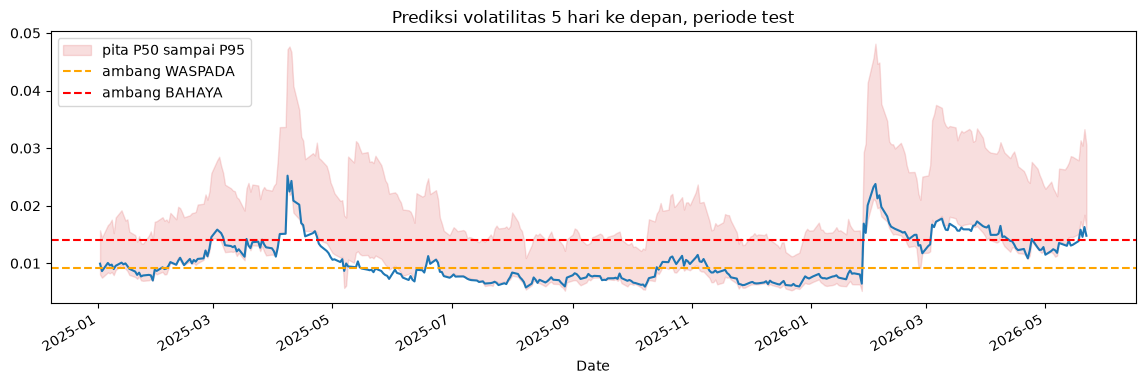

In [191]:
ax = pred_te.plot(figsize=(14, 4), title="Prediksi volatilitas 5 hari ke depan, periode test")
ax.fill_between(te.index, pita_te[0.5], pita_te[0.95], color="tab:red", alpha=0.15, label="pita P50 sampai P95")
ax.axhline(ambang_waspada_akhir, color="orange", ls="--", label="ambang WASPADA")
ax.axhline(ambang_bahaya_akhir, color="red", ls="--", label="ambang BAHAYA")
ax.legend()

In [192]:
pd.crosstab(status_te.index.to_period("M"), status_te)

col_0,NORMAL,WASPADA,BAHAYA
row_0,,,
2025-01,13,9,0
2025-02,2,17,1
2025-03,0,15,6
2025-04,0,8,13
2025-05,12,10,0
2025-06,16,5,0
2025-07,23,0,0
2025-08,21,0,0
2025-09,22,0,0


**174 NORMAL, 112 WASPADA, 73 BAHAYA** dari 359 hari. 
- **April 2025:** puncak BAHAYA (guncangan tarif AS, 9.3).
- **Januari 2026:** status naik pada hari guncangan, bukan sebelumnya.
- **Februari sampai Mei 2026:** guncangan domestik (volatilitas IHSG dan drawdown, bukan VIX).

**Mode kepekaan di test**, ambang dari walk-forward 2015 sampai 2024.

In [193]:
ambang_mode = {k: ambang_bis(wf_pred.loc[lalu_akhir, "Ridge"], kej_all.loc[lalu_akhir], t) for k, t in {"seimbang": 2 / 3, "peka": 0.8, "sangat_peka": 0.95}.items()}
hasil_te = pd.DataFrame({"prediksi": pred_te, "P90": pita_te[0.9], "P95": pita_te[0.95], "status": status_te,
                         **{f"alarm_{k}": pred_te > v for k, v in ambang_mode.items()}})
hasil_te.to_csv("prediksi_test_2025_2026.csv")
pd.DataFrame({"ambang prediksi": ambang_mode, "porsi hari test beralarm": hasil_te.filter(like="alarm_").mean().set_axis(list(ambang_mode))}).round(4)

,ambang prediksi,porsi hari test beralarm
seimbang,0.0092,0.5153
peka,0.0079,0.6685
sangat_peka,0.0070,0.8552


Di rezim panas 2026, alarm menyala di 52% (seimbang) sampai 86% (sangat peka) hari. Ambang perlu dihitung ulang setiap tahun.

## Hasil analisis dari bab ini

- Validasi (8 hari berbahaya) terlalu kecil. Penilaian utama dari walk-forward: 20 episode.
- **Ridge mendeteksi episode terbanyak:** 13 dari 20, EWMA 9.
- 95% episode cukup dengan alarm di 42% hari.
- Ambang dihitung ulang setiap tahun.

# Bab 9. Task 3 (XAI): mengapa model memprediksi demikian?

Setiap status BAHAYA harus bisa dijelaskan dalam bahasa bisnis.


SHAP dihitung dengan `shap.LinearExplainer` yang **eksak** untuk model linear. Nilai positif menaikkan prediksi, dan satuannya sama dengan Y. Grafik memakai label bisnis, dengan nama kolom asli di dalam kurung.

In [194]:
label_bisnis = {"abs_ret": "Gerak IHSG hari ini (abs_ret)", "rv5": "Volatilitas IHSG 5 hari (rv5)",
                "rv10": "Volatilitas IHSG 10 hari (rv10)", "rv22": "Volatilitas IHSG 1 bulan (rv22)",
                "ewma_vol": "Volatilitas IHSG terkini (ewma_vol)", "downside_vol20": "Volatilitas saat turun (downside_vol20)",
                "drawdown_60": "Jatuh dari puncak 60 hari (drawdown_60)", "vix": "Level VIX (vix)",
                "vix_chg5": "Lonjakan VIX 5 hari (vix_chg5)", "turbulence_5d": "Stres lintas aset (turbulence_5d)",
                "rv20_gold": "Volatilitas emas (rv20_gold)", "usdidr_ret5": "Pelemahan rupiah 5 hari (usdidr_ret5)",
                "spread_chg60": "Perubahan spread BI vs Fed (spread_chg60)"}
nama_bisnis = [label_bisnis[k] for k in fitur_cols]

In [195]:
skala, ridge_fit = model[0], model[-1]

In [196]:
explainer = shap.LinearExplainer(ridge_fit, skala.transform(tr[fitur_cols]))

In [197]:
nilai_va = explainer(skala.transform(va[fitur_cols]))
sv_va = shap.Explanation(values=nilai_va.values, base_values=nilai_va.base_values, data=va[fitur_cols].values, feature_names=nama_bisnis)

**Uji aditivitas:** intersep ditambah jumlah semua nilai SHAP harus sama persis dengan prediksi model. Kalau tidak, penjelasannya tidak lengkap.

In [198]:
np.allclose(sv_va.base_values + sv_va.values.sum(axis=1), pred_va)

True

## 9.1 Penjelasan global

Text(0.5, 1.0, 'SHAP global, validasi 2023 sampai 2024: arah dan besar pengaruh tiap fitur')

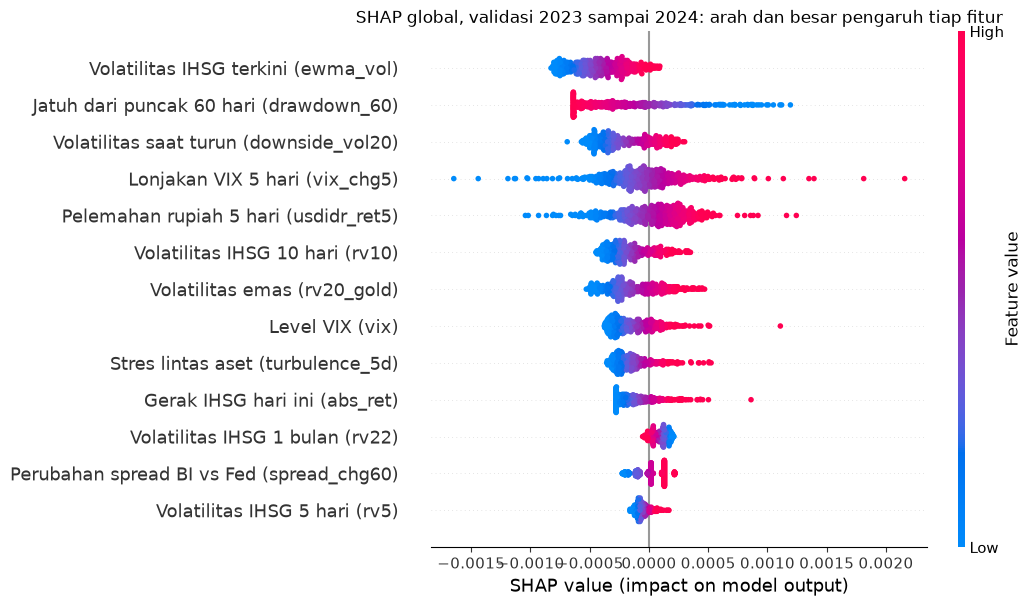

In [199]:
shap.plots.beeswarm(sv_va, max_display=13, show=False)
plt.title("SHAP global, validasi 2023 sampai 2024: arah dan besar pengaruh tiap fitur")

Text(0.5, 1.0, 'Rata-rata |SHAP| per fitur, validasi 2023 sampai 2024')

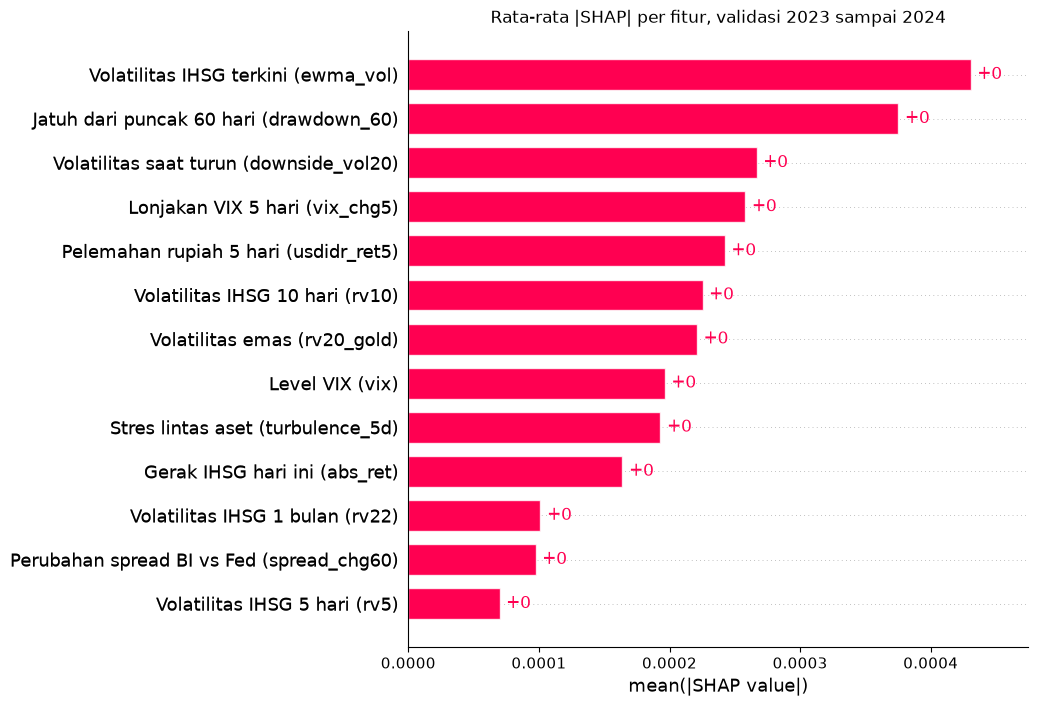

In [200]:
shap.plots.bar(sv_va, max_display=13, show=False)
plt.title("Rata-rata |SHAP| per fitur, validasi 2023 sampai 2024")

**Kamus fitur ke bahasa bisnis**, beserta kontribusi relatifnya (persentase dari total rata-rata nilai SHAP absolut di validasi). Tabel ini yang kami bayangkan dibawa ke rapat komite.

In [201]:
makna = {"abs_ret": "besar gerakan IHSG hari ini", "rv5": "volatilitas IHSG 5 hari terakhir", "rv10": "volatilitas IHSG 10 hari terakhir",
         "rv22": "volatilitas IHSG sekitar satu bulan terakhir", "ewma_vol": "volatilitas IHSG berbobot eksponensial (hari terbaru lebih berpengaruh)",
         "downside_vol20": "volatilitas pada hari-hari IHSG turun, 20 hari", "drawdown_60": "seberapa jauh IHSG berada di bawah puncak 60 hari",
         "vix": "indeks ketakutan global (VIX)", "vix_chg5": "lonjakan atau penurunan VIX dalam 5 hari",
         "turbulence_5d": "stres serentak lintas aset (IHSG, S&P 500, rupiah, emas)", "rv20_gold": "volatilitas emas 20 hari (pelarian ke aset aman)",
         "usdidr_ret5": "pelemahan atau penguatan rupiah dalam 5 hari", "spread_chg60": "perubahan selisih suku bunga BI dan Fed dalam 60 hari (ditunda 21 hari)"}

In [202]:
kontribusi = pd.Series(np.abs(sv_va.values).mean(0), index=fitur_cols)
pd.DataFrame({"kontribusi (%)": (kontribusi / kontribusi.sum() * 100).round(1), "arti bisnis": pd.Series(makna)}).sort_values("kontribusi (%)", ascending=False)

,kontribusi (%),arti bisnis
ewma_vol,15.2,volatilitas IHSG berbobot eksponensial (hari t...
drawdown_60,13.2,seberapa jauh IHSG berada di bawah puncak 60 hari
downside_vol20,9.4,"volatilitas pada hari-hari IHSG turun, 20 hari"
vix_chg5,9.1,lonjakan atau penurunan VIX dalam 5 hari
usdidr_ret5,8.5,pelemahan atau penguatan rupiah dalam 5 hari
rv10,7.9,volatilitas IHSG 10 hari terakhir
rv20_gold,7.8,volatilitas emas 20 hari (pelarian ke aset aman)
vix,6.9,indeks ketakutan global (VIX)
turbulence_5d,6.8,"stres serentak lintas aset (IHSG, S&P 500, rup..."
abs_ret,5.8,besar gerakan IHSG hari ini


<Axes: title={'center': 'Kontribusi SHAP per hipotesis (%), validasi'}>

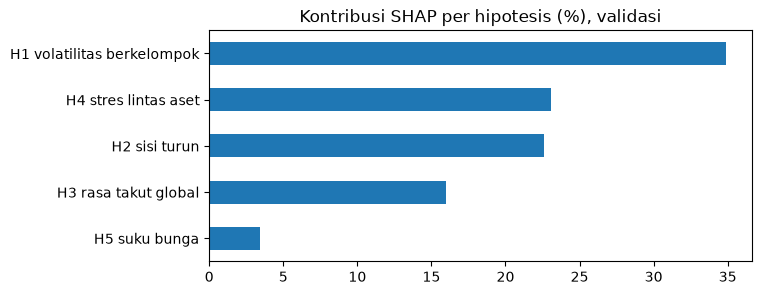

In [203]:
kelompok = {c: h for h, kolom in hipotesis.items() for c in kolom}
kontribusi_hipotesis = kontribusi.groupby(kelompok).sum() / kontribusi.sum() * 100
kontribusi_hipotesis.sort_values().plot.barh(figsize=(7, 3), title="Kontribusi SHAP per hipotesis (%), validasi")

In [204]:
kontribusi_hipotesis.sort_values(ascending=False).round(1)

H1 volatilitas berkelompok    34.9
H4 stres lintas aset          23.1
H2 sisi turun                 22.6
H3 rasa takut global          16.0
H5 suku bunga                  3.4
dtype: float64

**Per hipotesis:** volatilitas terkini 35%, stres lintas aset 23%, sisi turun 23%, rasa takut global 16%, suku bunga 3%.
- Fitur terbesar `ewma_vol` (15%) dan `drawdown_60` (13%). Tidak ada fitur yang mendominasi.
- Nilai tinggi menaikkan prediksi, kecuali `drawdown_60` (makin dalam penurunan, makin tinggi).

**Kenapa `turbulence_5d` hanya peringkat 9?** Validasi periode tenang, jadi turbulence jarang tinggi. Nilai tambahnya terbukti di 7.9, dan pada 8 April 2025 ia pemicu terbesar.

## 9.2 Penjelasan dari waktu ke waktu

Krisis 2015 dan 2020 punya penyebab berbeda. SHAP dihitung dari model walk-forward tiap tahun, lalu dijumlahkan per hipotesis.

In [205]:
shap_wf = []
for tahun, m in wf_model.items():
    latar = m[0].transform(tabel.loc[:str(tahun - 1)].dropna().iloc[:-5][fitur_cols])
    nilai = shap.LinearExplainer(m[-1], latar).shap_values(m[0].transform(tabel.loc[str(tahun), fitur_cols]))
    shap_wf.append(pd.DataFrame(nilai, index=tabel.loc[str(tahun)].index, columns=fitur_cols))
shap_wf = pd.concat(shap_wf)
shap_hipotesis = shap_wf.T.groupby(kelompok).sum().T

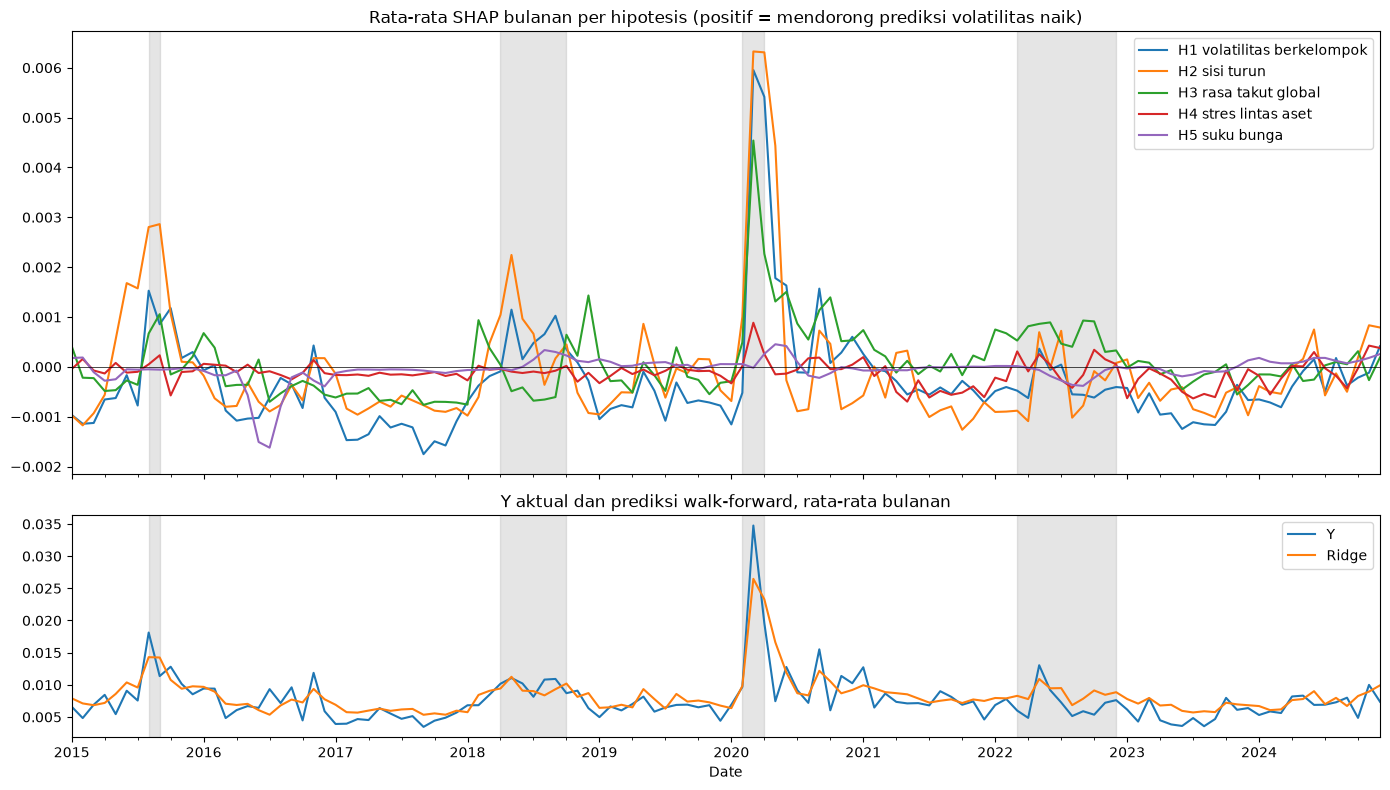

In [206]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, height_ratios=[2, 1])
shap_hipotesis.resample("ME").mean().plot(ax=axes[0], title="Rata-rata SHAP bulanan per hipotesis (positif = mendorong prediksi volatilitas naik)")
axes[0].axhline(0, color="black", lw=0.5)
wf_pred[["Y", "Ridge"]].resample("ME").mean().plot(ax=axes[1], title="Y aktual dan prediksi walk-forward, rata-rata bulanan")
for ax in axes:
    for a, b in episode.values():
        ax.axvspan(a, b, color="grey", alpha=0.2)
plt.tight_layout()

Text(0.5, 1.0, 'Porsi besar dorongan SHAP per hipotesis per tahun (%)')

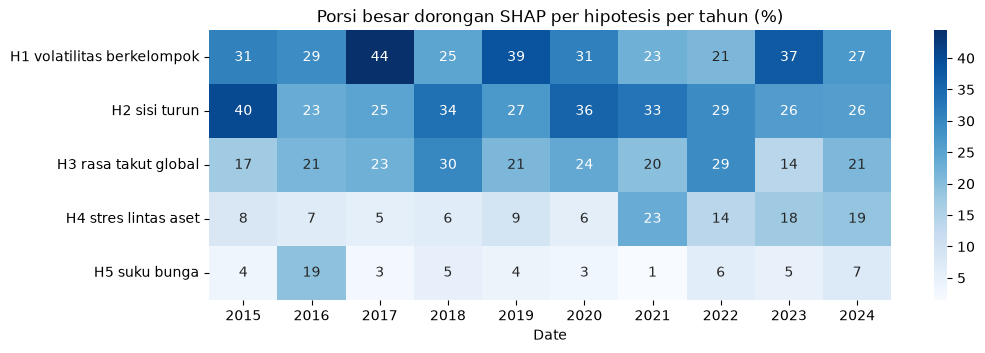

In [207]:
besar_tahunan = shap_hipotesis.abs().groupby(shap_hipotesis.index.year).mean()
plt.figure(figsize=(11, 3.5))
sns.heatmap(besar_tahunan.div(besar_tahunan.sum(axis=1), axis=0).T * 100, annot=True, fmt=".0f", cmap="Blues").set_title("Porsi besar dorongan SHAP per hipotesis per tahun (%)")

**Pemicu tiap krisis.** Rata-rata SHAP per hipotesis selama episode makro yang jatuh di periode walk-forward.

In [208]:
pd.DataFrame({k: shap_hipotesis.loc[a:b].mean() for k, (a, b) in episode.items() if a >= "2015"}).T.round(5)

,H1 volatilitas berkelompok,H2 sisi turun,H3 rasa takut global,H4 stres lintas aset,H5 suku bunga
Devaluasi yuan 2015,0.00132,0.00301,0.00105,0.00018,-0.00005
Pengetatan Fed 2018,0.00053,0.00074,-0.00030,-0.00008,0.00013
COVID 2020,0.00486,0.00566,0.00323,0.00053,0.00011
Kenaikan Fed 2022,-0.00034,-0.00027,0.00064,0.00002,-0.00016


- **COVID 2020:** semua hipotesis naik bersamaan (global dan lokal).
- **Yuan 2015:** didominasi sisi turun.
- **Fed 2018:** VIX justru menurunkan prediksi.
- **Fed 2022:** VIX naik, IHSG tenang, prediksi rendah, dan benar.
- **Stres lintas aset** naik dari 5 sampai 9% menjadi 14 sampai 23% setelah COVID.

## 9.3 Penjelasan lokal: hari dengan prediksi volatilitas tertinggi

Prediksi test dijelaskan dengan `model_akhir`. Waterfall dalam **persen per hari**.

In [209]:
explainer_akhir = shap.LinearExplainer(model_akhir[-1], model_akhir[0].transform(trva[fitur_cols]))

In [210]:
nilai_te = explainer_akhir(model_akhir[0].transform(te[fitur_cols]))
sv_te = shap.Explanation(values=nilai_te.values, base_values=nilai_te.base_values, data=te[fitur_cols].values, feature_names=nama_bisnis)

In [211]:
tgl_tinggi = pred_te.idxmax()

In [212]:
tgl_tinggi, pred_te.max(), te.loc[tgl_tinggi, fitur_cols]

(Timestamp('2025-04-08 00:00:00'),
 np.float64(0.025219338478482393),
 abs_ret            0.082318
 rv5                0.036814
 rv10               0.029900
 rv22               0.023126
 ewma_vol           0.024824
 downside_vol20     0.021667
 drawdown_60       -0.173758
 vix               52.330002
 vix_chg5           0.877037
 turbulence_5d     27.821727
 rv20_gold          0.011123
 usdidr_ret5        0.012159
 spread_chg60      -0.100000
 Name: 2025-04-08 00:00:00, dtype: float64)

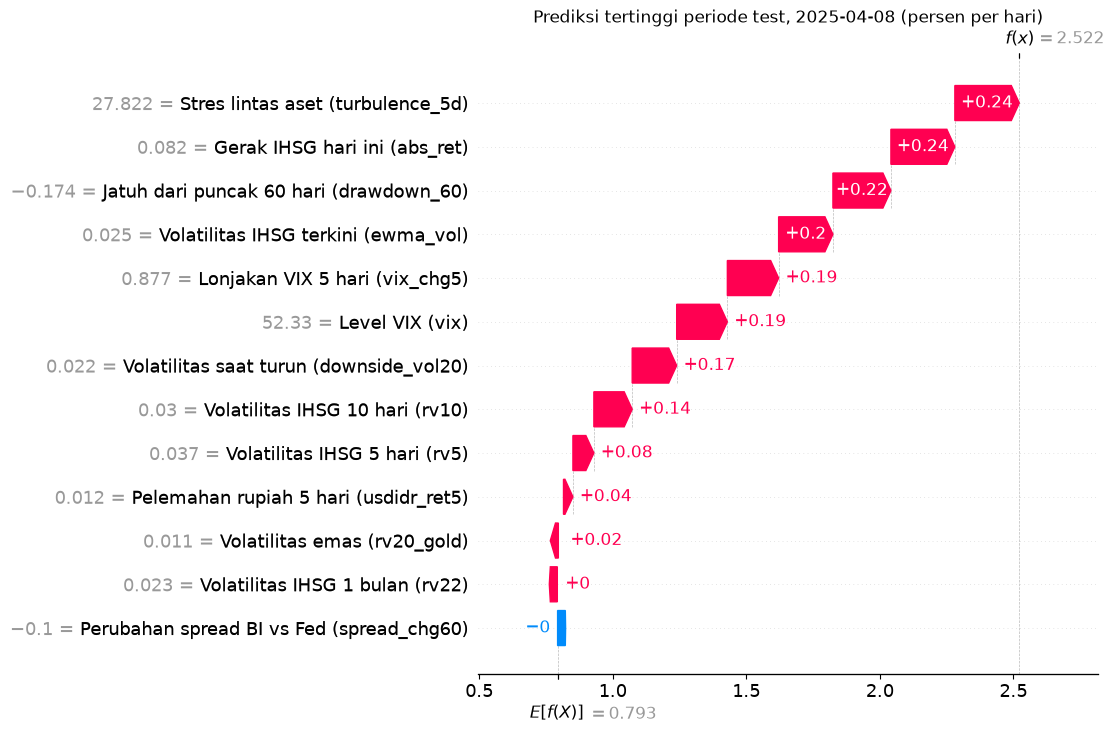

In [213]:
i = te.index.get_loc(tgl_tinggi)
shap.plots.waterfall(shap.Explanation(sv_te.values[i] * 100, sv_te.base_values[i] * 100, sv_te.data[i], feature_names=nama_bisnis), max_display=13, show=False)
plt.title(f"Prediksi tertinggi periode test, {tgl_tinggi.date()} (persen per hari)")
plt.show()

In [214]:
pd.Series(sv_te[te.index.get_loc(tgl_tinggi)].values, index=fitur_cols).sort_values(key=abs, ascending=False).round(5)

turbulence_5d     0.00241
abs_ret           0.00239
drawdown_60       0.00217
ewma_vol          0.00203
vix_chg5          0.00192
vix               0.00190
downside_vol20    0.00167
rv10              0.00143
rv5               0.00078
usdidr_ret5       0.00035
rv20_gold         0.00019
rv22              0.00004
spread_chg60     -0.00001
dtype: float64

**8 April 2025, prediksi 0,0252** (2,5% per hari), tiga kali nilai dasar. Konteks: hari pertama setelah Lebaran dan pengumuman tarif AS, IHSG turun sekitar 7,9%.

Pemicu: **stres lintas aset** (+0,0024), **gerak IHSG hari itu** (+0,0024), **jatuh dari puncak** (+0,0022, 17,4% di bawah puncak), **volatilitas terkini** (+0,0020), **VIX dan lonjakannya** (masing-masing +0,0019).

**Bahasa bisnis:** BAHAYA karena IHSG jatuh tajam bersamaan dengan kepanikan global dan gerakan ekstrem serentak di saham AS, rupiah, dan emas. Ketiga fitur andalan di jajaran teratas.

**Contoh dengan Y diketahui:** puncak prediksi 2020 dari model walk-forward yang belum pernah melihat COVID.

In [215]:
tgl_covid = wf_pred.loc["2020", "Ridge"].idxmax()
wf_pred.loc[tgl_covid, ["Y", "Ridge", "EWMA", "HAR"]].round(4)

Y        0.0314
Ridge    0.0351
EWMA     0.0370
HAR      0.0320
Name: 2020-03-26 00:00:00, dtype: float64

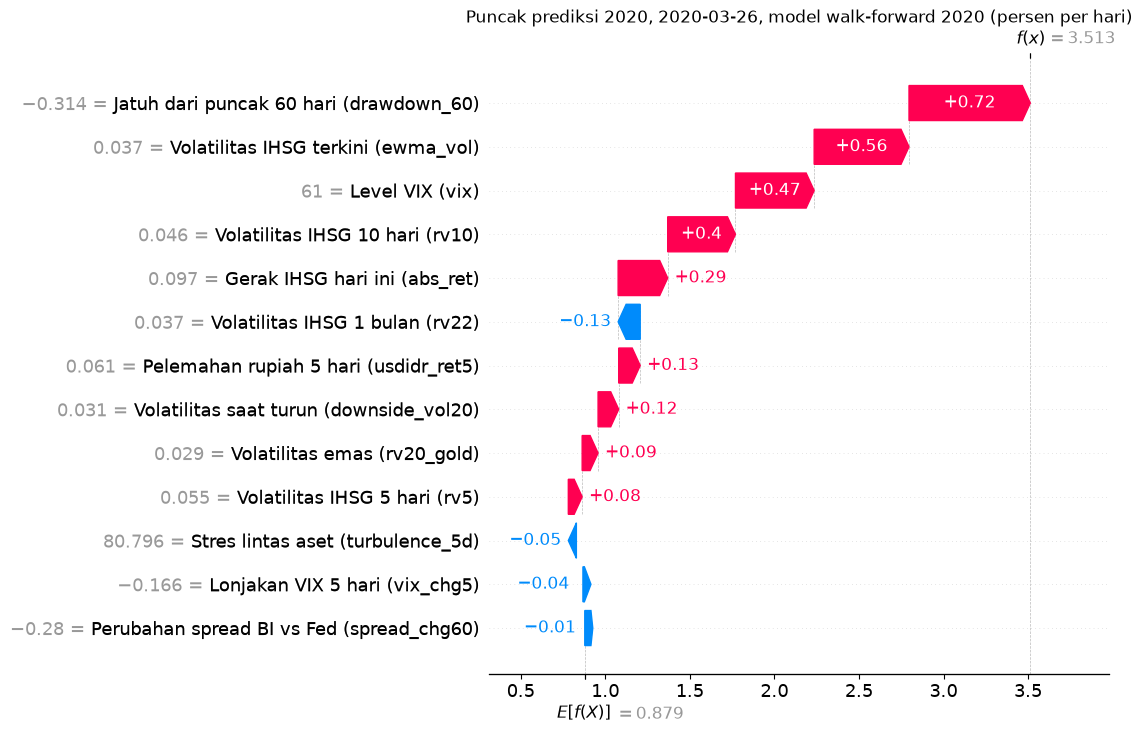

In [216]:
latar_2020 = wf_model[2020][0].transform(tabel.loc[:"2019"].dropna().iloc[:-5][fitur_cols])
nilai_covid = shap.LinearExplainer(wf_model[2020][-1], latar_2020)(wf_model[2020][0].transform(tabel.loc[[tgl_covid], fitur_cols]))
shap.plots.waterfall(shap.Explanation(nilai_covid.values[0] * 100, nilai_covid.base_values[0] * 100, tabel.loc[tgl_covid, fitur_cols].values, feature_names=nama_bisnis), max_display=13, show=False)
plt.title(f"Puncak prediksi 2020, {tgl_covid.date()}, model walk-forward 2020 (persen per hari)")
plt.show()

In [217]:
pd.Series(nilai_covid.values[0], index=fitur_cols).sort_values(key=abs, ascending=False).round(5)

drawdown_60       0.00717
ewma_vol          0.00561
vix               0.00465
rv10              0.00401
abs_ret           0.00293
rv22             -0.00131
usdidr_ret5       0.00127
downside_vol20    0.00122
rv20_gold         0.00094
rv5               0.00082
turbulence_5d    -0.00048
vix_chg5         -0.00039
spread_chg60     -0.00011
dtype: float64

**26 Maret 2020: prediksi 0,0351, Y aktual 0,0314.**

Pemicu: **jatuh dari puncak** (+0,0072, 31,4%), **volatilitas terkini** (+0,0056), **VIX** (+0,0047, level 61), **pelemahan rupiah** (+0,0013). `turbulence_5d` sedikit menurunkan (koefisien praktis nol di model 2020, 7.8).

**Bahasa bisnis:** BAHAYA karena IHSG jatuh dalam, volatilitas ekstrem, ketakutan global, dan rupiah melemah, sekaligus.

## 9.4 Analisis kesalahan berbasis XAI

SHAP dipakai untuk membedah hari-hari dengan galat terbesar di validasi.

In [218]:
galat = pd.DataFrame({"Y aktual": y_va, "prediksi": pred_va, "selisih": y_va - pred_va})
galat.reindex(galat["selisih"].abs().nlargest(6).index).round(4)

,Y aktual,prediksi,selisih
Date,,,
2024-07-31,0.0193,0.0072,0.0121
2024-08-01,0.0183,0.0074,0.0109
2024-08-02,0.0191,0.0082,0.0109
2024-07-30,0.0181,0.0082,0.0099
2024-07-29,0.0166,0.0075,0.0091
2024-08-05,0.0055,0.0136,-0.0081


In [219]:
tgl_meleset = galat['selisih'].idxmax()

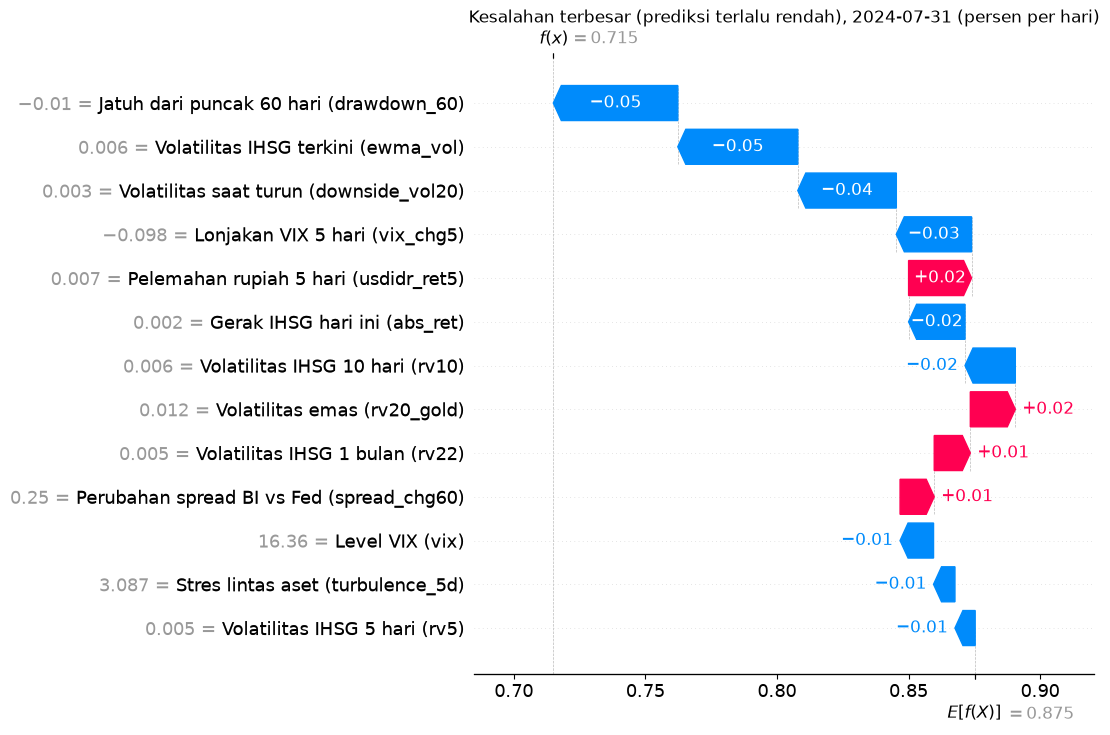

In [220]:
i = va.index.get_loc(tgl_meleset)
shap.plots.waterfall(shap.Explanation(sv_va.values[i] * 100, sv_va.base_values[i] * 100, sv_va.data[i], feature_names=nama_bisnis), max_display=13, show=False)
plt.title(f"Kesalahan terbesar (prediksi terlalu rendah), {tgl_meleset.date()} (persen per hari)")
plt.show()

In [221]:
pd.Series(sv_va[va.index.get_loc(tgl_meleset)].values, index=fitur_cols).sort_values(key=abs, ascending=False).round(5)

drawdown_60      -0.00047
ewma_vol         -0.00046
downside_vol20   -0.00037
vix_chg5         -0.00029
usdidr_ret5       0.00024
abs_ret          -0.00021
rv10             -0.00019
rv20_gold         0.00017
rv22              0.00014
spread_chg60      0.00013
vix              -0.00013
turbulence_5d    -0.00008
rv5              -0.00008
dtype: float64

**Kesalahan terbesar: 31 Juli 2024** (Y 0,0193, prediksi 0,0072).

Semua fitur menunjukkan pasar tenang (IHSG 1% di bawah puncak, VIX 16,4 dan turun), sehingga kontribusi terbesar justru menurunkan prediksi. Guncangan 2 sampai 5 Agustus **tidak punya jejak di data sampai 31 Juli**.

**Bahasa XAI:** model gagal karena sinyal andalannya, volatilitas terkini dan drawdown, dengan jujur menunjukkan pasar tenang.

In [222]:
tgl_alarm_palsu = galat['selisih'].idxmin()

In [223]:
galat.loc[tgl_alarm_palsu].round(4)

Y aktual    0.0055
prediksi    0.0136
selisih    -0.0081
Name: 2024-08-05 00:00:00, dtype: float64

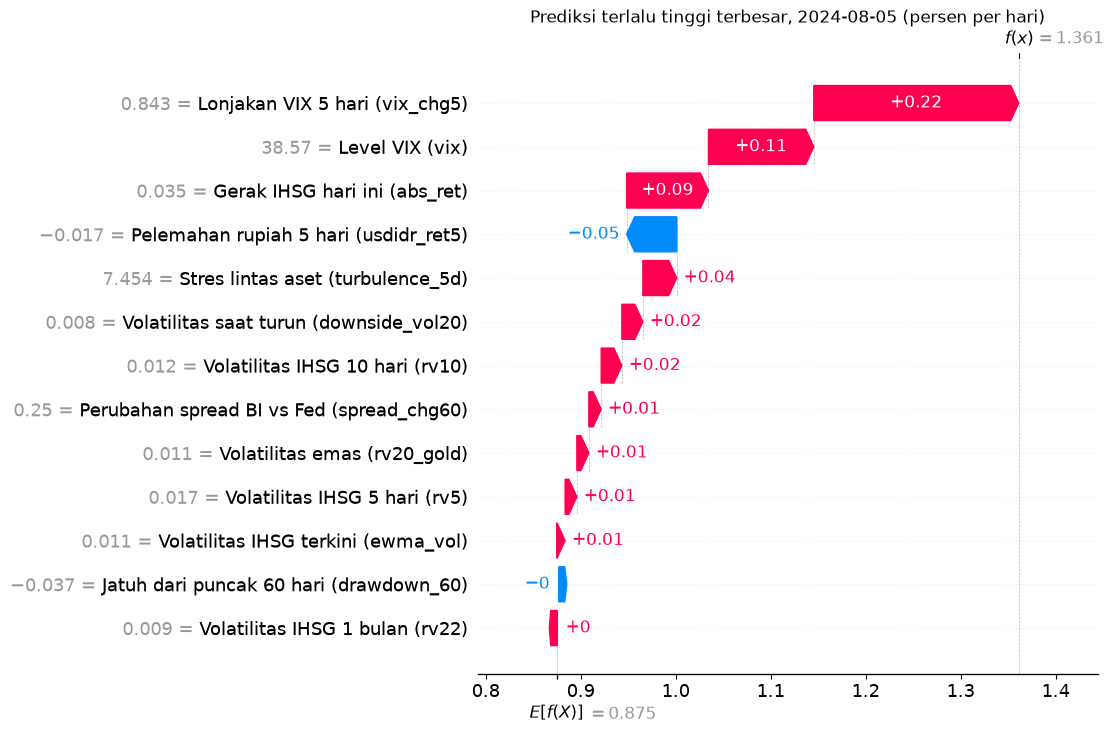

In [224]:
i = va.index.get_loc(tgl_alarm_palsu)
shap.plots.waterfall(shap.Explanation(sv_va.values[i] * 100, sv_va.base_values[i] * 100, sv_va.data[i], feature_names=nama_bisnis), max_display=13, show=False)
plt.title(f"Prediksi terlalu tinggi terbesar, {tgl_alarm_palsu.date()} (persen per hari)")
plt.show()

In [225]:
pd.Series(sv_va[va.index.get_loc(tgl_alarm_palsu)].values, index=fitur_cols).sort_values(key=abs, ascending=False).round(5)

vix_chg5          0.00216
vix               0.00111
abs_ret           0.00086
usdidr_ret5      -0.00053
turbulence_5d     0.00036
downside_vol20    0.00022
rv10              0.00022
spread_chg60      0.00013
rv20_gold         0.00013
rv5               0.00012
ewma_vol          0.00009
drawdown_60      -0.00002
rv22              0.00002
dtype: float64

**Prediksi terlalu tinggi terbesar: 5 Agustus 2024** (prediksi 0,0136, Y 0,0055).

Pendorong terbesar `vix_chg5` (+0,0022) dan `vix` (+0,0011), tetapi pasar pulih cepat. **Model terlalu mengandalkan lonjakan VIX singkat**, sama dengan pola di 4.9.

**Apakah polanya sistematis?** SHAP dibandingkan antara hari berbahaya yang tertangkap, yang terlewat, dan alarm palsu (walk-forward 2016 sampai 2024).

In [226]:
alarm_r = alarm_wf["Ridge"]
grup = pd.Series(np.select([kej_wf & alarm_r, kej_wf & ~alarm_r, ~kej_wf & alarm_r], ["tertangkap", "terlewat", "alarm palsu"], "normal tanpa alarm"), index=kej_wf.index)
grup.value_counts()

normal tanpa alarm    1799
alarm palsu            417
tertangkap              90
terlewat                37
Name: count, dtype: int64

In [227]:
shap_hipotesis.loc[grup.index].groupby(grup).mean().T.round(5)

,alarm palsu,normal tanpa alarm,terlewat,tertangkap
H1 volatilitas berkelompok,0.00060,-0.00069,-0.00044,0.00281
H2 sisi turun,0.00062,-0.00051,-0.00069,0.00310
H3 rasa takut global,0.00064,-0.00015,0.00003,0.00218
H4 stres lintas aset,0.00004,-0.00020,0.00004,0.00031
H5 suku bunga,0.00006,-0.00009,0.00008,0.00005


In [228]:
tabel.loc[grup.index, ["ewma_vol", "drawdown_60", "vix", "vix_chg5", "turbulence_5d"]].groupby(grup).median().round(4)

,ewma_vol,drawdown_60,vix,vix_chg5,turbulence_5d
alarm palsu,0.0107,-0.0493,22.270,0.0110,4.2185
normal tanpa alarm,0.0068,-0.0148,15.450,-0.0177,1.8695
terlewat,0.0082,-0.0065,17.870,-0.0484,3.0717
tertangkap,0.0146,-0.1056,33.495,0.0536,9.5341


90 dari 127 hari berbahaya tertangkap, 37 terlewat.
- **Terlewat:** SHAP volatilitas dan sisi turun negatif. Median VIX 17,9, IHSG 0,7% di bawah puncak.
- **Tertangkap:** median VIX 33,5, IHSG 10,6% di bawah puncak.
- **Alarm palsu:** tekanan sedang (VIX 22,3) yang mereda.

**Kesimpulan:** model gagal secara sistematis pada **guncangan dari kondisi tenang**. Perbaikannya butuh data jadwal peristiwa, bukan model lain (Lampiran C).

## 9.5 Apakah penjelasan SHAP bisa dipercaya?

SHAP menunjukkan fitur yang **dipakai** model, belum tentu yang **membantu**. Diuji dengan permutation importance di validasi dan LightGBM dengan TreeSHAP.

In [229]:
perm = permutation_importance(model, va[fitur_cols], y_va, scoring="neg_root_mean_squared_error", n_repeats=30, random_state=0)
pd.DataFrame({"SHAP (%)": kontribusi / kontribusi.sum() * 100, "RMSE naik saat diacak (x1e6)": pd.Series(perm.importances_mean * 1e6, index=fitur_cols)}).sort_values("SHAP (%)", ascending=False).round(2)

,SHAP (%),RMSE naik saat diacak (x1e6)
ewma_vol,15.16,-5.87
drawdown_60,13.21,16.64
downside_vol20,9.39,-8.54
vix_chg5,9.08,6.70
usdidr_ret5,8.53,15.93
rv10,7.93,-9.34
rv20_gold,7.78,28.02
vix,6.91,-0.65
turbulence_5d,6.80,7.46
abs_ret,5.77,-3.52


- **Paling berguna di validasi:** `rv20_gold`, `drawdown_60`, `usdidr_ret5`.
- **Volatilitas jangka pendek** sedikit merugikan di masa tenang, menjelaskan kesalahan 5 Agustus.

**LightGBM sebagai alat diagnosis**, bukan model utama. Parameter sama dengan 7.2, dilatih di train, lalu dijelaskan dengan TreeSHAP.

In [230]:
lgbm_xai = clone(lgbm_awal).fit(tr[fitur_cols], y_tr)
pohon = shap.TreeExplainer(lgbm_xai)
sv_lgbm_va = pohon(va[fitur_cols])

In [231]:
imp_lgbm = pd.Series(np.abs(sv_lgbm_va.values).mean(0), index=fitur_cols)
pd.DataFrame({"Ridge (%)": kontribusi / kontribusi.sum() * 100, "LightGBM (%)": imp_lgbm / imp_lgbm.sum() * 100}).sort_values("Ridge (%)", ascending=False).round(1)

,Ridge (%),LightGBM (%)
ewma_vol,15.2,27.2
drawdown_60,13.2,20.0
downside_vol20,9.4,3.6
vix_chg5,9.1,8.4
usdidr_ret5,8.5,7.4
rv10,7.9,7.8
rv20_gold,7.8,5.6
vix,6.9,6.8
turbulence_5d,6.8,4.5
abs_ret,5.8,2.4


In [232]:
kontribusi.corr(imp_lgbm, method="spearman")

np.float64(0.7967032967032966)

**Bentuk hubungan (grafik dependensi SHAP)** di data train, yang memuat banyak krisis sehingga rentang nilai fiturnya lebar.

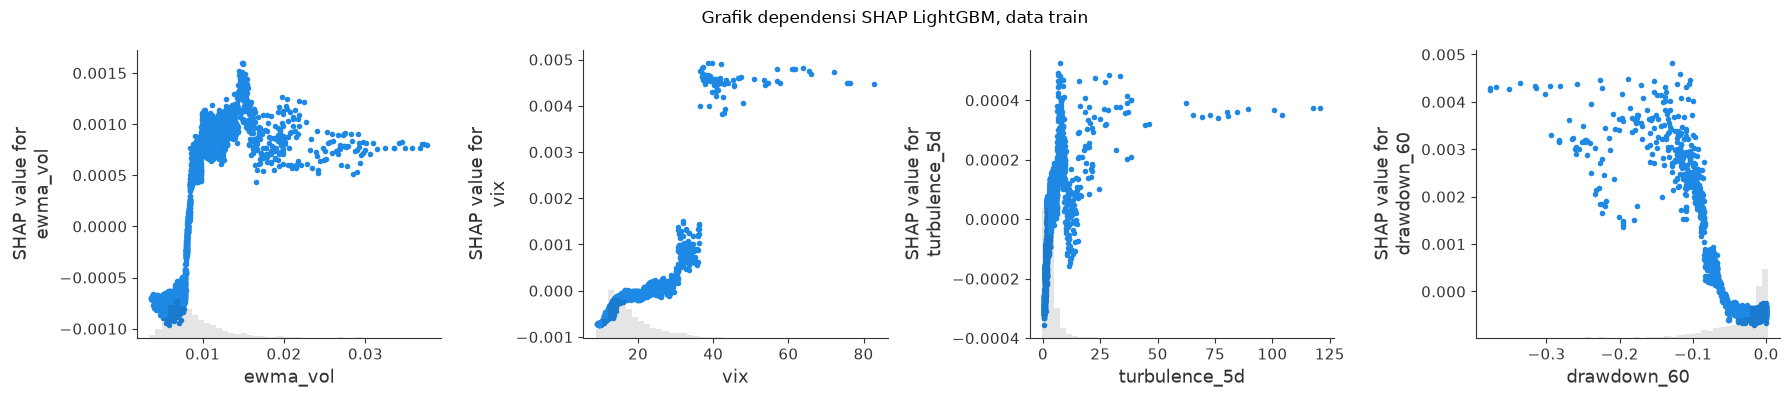

In [233]:
sv_lgbm_tr = pohon(tr[fitur_cols])
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, ["ewma_vol", "vix", "turbulence_5d", "drawdown_60"]):
    shap.plots.scatter(sv_lgbm_tr[:, k], ax=ax, show=False)
fig.suptitle("Grafik dependensi SHAP LightGBM, data train")
plt.tight_layout()
plt.show()

**Interaksi.** Nilai interaksi SHAP memisahkan efek tunggal tiap fitur dari efek gabungan dua fitur. Kalau porsi efek tunggal besar, asumsi aditif model linear sudah cukup.

In [234]:
interaksi = np.abs(pohon.shap_interaction_values(tr[fitur_cols])).mean(0)
np.trace(interaksi) / interaksi.sum()

np.float64(0.6943505435923265)

In [235]:
pd.DataFrame(interaksi, index=fitur_cols, columns=fitur_cols).where(np.triu(np.ones(interaksi.shape, dtype=bool), 1)).stack().nlargest(5).round(6)

drawdown_60  usdidr_ret5     0.000060
ewma_vol     spread_chg60    0.000039
rv5          drawdown_60     0.000034
drawdown_60  rv20_gold       0.000028
rv10         ewma_vol        0.000028
dtype: float64

- **Peringkat SHAP Ridge dan LightGBM berkorelasi 0,80**, jadi penjelasan tidak bergantung pada model.
- **Pola ambang:** VIX berpengaruh di atas sekitar 30, drawdown setelah sekitar 7%.
- **Interaksi kecil** (efek tunggal 69%), jadi model linear cukup.

**Zona rawan:** VIX di atas sekitar 30 dan IHSG lebih dari 7% di bawah puncak 60 hari.

## 9.6 Ringkasan untuk manajer risiko

| Status | Tindakan | Diikuti volatilitas tinggi |
|---|---|---|
| NORMAL | Biasa | 4,3% hari |
| WASPADA | Tinjau eksposur | 13,8% hari |
| BAHAYA | Aktifkan mitigasi | 60,6% hari |

**Penggerak:** volatilitas terkini dan penurunan dari puncak (58%), stres lintas aset (23%), ketakutan global (16%). **Tidak andal** saat guncangan dari kondisi tenang.

## Hasil analisis dari bab ini

- Kelima hipotesis berkontribusi, dengan pemicu berbeda di tiap krisis.
- 8 April 2025 dipicu ketiga fitur andalan.
- Kesalahan sistematis: guncangan dari kondisi tenang.
- Penjelasan konsisten dengan LightGBM (0,80).

# Bab 10. Kesimpulan

Bisakah komite diberi tahu sebelum bursa buka bahwa lima hari ke depan akan bergejolak, beserta alasannya? **Bisa, sebagai indikator rezim risiko, dengan batas yang jelas.**

## 10.1 Temuan utama

1. **Y berisik**, dan akurasi model sudah mendekati batas noise-nya.
2. **Fitur andalan terbukti menambah nilai** di atas HAR (QLIKE p = 0,011).
3. **Kebocoran halus** bisa lolos uji standar, dan uji kontrol menangkapnya.
4. **Model sederhana cukup:** Ridge setara atau lebih baik daripada model yang lebih rumit.
5. **Alarm adalah soal biaya:** 95% episode tertangkap dengan alarm di 42% hari.
6. **Guncangan dari kondisi tenang** tidak punya jejak di data harian.

## 10.2 Jawaban studi kasus

| Syarat studi kasus | Jawaban | Bagian |
|---|---|---|
| **Task 1.** Minimal 3 fitur turunan baru | 13 fitur dari 5 hipotesis, semuanya dari `dataset peserta.csv`. Tiga andalan: X1 `turbulence_5d`, X2 `drawdown_60`, X3 `vix_chg5` | 5.1, 5.3 |
| Rasionalitas bisnis dan finansial | Hipotesis ekonomi dan dasar literatur tiap fitur, berakar di temuan EDA | 4 (penutup), 5.1 |
| Uji validitas kuantitatif | Korelasi train dan validasi, heatmap korelasi per tahun, median Y per kuintil, ablation, uji nilai tambah di atas HAR (signifikan dengan QLIKE, p = 0,011), SHAP | 5.4, 7.7, 7.9, 9.1 |
| **Task 2.** Potong data berurutan | Train 2010 sampai 2022, validasi 2023 sampai 2024, test 2025 ke atas, embargo 5 hari | 6.1 |
| Fit hanya dari train | Scaler di dalam `Pipeline`, bukti rata-rata scaler sama dengan rata-rata train, turbulence tanpa parameter global | 6.1, 6.6, 7.3 |
| Bukti fitur hari t tidak memakai t+1 | Lima uji, termasuk kontrol yang membuktikan uji sanggup mendeteksi kebocoran | 6.2 sampai 6.6 |
| Data 2025 ke atas sebagai data uji | Prediksi dan status test tersimpan di CSV | 8.6 |
| **Task 3.** Satu model terbaik dan alasannya | Ridge, dibandingkan dengan LightGBM, Random Forest, GARCH, dan hibrida | 7 (pembuka), Lampiran B |
| Hyperparameter tuning dengan data latih | `RidgeCV` dengan CV berurutan dan kurva alpha. Pembanding: LightGBM 40 kombinasi, Random Forest | 7.3, Lampiran B |
| RMSE atau MAE di validasi | RMSE 0,00322, MAE 0,00263, R2 out-of-sample 0,335 | 7.4, 7.5 |
| Benchmark terhadap baseline | 20,2% lebih kecil daripada naif `rv5` (Diebold-Mariano p = 0,001), diuji lagi di walk-forward 10 tahun, signifikan lebih akurat daripada EWMA dan HAR dengan QLIKE | 7.4, 7.6 |
| XAI global | SHAP beeswarm dan bar, per hipotesis, per tahun | 9.1, 9.2 |
| XAI lokal dengan bahasa bisnis | 8 April 2025 (test) dan 26 Maret 2020 (Y diketahui) | 9.3 |
| Analisis kesalahan berbasis XAI | 31 Juli dan 5 Agustus 2024, pola sistematis di 127 hari berbahaya, permutation importance | 9.4, 9.5 |
| **Tambahan.** Sistem peringatan dini | Alarm walk-forward, tiga mode kepekaan (di validasi, mode peka 2 dari 3 episode), pita risiko, status berjenjang | 8 |

## 10.3 Keterbatasan

- Guncangan dari kondisi tenang lolos (37 dari 127 hari berbahaya).
- R2 sklearn validasi -0,022 (R2 out-of-sample 0,335). Koreksi bias tidak lolos (Lampiran D).
- Dengan MSE, keunggulan atas HAR (p = 0,067) dan nilai tambah fitur andalan (p = 0,13) belum signifikan. Dengan QLIKE signifikan.
- Mode seimbang 0 dari 8 hari berbahaya di validasi.
- Data hanya harga penutupan, tanpa kalender libur, yield, atau aliran dana asing.

## 10.4 Rekomendasi untuk PT Investion

1. Pakai sebagai indikator **rezim risiko**, bukan pemicu otomatis.
2. **Pilih mode menurut toleransi alarm palsu:** seimbang untuk status harian, peka bila komite ingin menangkap hampir semua episode (19 dari 20) dengan alarm di 42% hari.
3. Latih ulang model dan ambang setiap tahun.
4. Tambahkan data jadwal peristiwa (libur bursa, FOMC, rapat BI) bila diizinkan.

# Lampiran

Uji tambahan yang menguatkan, tetapi tidak mengubah, kesimpulan utama: Granger (A), model tambahan (B), guncangan dari kondisi tenang (C), dan upaya memperbaiki bias level dan alarm (D).

**Kode lampiran disembunyikan** supaya hasilnya mudah dibaca. Kodenya tetap ada dan ikut dijalankan; klik sel yang terlipat untuk membukanya.

## Lampiran A. Uji kausalitas Granger

Apakah nilai lampau sebuah variabel membantu memprediksi IHSG setelah nilai lampau IHSG sendiri diperhitungkan? Uji F biasa dan robust (HAC), jeda 1 sampai 10 hari. Granger menunjukkan daya prediksi, bukan sebab-akibat.

In [236]:
stasioner = {"return IHSG": r, "|return| IHSG": r.abs(), **{k: v for k, v in ret_pasar.items()}, **{f"|{k}|": v.abs() for k, v in ret_pasar.items()}}
pd.Series({k: adfuller(v.dropna(), result_object=False)[1] for k, v in stasioner.items()}).round(5)

return IHSG      0.0
|return| IHSG    0.0
S&P 500          0.0
VIX              0.0
USDIDR           0.0
Emas             0.0
Minyak           0.0
|S&P 500|        0.0
|VIX|            0.0
|USDIDR|         0.0
|Emas|           0.0
|Minyak|         0.0
dtype: float64

Semua p-value ADF sangat kecil (di bawah 0,00005), jadi seluruh deret stasioner dan layak diuji.

In [237]:
def p_granger(y, x, jeda, robust):
    kolom = [y.rename("y")] + [y.shift(i).rename(f"y{i}") for i in range(1, jeda + 1)] + [x.shift(i).rename(f"x{i}") for i in range(1, jeda + 1)]
    z = pd.concat(kolom, axis=1).dropna()
    hasil = sm.OLS(z["y"], sm.add_constant(z.drop(columns="y"))).fit(cov_type="HAC" if robust else "nonrobust", cov_kwds={"maxlags": 5} if robust else {})
    return float(hasil.wald_test(", ".join(f"x{i} = 0" for i in range(1, jeda + 1)), use_f=True, scalar=True).pvalue)

**Target 1: return IHSG, prediktor perubahan variabel.**

In [238]:
pd.DataFrame({k: {(versi, f"jeda {j}"): p_granger(r, ret_pasar[k], j, robust) for versi, robust in [("biasa", False), ("robust", True)] for j in (1, 2, 5, 10)}
              for k in ret_pasar}).T.round(4)

biasa                          robust                        
         jeda 1  jeda 2  jeda 5 jeda 10  jeda 1  jeda 2  jeda 5 jeda 10
S&P 500  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
VIX      0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
USDIDR   0.0061  0.0013  0.0009  0.0151  0.0310  0.0138  0.0345  0.2126
Emas     0.0002  0.0009  0.0000  0.0000  0.0035  0.0149  0.0070  0.0332
Minyak   0.0000  0.0000  0.0000  0.0000  0.0174  0.0403  0.0011  0.0000

S&P 500 dan VIX sangat signifikan di semua jeda. Minyak, emas, dan kurs jauh lebih lemah di versi robust.

**Target 2: |return| IHSG (volatilitas), prediktor besar gerakan variabel.**

In [239]:
pd.DataFrame({k: {(versi, f"jeda {j}"): p_granger(r.abs(), ret_pasar[k].abs(), j, robust) for versi, robust in [("biasa", False), ("robust", True)] for j in (1, 2, 5, 10)}
              for k in ret_pasar}).T.round(4)

biasa                          robust                        
         jeda 1  jeda 2  jeda 5 jeda 10  jeda 1  jeda 2  jeda 5 jeda 10
S&P 500  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
VIX      0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
USDIDR   0.0000  0.0000  0.0000  0.0001  0.0001  0.0007  0.0023  0.0187
Emas     0.0000  0.0000  0.0000  0.0001  0.0000  0.0000  0.0025  0.0075
Minyak   0.0054  0.0593  0.0564  0.0500  0.0263  0.1476  0.0994  0.0011

- **S&P 500 dan VIX mendahului volatilitas IHSG**, dasar kuat untuk X1 dan X3.
- **Kurs dan emas** signifikan hanya di jeda pendek.
- **Minyak** tidak konsisten.

## Lampiran B. Percobaan model tambahan

### B.1 Percobaan model dari literatur

Parameter dari train saja, dibandingkan dengan Ridge di out-of-fold train, validasi, dan walk-forward: GJR-GARCH, EGARCH, HAR log(Y), regime switching, hibrida GARCH, dan LightGBM yang dituning. GARCH-MIDAS tidak dipakai (manfaat makro bulanan untuk horizon di atas satu kuartal).

**GJR-GARCH.** Parameter diestimasi di return train saja, dengan distribusi t karena return berekor gemuk (kurtosis 8,3). Satuan return: persen.

In [240]:
ret_persen = 100 * np.log(data["IHSG"]).diff().dropna()

In [241]:
gjr = arch_model(ret_persen.loc[:tr.index.max()], dist="t", vol="GARCH", p=1, o=1, q=1).fit(disp="off")

In [242]:
gjr.params.round(3)

mu          0.052
omega       0.034
alpha[1]    0.035
gamma[1]    0.109
beta[1]     0.876
nu          4.727
Name: params, dtype: float64

GJR-GARCH mengonfirmasi EDA: **efek leverage** (`gamma` 0,109, guncangan negatif sekitar empat kali lebih berpengaruh), persistensi tinggi (0,966), dan ekor gemuk (`nu` 4,7).

In [243]:
ramalan = pd.DataFrame(index=data.index)
gjr_tetap = arch_model(ret_persen, dist="t", vol="GARCH", p=1, o=1, q=1).fix(gjr.params)
ramalan["gjr"] = np.sqrt(gjr_tetap.forecast(start=0, horizon=5, reindex=True).variance.mean(axis=1)) / 100

**EGARCH** (seed tetap supaya hasil sama setiap dijalankan) dan **regime switching** dengan **filter**, bukan smoother yang melihat masa depan.

In [244]:
egarch = arch_model(ret_persen.loc[:tr.index.max()], dist="t", vol="EGARCH", p=1, o=1, q=1).fit(disp="off")
egarch_tetap = ConstantMean(ret_persen, volatility=EGARCH(p=1, o=1, q=1), distribution=StudentsT(seed=0)).fix(egarch.params)
fc = egarch_tetap.forecast(start=0, horizon=5, method="simulation", simulations=400, reindex=True)
ramalan["egarch"] = np.sqrt(fc.variance.mean(axis=1)) / 100

In [245]:
ms = MarkovRegression(ret_persen.loc[:tr.index.max()], k_regimes=2, switching_variance=True).fit(disp=False)

In [246]:
ms.params.round(3)

p[0->0]      0.977
p[1->0]      0.127
const[0]     0.077
const[1]    -0.233
sigma2[0]    0.508
sigma2[1]    4.133
dtype: float64

In [247]:
sigma2 = np.array([ms.params["sigma2[0]"], ms.params["sigma2[1]"]])
ms_penuh = MarkovRegression(ret_persen, k_regimes=2, switching_variance=True).smooth(ms.params)
ramalan["prob_krisis"] = ms_penuh.filtered_marginal_probabilities[int(sigma2.argmax())].reindex(data.index)
ramalan["ms_vol"] = np.sqrt(ramalan["prob_krisis"] * sigma2.max() + (1 - ramalan["prob_krisis"]) * sigma2.min()) / 100

Dua rezim yang masuk akal: **tenang** (simpangan baku harian 0,71%, bertahan rata-rata 43 hari) dan **krisis** (2,03%, rata-rata 8 hari, return rata-rata negatif).

In [248]:
tr_alt, va_alt = tr.join(ramalan), va.join(ramalan)
pd.DataFrame({"train": tr_alt.corr(method="spearman")["Y"], "validasi": va_alt.corr(method="spearman")["Y"]}).loc[["gjr", "egarch", "prob_krisis", "ms_vol", "ewma_vol"]].round(3)

,train,validasi
gjr,0.395,0.306
egarch,0.395,0.285
prob_krisis,0.347,0.255
ms_vol,0.347,0.255
ewma_vol,0.416,0.291


**LightGBM yang dituning** (pembanding tidak linear) memakai pencarian acak 40 kombinasi dengan CV yang sama, hanya di data train. Targetnya akar Y.

In [249]:
grid = {"regressor__n_estimators": [200, 400, 800], "regressor__learning_rate": [0.01, 0.03, 0.05],
        "regressor__num_leaves": [7, 15, 31], "regressor__min_child_samples": [20, 50, 100],
        "regressor__subsample": [0.7, 1.0], "regressor__colsample_bytree": [0.6, 0.8, 1.0], "regressor__reg_lambda": [0, 1, 5]}

In [250]:
dasar_lgbm = TransformedTargetRegressor(lgb.LGBMRegressor(subsample_freq=1, random_state=42, verbose=-1), func=np.sqrt, inverse_func=np.square)
search = RandomizedSearchCV(dasar_lgbm, grid, n_iter=40, cv=cv, scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1).fit(tr[fitur_cols], y_tr)
model_lgbm = search.best_estimator_

**Perbandingan di out-of-fold train dan validasi** (HAR log(Y) memakai koreksi bias `exp(s²/2)`).

In [251]:
langsung = ["ewma_vol", "gjr", "egarch", "ms_vol"]
pd.DataFrame({k: {"RMSE OOF": root_mean_squared_error(y_tr.loc[oof.index], tr_alt.loc[oof.index, k]), "R2 OOF": r2_score(y_tr.loc[oof.index], tr_alt.loc[oof.index, k]),
                  "RMSE validasi": root_mean_squared_error(y_va, va_alt[k]), "R2 validasi": r2_score(y_va, va_alt[k])} for k in langsung}).T.round(4)

,RMSE OOF,R2 OOF,RMSE validasi,R2 validasi
ewma_vol,0.0048,0.1987,0.0033,-0.0657
gjr,0.0046,0.2860,0.0037,-0.3531
egarch,0.0046,0.2846,0.0038,-0.3911
ms_vol,0.0051,0.1089,0.0041,-0.6713


In [252]:
kandidat = {"GJR + kalibrasi linear": (LinearRegression(), ["gjr"]),
            "HAR": (LinearRegression(), har_cols),
            "Ridge 13 fitur (model utama)": (ridge, fitur_cols),
            "Ridge 13 fitur + GJR": (ridge, fitur_cols + ["gjr"]),
            "Ridge 13 fitur + GJR + rezim": (ridge, fitur_cols + ["gjr", "prob_krisis"]),
            "LightGBM dituning": (model_lgbm, fitur_cols),
            "LightGBM + GJR": (model_lgbm, fitur_cols + ["gjr"]),
            "LightGBM + GJR + rezim": (model_lgbm, fitur_cols + ["gjr", "prob_krisis"])}

In [253]:
oof_alt = {k: pd.concat([pd.Series(clone(m).fit(tr_alt[c].iloc[a], y_tr.iloc[a]).predict(tr_alt[c].iloc[b]), index=tr_alt.index[b]) for a, b in cv.split(tr_alt)])
           for k, (m, c) in kandidat.items()}
pred_alt = {k: clone(m).fit(tr_alt[c], y_tr).predict(va_alt[c]) for k, (m, c) in kandidat.items()}

In [254]:
pd.DataFrame({k: {"RMSE OOF": root_mean_squared_error(y_tr.loc[oof_alt[k].index], oof_alt[k]), "R2 OOF": r2_score(y_tr.loc[oof_alt[k].index], oof_alt[k]),
                  "RMSE validasi": root_mean_squared_error(y_va, pred_alt[k]), "R2 validasi": r2_score(y_va, pred_alt[k])} for k in kandidat}).T.round(4)

,RMSE OOF,R2 OOF,RMSE validasi,R2 validasi
GJR + kalibrasi linear,0.0044,0.3380,0.0033,-0.0445
HAR,0.0047,0.2504,0.0033,-0.0695
Ridge 13 fitur (model utama),0.0044,0.3375,0.0032,-0.0218
Ridge 13 fitur + GJR,0.0044,0.3447,0.0032,-0.0215
Ridge 13 fitur + GJR + rezim,0.0044,0.3494,0.0032,-0.0357
LightGBM dituning,0.0047,0.2564,0.0032,-0.0332
LightGBM + GJR,0.0047,0.2455,0.0032,-0.0306
LightGBM + GJR + rezim,0.0047,0.2501,0.0032,-0.0374


In [255]:
har_log_oof = []
for a, b in cv.split(tr_alt):
    log_a = np.log(y_tr.iloc[a].clip(lower=5e-4))
    m_log = LinearRegression().fit(np.log(tr_alt[har_cols].iloc[a].clip(lower=5e-4)), log_a)
    s2 = ((log_a - m_log.predict(np.log(tr_alt[har_cols].iloc[a].clip(lower=5e-4)))) ** 2).mean()
    har_log_oof.append(pd.Series(np.exp(m_log.predict(np.log(tr_alt[har_cols].iloc[b].clip(lower=5e-4))) + s2 / 2), index=tr_alt.index[b]))
har_log_oof = pd.concat(har_log_oof)
root_mean_squared_error(y_tr.loc[har_log_oof.index], har_log_oof), r2_score(y_tr.loc[har_log_oof.index], har_log_oof)

(0.004769291083014452, 0.2208566703091066)

**Walk-forward 2015 sampai 2024**, semua parameter dipelajari ulang tiap tahun dari data sebelumnya.

In [256]:
baris = []
for tahun in range(2015, 2025):
    batas = str(tahun - 1)
    gjr_t = arch_model(ret_persen.loc[:batas], dist="t", vol="GARCH", p=1, o=1, q=1).fit(disp="off")
    tab = tabel.copy()
    tab["gjr"] = np.sqrt(arch_model(ret_persen, dist="t", vol="GARCH", p=1, o=1, q=1).fix(gjr_t.params).forecast(start=0, horizon=5, reindex=True).variance.mean(axis=1)) / 100
    tab = tab.dropna()
    tr_t, te_t = tab.loc[:batas].iloc[:-5], tab.loc[str(tahun)]
    kej_t = te_t["Y"] > tr_t["Y"].quantile(0.8)
    skor_t = {"naif rv5": te_t["rv5"], "EWMA": te_t["ewma_vol"], "GJR + kalibrasi": LinearRegression().fit(tr_t[["gjr"]], tr_t["Y"]).predict(te_t[["gjr"]]),
              "HAR": LinearRegression().fit(tr_t[har_cols], tr_t["Y"]).predict(te_t[har_cols])}
    for nama, (m, c) in {"Ridge": (ridge, fitur_cols), "Ridge + GJR": (ridge, fitur_cols + ["gjr"]),
                         "LightGBM": (model_lgbm, fitur_cols), "LightGBM + GJR": (model_lgbm, fitur_cols + ["gjr"])}.items():
        skor_t[nama] = clone(m).fit(tr_t[c], tr_t["Y"]).predict(te_t[c])
    baris += [{"tahun": tahun, "model": k, "RMSE": root_mean_squared_error(te_t["Y"], v), "AUC": roc_auc_score(kej_t, v), "PR-AUC": average_precision_score(kej_t, v)} for k, v in skor_t.items()]
wf_alt = pd.DataFrame(baris)

In [257]:
wf_alt.groupby("model")[["RMSE", "AUC", "PR-AUC"]].mean().sort_values("RMSE").round(4)

,RMSE,AUC,PR-AUC
model,,,
Ridge + GJR,0.0039,0.6832,0.3051
Ridge,0.0039,0.6787,0.2945
GJR + kalibrasi,0.0039,0.6289,0.2526
LightGBM,0.0040,0.6512,0.2710
LightGBM + GJR,0.0040,0.6515,0.2698
HAR,0.0041,0.5856,0.2250
EWMA,0.0042,0.5488,0.2119
naif rv5,0.0051,0.5969,0.2231


In [258]:
rmse_th = wf_alt.pivot(index="tahun", columns="model", values="RMSE")
auc_th = wf_alt.pivot(index="tahun", columns="model", values="AUC")
pd.DataFrame({"tahun menang RMSE vs Ridge": rmse_th.lt(rmse_th["Ridge"], axis=0).sum(),
              "tahun menang AUC vs Ridge": auc_th.gt(auc_th["Ridge"], axis=0).sum()}).drop("Ridge")

,tahun menang RMSE vs Ridge,tahun menang AUC vs Ridge
model,,
EWMA,2,2
GJR + kalibrasi,3,3
HAR,1,2
LightGBM,4,3
LightGBM + GJR,5,4
Ridge + GJR,8,7
naif rv5,0,1


- **GJR-GARCH:** terbaik sebagai ramalan langsung di train (R2 OOF 0,29), tetapi terlalu tinggi di validasi.
- **Regime switching** dan **HAR log(Y)** tidak lebih baik.
- **Ridge + GJR:** naik tipis (AUC 0,679 ke 0,683), tidak sepadan.
- **LightGBM** kalah dari Ridge (R2 OOF 0,256 vs 0,338, AUC 0,651 vs 0,679).

**Ridge tetap terbaik.**

**Fitur berjeda** (5, 10, 20 hari lalu) untuk tujuh fitur utama.

In [259]:
kolom_jeda = ["vix", "vix_chg5", "turbulence_5d", "usdidr_ret5", "rv20_gold", "drawdown_60", "ewma_vol"]
fitur_jeda = pd.concat([fitur[kolom_jeda].shift(j).add_suffix(f"_jeda{j}") for j in (5, 10, 20)], axis=1)
tr_j, va_j = tr.join(fitur_jeda).dropna(), va.join(fitur_jeda)

In [260]:
set_jeda = {"13 fitur (pembanding)": fitur_cols}
set_jeda |= {f"+ jeda {j} hari": fitur_cols + [f"{c}_jeda{j}" for c in kolom_jeda] for j in (5, 10, 20)}
set_jeda["+ jeda 5, 10, 20 hari"] = fitur_cols + list(fitur_jeda.columns)
oof_j = {k: pd.concat([pd.Series(clone(ridge).fit(tr_j[c].iloc[a], tr_j["Y"].iloc[a]).predict(tr_j[c].iloc[b]), index=tr_j.index[b]) for a, b in cv.split(tr_j)])
         for k, c in set_jeda.items()}
pred_j = {k: clone(ridge).fit(tr_j[c], tr_j["Y"]).predict(va_j[c]) for k, c in set_jeda.items()}

In [261]:
pd.DataFrame({k: {"RMSE OOF": root_mean_squared_error(tr_j["Y"].loc[oof_j[k].index], oof_j[k]), "R2 OOF": r2_score(tr_j["Y"].loc[oof_j[k].index], oof_j[k]),
                  "RMSE validasi": root_mean_squared_error(y_va, pred_j[k]), "R2 validasi": r2_score(y_va, pred_j[k])} for k in set_jeda}).T.round(4)

,RMSE OOF,R2 OOF,RMSE validasi,R2 validasi
13 fitur (pembanding),0.0044,0.3371,0.0032,-0.0170
+ jeda 5 hari,0.0044,0.3361,0.0032,-0.0157
+ jeda 10 hari,0.0044,0.3294,0.0032,-0.0254
+ jeda 20 hari,0.0045,0.3013,0.0032,-0.0094
"+ jeda 5, 10, 20 hari",0.0045,0.3150,0.0032,-0.0100


Fitur berjeda **tidak memperbaiki** out-of-fold (R2 0,301 sampai 0,336 vs 0,337). Nilai fitur saat ini sudah merangkum 5 sampai 60 hari terakhir, sejalan dengan 4.7.

### B.2 Hibrida GARCH dan Random Forest (Fathoni et al., 2025)

Versi asli (`ret` dan `gjr`) dan versi 13 fitur + `gjr`. **Kriteria (ditetapkan sebelum melihat hasil):** lebih baik daripada Ridge di RMSE OOF, AUC walk-forward, **dan** RMSE validasi.

In [262]:
ret_harian = np.log(data["IHSG"]).diff().rename("ret")
tr_rf, va_rf = tr_alt.join(ret_harian), va_alt.join(ret_harian)

In [263]:
set_rf = {"RF (ret + gjr), rancangan Fathoni": ["ret", "gjr"], "RF 13 fitur + gjr": fitur_cols + ["gjr"]}
rf_grid = {"max_depth": [3, 5, 8], "min_samples_leaf": [10, 30, 60], "max_features": [0.3, 0.6, 1.0], "n_estimators": [300]}

In [264]:
rf_terbaik = {k: RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), rf_grid, n_iter=12, cv=cv,
                                    scoring="neg_root_mean_squared_error", random_state=42).fit(tr_rf[c], y_tr).best_estimator_
              for k, c in set_rf.items()}

In [265]:
pd.DataFrame({k: m.get_params() for k, m in rf_terbaik.items()}).loc[["max_depth", "min_samples_leaf", "max_features"]]

,"RF (ret + gjr), rancangan Fathoni",RF 13 fitur + gjr
max_depth,5,5
min_samples_leaf,30,10
max_features,1.0,0.3


**Perbandingan di out-of-fold train dan validasi.**

In [266]:
oof_rf = {k: pd.concat([pd.Series(clone(rf_terbaik[k]).fit(tr_rf[c].iloc[a], y_tr.iloc[a]).predict(tr_rf[c].iloc[b]), index=tr_rf.index[b]) for a, b in cv.split(tr_rf)])
          for k, c in set_rf.items()}
pred_rf = {k: rf_terbaik[k].predict(va_rf[c]) for k, c in set_rf.items()}

In [267]:
oof_semua = {k: oof_alt[k] for k in ["HAR", "Ridge 13 fitur (model utama)", "Ridge 13 fitur + GJR"]} | oof_rf
pred_semua = {k: pred_alt[k] for k in ["HAR", "Ridge 13 fitur (model utama)", "Ridge 13 fitur + GJR"]} | pred_rf
pd.DataFrame({k: {"RMSE OOF": root_mean_squared_error(y_tr.loc[oof_semua[k].index], oof_semua[k]), "R2 OOF": r2_score(y_tr.loc[oof_semua[k].index], oof_semua[k]),
                  "RMSE validasi": root_mean_squared_error(y_va, pred_semua[k]), "R2 validasi": r2_score(y_va, pred_semua[k])} for k in oof_semua}).T.round(4)

,RMSE OOF,R2 OOF,RMSE validasi,R2 validasi
HAR,0.0047,0.2504,0.0033,-0.0695
Ridge 13 fitur (model utama),0.0044,0.3375,0.0032,-0.0218
Ridge 13 fitur + GJR,0.0044,0.3447,0.0032,-0.0215
"RF (ret + gjr), rancangan Fathoni",0.0046,0.2733,0.0032,-0.0380
RF 13 fitur + gjr,0.0045,0.2957,0.0033,-0.0676


**Walk-forward 2015 sampai 2024**, parameter dipelajari ulang tiap tahun.

In [268]:
baris = []
for tahun in range(2015, 2025):
    batas = str(tahun - 1)
    gjr_t = arch_model(ret_persen.loc[:batas], dist="t", vol="GARCH", p=1, o=1, q=1).fit(disp="off")
    tab = tabel.join(ret_harian)
    tab["gjr"] = np.sqrt(arch_model(ret_persen, dist="t", vol="GARCH", p=1, o=1, q=1).fix(gjr_t.params).forecast(start=0, horizon=5, reindex=True).variance.mean(axis=1)) / 100
    tab = tab.dropna()
    tr_t, te_t = tab.loc[:batas].iloc[:-5], tab.loc[str(tahun)]
    kej_t = te_t["Y"] > tr_t["Y"].quantile(0.8)
    skor_t = {"EWMA": te_t["ewma_vol"], "HAR": LinearRegression().fit(tr_t[har_cols], tr_t["Y"]).predict(te_t[har_cols])}
    for nama, (m, c) in {"Ridge": (ridge, fitur_cols), "Ridge + GJR": (ridge, fitur_cols + ["gjr"]),
                         "RF (ret + gjr)": (rf_terbaik["RF (ret + gjr), rancangan Fathoni"], ["ret", "gjr"]),
                         "RF 13 fitur + gjr": (rf_terbaik["RF 13 fitur + gjr"], fitur_cols + ["gjr"])}.items():
        skor_t[nama] = clone(m).fit(tr_t[c], tr_t["Y"]).predict(te_t[c])
    baris += [{"tahun": tahun, "model": k, "RMSE": root_mean_squared_error(te_t["Y"], v), "AUC": roc_auc_score(kej_t, v), "PR-AUC": average_precision_score(kej_t, v)} for k, v in skor_t.items()]
wf_rf = pd.DataFrame(baris)

In [269]:
wf_rf.groupby("model")[["RMSE", "AUC", "PR-AUC"]].mean().sort_values("RMSE").round(4)

,RMSE,AUC,PR-AUC
model,,,
Ridge + GJR,0.0039,0.6832,0.3051
Ridge,0.0039,0.6787,0.2945
RF 13 fitur + gjr,0.0040,0.6423,0.2668
RF (ret + gjr),0.0041,0.6124,0.2667
HAR,0.0041,0.5856,0.2250
EWMA,0.0042,0.5488,0.2119


In [270]:
rmse_rf = wf_rf.pivot(index="tahun", columns="model", values="RMSE")
auc_rf = wf_rf.pivot(index="tahun", columns="model", values="AUC")
pd.DataFrame({"tahun menang RMSE vs Ridge": rmse_rf.lt(rmse_rf["Ridge"], axis=0).sum(),
              "tahun menang AUC vs Ridge": auc_rf.gt(auc_rf["Ridge"], axis=0).sum()}).drop("Ridge")

,tahun menang RMSE vs Ridge,tahun menang AUC vs Ridge
model,,
EWMA,2,2
HAR,1,2
RF (ret + gjr),4,1
RF 13 fitur + gjr,3,4
Ridge + GJR,8,7


**Ditolak**, tidak ada kriteria terpenuhi:

| Kriteria | Ridge | RF 13 fitur + gjr | RF (ret + gjr) |
|---|---|---|---|
| RMSE OOF (R2 OOF) | 0,0044 (0,338) | 0,0045 (0,296) | 0,0046 (0,273) |
| AUC walk-forward | 0,679 | 0,642 | 0,612 |
| RMSE validasi (R2) | 0,0032 (-0,022) | 0,0033 (-0,068) | 0,0032 (-0,038) |

### B.3 Seberapa awal peringatannya? Analisis lead time

Apakah alarm sudah menyala dalam 10 hari sebelum episode dimulai? HAR dan EWMA diberi jumlah hari beralarm yang sama dengan Ridge.

**Train (out-of-fold, 2013 sampai 2022).**

In [271]:
skor_lt = {"Ridge": oof, "HAR": oof_har, "EWMA": tr.loc[oof.index, "ewma_vol"]}
ambang_lt = {k: v.quantile(1 - (oof > ambang_alarm).mean()) for k, v in skor_lt.items()}
ambang_lt["Ridge"] = ambang_alarm
pd.DataFrame({k: ringkas(v > ambang_lt[k], kejadian) for k, v in skor_lt.items()}).round(2)

,Ridge,HAR,EWMA
sudah menyala,15.00,11.00,14.00
baru menyala,6.00,10.00,0.00
tanpa alarm,12.00,12.00,19.00
median lead (baru menyala),3.50,5.00,NaN
run alarm,105.00,129.00,39.00
run berujung episode,25.00,37.00,12.00
hari beralarm,0.28,0.28,0.28


**Validasi (2023 sampai 2024)**, dengan ambang yang sama dari train, tanpa diubah.

In [272]:
skor_va = {"Ridge": pd.Series(pred_va, index=va.index), "HAR": pd.Series(har.predict(va[har_cols]), index=va.index), "EWMA": va["ewma_vol"]}
pd.DataFrame({k: ringkas(v > ambang_lt[k], kej_va) for k, v in skor_va.items()}).round(2)

,Ridge,HAR,EWMA
sudah menyala,0.00,0.00,0.00
baru menyala,1.00,0.00,0.00
tanpa alarm,2.00,3.00,3.00
median lead (baru menyala),9.00,NaN,NaN
run alarm,15.00,17.00,5.00
run berujung episode,2.00,0.00,0.00
hari beralarm,0.09,0.06,0.02


In [273]:
kategori_episode(skor_va["Ridge"] > ambang_alarm, kej_va)

,status,lead
mulai,,
2024-04-25,tanpa alarm,NaN
2024-07-29,tanpa alarm,NaN
2024-11-27,baru menyala,9.0


| | Ridge | HAR | EWMA |
|---|---|---|---|
| Train: episode (33) sudah menyala / baru menyala / tanpa alarm | 15 / 6 / 12 | 11 / 10 / 12 | 14 / 0 / 19 |
| Train: median lead | 3,5 hari | 5 hari | tidak ada |
| Validasi: episode (3) didahului alarm | 1 (lead 9 hari) | 0 | 0 |

Ridge dan HAR mendeteksi 21 dari 33 episode, EWMA 14 dan tidak pernah memberi peringatan baru. Untuk guncangan dari kondisi tenang, semua model telat.

### B.4 Apakah klasifikasi langsung lebih baik untuk peringatan dini?

Regresi logistik di walk-forward yang sama. Penalti dipilih dengan Brier score (AUC tidak terdefinisi di fold tanpa kejadian).

In [274]:
baris_logit = []
for tahun in range(2015, 2025):
    tr_t, te_t = tabel.loc[:str(tahun - 1)].dropna().iloc[:-5], tabel.loc[str(tahun)]
    q = tr_t["Y"].quantile(0.9)
    logit = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, cv=TimeSeriesSplit(n_splits=5, gap=5), scoring="neg_brier_score", max_iter=2000)).fit(tr_t[fitur_cols], tr_t["Y"] > q)
    kej_t = te_t["Y"] > q
    if kej_t.any():
        baris_logit.append({"tahun": tahun, "kejadian": kej_t.sum(), "AUC Ridge": roc_auc_score(kej_t, wf_pred.loc[str(tahun), "Ridge"]),
                            "AUC logistik": roc_auc_score(kej_t, logit.predict_proba(te_t[fitur_cols])[:, 1])})
logit_wf = pd.DataFrame(baris_logit).set_index("tahun")
logit_wf.round(3)

,kejadian,AUC Ridge,AUC logistik
tahun,,,
2015,22,0.692,0.728
2016,5,0.545,0.438
2018,26,0.596,0.622
2019,2,0.788,0.724
2020,74,0.783,0.770
2021,5,0.873,0.845
2022,7,0.521,0.424
2024,8,0.595,0.516


In [275]:
logit_wf[["AUC Ridge", "AUC logistik"]].mean().round(3)

AUC Ridge       0.674
AUC logistik    0.633
dtype: float64

**Logistik lebih buruk daripada Ridge:** AUC 0,633 vs 0,674. Klasifikasi membuang informasi besaran Y, padahal dengan sedikit kejadian per tahun informasi itu berharga.

### B.5 Keluarga HAR dan fitur dari literatur

Apakah HAR yang dikembangkan (HAR-J, HAR-CJ, HARQ, HAR-GARCH, ensemble) atau fitur tambahan dari literatur bisa mengalahkan Ridge 13 fitur? Dataset hanya punya harga penutupan, jadi komponen lompatan dan quarticity dihitung dari **return harian** (window 22 hari), bukan data intraday.

**Aturan sama dengan Lampiran D:** dipilih hanya dari walk-forward **2016 sampai 2022**. **Lolos** bila RMSE lebih kecil, lebih baik di minimal 5 dari 7 tahun, **dan** AUC per tahun tidak turun. Semua fitur hanya memakai data sampai hari t.

In [276]:
ret_b5 = np.log(data[["IHSG", "SP500", "USDIDR", "GOLD"]]).diff()
r_ihsg = ret_b5["IHSG"]
bv22 = np.sqrt(np.pi / 2 * (r_ihsg.abs() * r_ihsg.abs().shift(1)).rolling(22).mean())
vol5 = pd.DataFrame({"ihsg": r_ihsg.rolling(20).std(), "sp": ret_b5["SP500"].rolling(20).std(), "fx": ret_b5["USDIDR"].rolling(20).std(),
                     "emas": ret_b5["GOLD"].rolling(20).std(), "vix": data["VIX"]})
absorption = pd.Series(np.nan, index=data.index)
for k in range(250, len(data)):
    kor = ret_b5.iloc[k - 249:k + 1].corr().to_numpy()
    if np.isfinite(kor).all():
        absorption.iloc[k] = np.linalg.eigvalsh(kor)[-1] / 4

In [277]:
def garch_statis(d):
    # parameter tahun T diestimasi dari data sebelum T, lalu dipakai untuk ramalan 5 hari di tahun T
    ret_pct = 100 * np.log(d["IHSG"]).diff().dropna()
    hasil = []
    for th in sorted(set(ret_pct.index.year))[1:]:
        par = arch_model(ret_pct.loc[:str(th - 1)], dist="t", vol="GARCH", p=1, o=1, q=1).fit(disp="off").params
        fc = arch_model(ret_pct.loc[:str(th)], dist="t", vol="GARCH", p=1, o=1, q=1).fix(par).forecast(start=str(th), horizon=5, reindex=False)
        hasil.append(np.sqrt(fc.variance.mean(axis=1)) / 100)
    return pd.concat(hasil).reindex(d.index)

In [278]:
tab_b5 = tabel.assign(
    lompatan=np.sqrt(((r_ihsg ** 2).rolling(22).mean() - bv22 ** 2).clip(lower=0)), bv22=bv22,
    harq=tabel["abs_ret"] * np.sqrt((r_ihsg ** 4).rolling(22).mean()) * 1e3, rv66=r_ihsg.rolling(66).std(),
    garch_vol=garch_statis(data), rv20_fx=ret_b5["USDIDR"].rolling(20).std(), rv5_sp=ret_b5["SP500"].rolling(5).std(),
    rv22_sp=ret_b5["SP500"].rolling(22).std(), ciss_lite=vol5.apply(lambda s: s.expanding(250).rank(pct=True)).mean(axis=1),
    absorption=absorption, vix_z=(data["VIX"] - data["VIX"].rolling(250).mean()) / data["VIX"].rolling(250).std(),
    lompatan_22=(r_ihsg.abs() > 2.5 * r_ihsg.rolling(66).std().shift(1)).astype(float).rolling(22).sum(),
    upside_vol20=np.sqrt((r_ihsg.clip(lower=0) ** 2).rolling(20).mean()), kor_sp=r_ihsg.rolling(66).corr(ret_b5["SP500"].shift(1)))
ols = lambda: LinearRegression()
ridge_b5 = lambda: clone(ridge)
har_set = {"HAR": (ols, har_cols), "HAR + rv66": (ols, har_cols + ["rv66"]), "HAR-J": (ols, har_cols + ["lompatan"]),
           "HAR-CJ": (ols, ["abs_ret", "rv5", "bv22", "lompatan"]), "HARQ": (ols, har_cols + ["harq"]),
           "HAR-GARCH": (ols, har_cols + ["garch_vol"]), "HAR-J-Q-GARCH": (ols, har_cols + ["lompatan", "harq", "garch_vol"])}
pred_b5 = {k: wf_prediksi(tab_b5, c, f) for k, (f, c) in har_set.items()}
pred_b5["Ridge 13 fitur (dipakai)"] = wf_pred["Ridge"]
pred_b5["Ensemble Ridge + HAR-GARCH"] = (wf_pred["Ridge"] + pred_b5["HAR-GARCH"]) / 2
pred_b5["Ridge + lompatan + HARQ"] = wf_prediksi(tab_b5, fitur_cols + ["lompatan", "harq"], ridge_b5)

In [279]:
kandidat_lit = ["rv20_fx", "rv5_sp", "rv22_sp", "ciss_lite", "absorption", "vix_z", "rv66", "lompatan_22", "upside_vol20", "kor_sp", "garch_vol"]
pred_lit = {f"Ridge + {k}": wf_prediksi(tab_b5, fitur_cols + [k], ridge_b5) for k in kandidat_lit}

In [280]:
idx_pilih = wf_pred.loc["2016":"2022"].index
y_pilih = wf_pred.loc[idx_pilih, "Y"]

def banding_b5(p, acuan):
    tahun = range(2016, 2023)
    rmse = lambda q: pd.Series({t: root_mean_squared_error(wf_pred.loc[str(t), "Y"], q.loc[str(t)]) for t in tahun})
    auc = lambda q: pd.Series({t: roc_auc_score(kej80.loc[str(t)], q.loc[str(t)]) for t in tahun})
    qlike = lambda q: np.log(q.loc[idx_pilih].clip(lower=1e-4) ** 2) + y_pilih ** 2 / q.loc[idx_pilih].clip(lower=1e-4) ** 2
    dm = sm.OLS((qlike(p) - qlike(acuan)).to_numpy(), np.ones(len(idx_pilih))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    hasil = {"RMSE": root_mean_squared_error(y_pilih, p.loc[idx_pilih]), "tahun RMSE lebih baik": (rmse(p) < rmse(acuan)).sum(),
             "AUC per tahun": auc(p).mean(), "tahun AUC lebih baik": (auc(p) > auc(acuan)).sum(),
             "selisih QLIKE": dm.params[0], "p QLIKE": dm.pvalues[0]}
    hasil["lolos"] = "ya" if (hasil["RMSE"] < root_mean_squared_error(y_pilih, acuan.loc[idx_pilih]) and hasil["tahun RMSE lebih baik"] >= 5
                              and hasil["AUC per tahun"] >= auc(acuan).mean()) else ""
    return hasil

**Keluarga HAR** dibandingkan dengan HAR (selisih QLIKE negatif = lebih baik daripada HAR).

In [281]:
pd.DataFrame({k: banding_b5(p, pred_b5["HAR"]) for k, p in pred_b5.items()}).T.round(5)

,RMSE,tahun RMSE lebih baik,AUC per tahun,tahun AUC lebih baik,selisih QLIKE,p QLIKE,lolos
HAR,0.004579,0,0.56163,0,0.0,NaN,
HAR + rv66,0.004572,6,0.565118,5,-0.005656,0.336269,ya
HAR-J,0.004567,3,0.563006,4,-0.003942,0.365618,
HAR-CJ,0.004513,4,0.560136,3,-0.008806,0.152715,
HARQ,0.004576,6,0.560267,1,-0.002085,0.123699,
HAR-GARCH,0.004313,6,0.579574,4,0.015239,0.345007,ya
HAR-J-Q-GARCH,0.004319,6,0.577527,5,0.018958,0.277809,ya
Ridge 13 fitur (dipakai),0.004237,6,0.64857,7,-0.063315,0.033691,ya
Ensemble Ridge + HAR-GARCH,0.004213,7,0.625474,6,-0.049077,0.019544,ya
Ridge + lompatan + HARQ,0.004228,5,0.640916,6,-0.063866,0.031294,ya


- **Pengembangan HAR tanpa data intraday tidak berbeda nyata dari HAR** (HAR-J, HAR-CJ, HARQ, HAR + rv66: p QLIKE 0,12 sampai 0,37).
- **HAR-GARCH** menurunkan RMSE (0,00431 vs 0,00458), tetapi QLIKE tidak membaik (selisih +0,015, p = 0,35) dan AUC hanya 0,58.
- Semua varian HAR di bawah Ridge (RMSE 0,00424, AUC 0,649). Kolom "lolos" di tabel ini hanya membandingkan dengan HAR pada RMSE dan AUC, bukan dasar keputusan.

**Semua kandidat** dibandingkan dengan Ridge 13 fitur yang dipakai (selisih QLIKE positif = lebih buruk daripada Ridge).

In [282]:
kandidat_b5 = {k: v for k, v in pred_b5.items() if k not in ("HAR", "Ridge 13 fitur (dipakai)")} | pred_lit
pd.DataFrame({k: banding_b5(p, wf_pred["Ridge"]) for k, p in kandidat_b5.items()}).T.round(5)

,RMSE,tahun RMSE lebih baik,AUC per tahun,tahun AUC lebih baik,selisih QLIKE,p QLIKE,lolos
HAR + rv66,0.004572,2,0.565118,1,0.057658,0.056725,
HAR-J,0.004567,1,0.563006,0,0.059372,0.037315,
HAR-CJ,0.004513,1,0.560136,0,0.054508,0.05172,
HARQ,0.004576,1,0.560267,0,0.06123,0.036759,
HAR-GARCH,0.004313,2,0.579574,1,0.078553,0.005956,
HAR-J-Q-GARCH,0.004319,2,0.577527,1,0.082273,0.004201,
Ensemble Ridge + HAR-GARCH,0.004213,4,0.625474,1,0.014238,0.219157,
Ridge + lompatan + HARQ,0.004228,4,0.640916,3,-0.000551,0.872529,
Ridge + rv20_fx,0.004225,4,0.643622,3,-0.005033,0.119257,
Ridge + rv5_sp,0.004232,4,0.648585,4,-0.001451,0.493883,


- **Seluruh varian HAR kalah dari Ridge:** QLIKE lebih buruk 0,055 sampai 0,082, signifikan untuk HAR-GARCH (p = 0,006) dan HAR-J-Q-GARCH (p = 0,004).
- **Ensemble Ridge + HAR-GARCH** RMSE terendah (0,00421), tetapi hanya lebih baik di 4 dari 7 tahun dan AUC turun (0,625 vs 0,649). **Tidak lolos.**
- **Dari 11 fitur literatur, hanya 2 lolos:** `rv22_sp` (volatilitas S&P 500) dan `kor_sp` (korelasi IHSG dengan S&P 500 kemarin). RMSE turun sekitar 0,5%, selisih QLIKE tidak signifikan (-0,004 dan +0,004), dan `kor_sp` QLIKE-nya malah lebih buruk.
- **`garch_vol`** RMSE terkecil (0,00420), tetapi AUC turun dan QLIKE signifikan lebih buruk (p = 0,044).

Dua lolos dari 11 kandidat wajar muncul karena kebetulan, dan perbaikannya terlalu kecil untuk membenarkan model baru. **Ridge 13 fitur dipertahankan.** Fitur yang ada sudah menangkap hampir semua informasi dari harga penutupan harian, sejalan dengan Audrino dan Chassot (2024): HAR yang di-fit baik sulit dikalahkan.

## Lampiran C. Guncangan dari kondisi tenang: diagnosis dan lapisan penguat

Apakah guncangan dari kondisi tenang (9.4) punya jejak di data harian? Detektor dilatih ulang tiap tahun dari masa lalu, dibandingkan dengan Ridge pada jumlah alarm yang sama. **Kriteria (ditetapkan sebelum melihat hasil):** hit rate naik minimal 5 poin **dan** episode naik minimal 2.

**Fitur ketegangan** (data sampai t): gejolak VIX, kenaikan VIX dari titik terendah, gerakan kurs dan S&P 500 hari ini, gerakan harian terbesar IHSG, kompresi volatilitas, selisih VIX terhadap volatilitas realisasi.

In [283]:
r_ihsg, r_vix, r_sp = np.log(data["IHSG"]).diff(), np.log(data["VIX"]).diff(), np.log(data["SP500"]).diff()
ketegangan = pd.DataFrame({"vix_vol10": r_vix.rolling(10).std(), "tekanan_vix": np.log(data["VIX"] / data["VIX"].rolling(20).min()),
                           "fx_abs1": np.log(data["USDIDR"]).diff().abs(), "gap_vix_rv": data["VIX"] / 100 / np.sqrt(252) - r_ihsg.rolling(22).std(),
                           "maks_abs5": r_ihsg.abs().rolling(5).max(), "kompresi": r_ihsg.rolling(5).std() / r_ihsg.rolling(250).std(),
                           "vix_naik1": r_vix, "sp_abs1": r_sp.abs()})

**(a) Jejak di hari tenang:** AUC tiap fitur, hanya di hari tanpa alarm.

In [284]:
tenang = ~alarm_wf["Ridge"]
fitur_tenang = tabel[fitur_cols].join(ketegangan).loc[tenang[tenang].index].dropna()
bahaya_tenang = kej_wf.loc[fitur_tenang.index]
pd.Series({"hari tenang": len(fitur_tenang), "hari berbahaya di dalamnya": bahaya_tenang.sum(), "laju bahaya": bahaya_tenang.mean()}).round(4)

hari tenang                   1836.0000
hari berbahaya di dalamnya      37.0000
laju bahaya                      0.0202
dtype: float64

In [285]:
auc_tenang = pd.Series({c: roc_auc_score(bahaya_tenang, fitur_tenang[c]) for c in fitur_tenang.columns})
auc_tenang.sub(0.5).abs().add(0.5).sort_values(ascending=False).round(3).rename("AUC di hari tenang")

turbulence_5d     0.686
spread_chg60      0.662
vix_vol10         0.645
ewma_vol          0.640
drawdown_60       0.631
vix               0.618
tekanan_vix       0.617
fx_abs1           0.607
rv5               0.599
usdidr_ret5       0.580
maks_abs5         0.574
rv10              0.573
gap_vix_rv        0.572
abs_ret           0.546
rv20_gold         0.533
vix_chg5          0.529
vix_naik1         0.527
kompresi          0.526
downside_vol20    0.525
rv22              0.523
sp_abs1           0.522
Name: AUC di hari tenang, dtype: float64

Hanya 37 dari 1.836 hari tenang yang berbahaya. Sinyal terbaik hanya AUC 0,69 (`turbulence_5d`, sudah di model). Gerakan satu hari tidak informatif (0,52 sampai 0,53).

**(b) Kandidat penguat** (fitur ketegangan, Huber) pada anggaran alarm yang sama (23%, 37%, 52% hari).

In [286]:
tabel_ext = tabel.join(ketegangan)
kolom_ext = fitur_cols + ["vix_vol10", "tekanan_vix", "fx_abs1", "gap_vix_rv", "maks_abs5", "kompresi"]
kandidat_skor = {"Ridge (dipakai)": wf_pred["Ridge"], "Ridge + ketegangan": wf_prediksi(tabel_ext, kolom_ext, lambda: clone(ridge)),
                 "Huber": pred_varian["Huber (loss tahan outlier) + StandardScaler"],
                 "Huber + ketegangan": wf_prediksi(tabel_ext, kolom_ext, lambda: make_pipeline(StandardScaler(), huber_cv()))}

In [287]:
def uji_alarm(alarm):
    r = ringkas(alarm, kej_wf)
    return pd.Series({"hit rate": (alarm & kej_wf).sum() / kej_wf.sum(), "episode terdeteksi": r.iloc[:3].sum() - r["tanpa alarm"], "hari beralarm": alarm.mean()})

def uji_anggaran(skor, anggaran):
    s = skor.loc["2016":]
    return uji_alarm(s > s.quantile(1 - anggaran))

In [288]:
pd.concat({f"alarm {a:.0%} hari": pd.DataFrame({k: uji_anggaran(v, a) for k, v in kandidat_skor.items()}).T[["hit rate", "episode terdeteksi"]] for a in [0.23, 0.37, 0.52]}, axis=1).round(3)

alarm 23% hari                    alarm 37% hari  \
                         hit rate episode terdeteksi       hit rate   
Ridge (dipakai)             0.661               14.0          0.756   
Ridge + ketegangan          0.669               16.0          0.780   
Huber                       0.661               14.0          0.787   
Huber + ketegangan          0.677               16.0          0.780   

                                      alarm 52% hari                     
                   episode terdeteksi       hit rate episode terdeteksi  
Ridge (dipakai)                  17.0          0.858               20.0  
Ridge + ketegangan               17.0          0.906               20.0  
Huber                            17.0          0.882               20.0  
Huber + ketegangan               17.0          0.882               20.0

In [289]:
pd.Series({k: roc_auc_score(kej_all.loc[v.index], v) for k, v in kandidat_skor.items()}).round(3).rename("AUC gabungan 2015 sampai 2024")

Ridge (dipakai)       0.812
Ridge + ketegangan    0.819
Huber                 0.821
Huber + ketegangan    0.814
Name: AUC gabungan 2015 sampai 2024, dtype: float64

Pada jumlah alarm yang sama, tambahannya kecil: 0 sampai +4,8 poin hit rate dan 0 sampai +2 episode, tidak pernah keduanya sekaligus. **Kriteria tidak terpenuhi.**

**(c) Detektor khusus hari tenang:** regresi logistik yang hanya dilatih pada hari tenang di masa lalu.

In [290]:
fitur_det = ["turbulence_5d", "vix_vol10", "tekanan_vix", "fx_abs1", "gap_vix_rv", "maks_abs5", "kompresi", "vix", "spread_chg60", "drawdown_60", "ewma_vol"]
data_det = tabel.join(ketegangan)
data_det["tenang"] = data_det["ewma_vol"] <= data_det["ewma_vol"].expanding(250).median().shift(1)

In [291]:
skor_det = []
for t in range(2016, 2025):
    lalu = data_det.loc[:str(t - 1)].dropna(subset=fitur_det + ["Y"]).iloc[:-5]
    lalu = lalu[lalu["tenang"]]
    det = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, class_weight="balanced", max_iter=2000)).fit(lalu[fitur_det], lalu["Y"] > wf_pred.loc[str(t), "ambang_kejadian"].iloc[0])
    skor_lalu = det.decision_function(lalu[fitur_det])
    uji = data_det.loc[str(t)]
    uji = uji[uji["tenang"]]
    skor_det.append(pd.DataFrame({"skor": det.decision_function(uji[fitur_det]), **{f"batas_{p}": np.quantile(skor_lalu, 1 - p / 100) for p in (5, 10, 20)}}, index=uji.index))
skor_det = pd.concat(skor_det)

In [292]:
pd.Series({"hari tenang menurut aturan volatilitas": len(skor_det), "hari berbahaya di dalamnya": int(kej_wf.loc[skor_det.index].sum()),
           "AUC detektor di hari itu": roc_auc_score(kej_wf.loc[skor_det.index], skor_det["skor"]),
           "AUC Ridge di hari yang sama": roc_auc_score(kej_wf.loc[skor_det.index], wf_pred.loc[skor_det.index, "Ridge"])}).round(3)

hari tenang menurut aturan volatilitas    1582.000
hari berbahaya di dalamnya                  25.000
AUC detektor di hari itu                     0.615
AUC Ridge di hari yang sama                  0.732
dtype: float64

**Alarm gabungan vs Ridge dengan ambang diturunkan pada jumlah alarm yang sama.** Pembanding sengaja diberi keuntungan: ambangnya dipilih supaya jumlah alarmnya persis sama dengan alarm gabungan.

In [293]:
hasil_gab = {}
for p in (5, 10, 20):
    tambahan = pd.Series(False, index=kej_wf.index)
    tambahan.loc[skor_det.index] = (skor_det["skor"] > skor_det[f"batas_{p}"]).to_numpy()
    gabungan = alarm_wf["Ridge"] | tambahan
    hasil_gab[f"detektor {p}% hari tenang"] = pd.concat([uji_alarm(gabungan).add_prefix("gabungan: "), uji_anggaran(wf_pred["Ridge"], gabungan.mean()).add_prefix("Ridge saja: ")])
pd.DataFrame(hasil_gab).T[["gabungan: hit rate", "Ridge saja: hit rate", "gabungan: episode terdeteksi", "Ridge saja: episode terdeteksi", "gabungan: hari beralarm"]].round(3)

,gabungan: hit rate,Ridge saja: hit rate,gabungan: episode terdeteksi,Ridge saja: episode terdeteksi,gabungan: hari beralarm
detektor 5% hari tenang,0.709,0.654,13.0,14.0,0.223
detektor 10% hari tenang,0.709,0.669,14.0,14.0,0.242
detektor 20% hari tenang,0.732,0.701,18.0,17.0,0.305


Detektor **lebih lemah** daripada Ridge (AUC 0,62 vs 0,73), dan episode tidak bertambah. **Tidak lolos.**

**(d) Percepatan prediksi dan pola kalender** (hari dalam minggu, awal bulan) dari indeks tanggal dataset sendiri.

In [294]:
sisa = wf_pred["Y"] - wf_pred["Ridge"]
pd.Series({"p-value hari dalam minggu (Kruskal)": stats.kruskal(*[g.to_numpy() for _, g in sisa.groupby(sisa.index.dayofweek)]).pvalue,
           "p-value periode dalam bulan (Kruskal)": stats.kruskal(*[g.to_numpy() for _, g in sisa.groupby(pd.cut(sisa.index.day, [0, 5, 10, 15, 20, 25, 31], labels=False))]).pvalue,
           "AUC kenaikan prediksi 3 hari": roc_auc_score(kej_all.loc[wf_pred["Ridge"].diff(3).dropna().index], wf_pred["Ridge"].diff(3).dropna()),
           "AUC prediksi Ridge": roc_auc_score(kej_all, wf_pred["Ridge"])}).round(4)

p-value hari dalam minggu (Kruskal)      0.9712
p-value periode dalam bulan (Kruskal)    0.0038
AUC kenaikan prediksi 3 hari             0.5561
AUC prediksi Ridge                       0.8124
dtype: float64

In [295]:
tabel_kal = tabel.assign(awal_bulan=(tabel.index.day <= 5).astype(int), **{f"hari{h}": (tabel.index.dayofweek == h).astype(int) for h in range(4)})
pd.Series({nama: roc_auc_score(kej_all, wf_prediksi(tabel_kal, kolom, lambda: clone(ridge)))
           for nama, kolom in {"13 fitur dasar": fitur_cols, "+ awal bulan": fitur_cols + ["awal_bulan"], "+ hari dalam minggu": fitur_cols + [f"hari{h}" for h in range(4)]}.items()}).round(4).rename("AUC gabungan")

13 fitur dasar         0.8124
+ awal bulan           0.8141
+ hari dalam minggu    0.8124
Name: AUC gabungan, dtype: float64

Hari dalam minggu: tanpa pola. Awal bulan: AUC hanya naik 0,0017. Percepatan prediksi: AUC 0,56.

**Kelima pendekatan gagal.** Guncangan dari kondisi tenang adalah batas **informasi**, bukan model. Perbaikannya butuh data jadwal peristiwa (libur bursa, FOMC, rapat BI).

## Lampiran D. Upaya memperbaiki bias level dan alarm

Empat perbaikan untuk bias level (7.5):
- **Koreksi level adaptif:** ditambah rata-rata galat 250 hari terakhir (Y hari s = `rv5` hari s+5, jadi hanya memakai return sampai t).
- **Jendela latih 5 tahun.**
- **Target relatif:** Y dibagi `ewma_vol`.
- **Fitur libur bertanggal tetap** dari tahun-tahun sebelumnya di dataset ini.

Dipilih hanya dari walk-forward **2016 sampai 2022**. **Kriteria:** RMSE gabungan lebih kecil, lebih baik di minimal 5 dari 7 tahun, **dan** AUC tidak turun.

In [296]:
def wf_varian(kolom=fitur_cols, tab=tabel, jendela=None, koreksi=None, relatif=False):
    hasil = []
    for t in range(2016, 2025):
        latih = tab.loc[:str(t - 1)].dropna(subset=kolom + ["Y"]).iloc[:-5]
        if jendela:
            latih = latih.loc[str(t - jendela):]
        m = clone(ridge).fit(latih[kolom], latih["Y"] / (latih["ewma_vol"] if relatif else 1))
        semua = tab.loc[:str(t)].dropna(subset=kolom)
        p = pd.Series(m.predict(semua[kolom]), index=semua.index) * (semua["ewma_vol"] if relatif else 1)
        if koreksi:
            p += (semua["Y"] - p).rolling(koreksi, min_periods=koreksi // 2).mean().shift(5).fillna(0)
        hasil.append(p.loc[str(t)])
    return pd.concat(hasil)

In [297]:
datar = data["IHSG"].diff().eq(0)
frek = {th: datar[datar.index.year < th].pipe(lambda s: s.groupby(s.index.strftime("%m-%d")).mean()) for th in range(2010, 2027)}
libur_tetap = pd.Series({t: sum(frek[t.year].get(h.strftime("%m-%d"), 0) for h in pd.bdate_range(t + pd.Timedelta(days=1), periods=5)) for t in tabel.index})
tab_libur = tabel.assign(libur_tetap=libur_tetap)

In [298]:
varian_d = {"Koreksi level adaptif (250 hari)": wf_varian(koreksi=250), "Jendela latih 5 tahun": wf_varian(jendela=5),
            "Target relatif (Y / ewma_vol)": wf_varian(relatif=True), "Fitur libur bertanggal tetap": wf_varian(fitur_cols + ["libur_tetap"], tab_libur)}

In [299]:
def banding(p, tahun=range(2016, 2023)):
    rmse = lambda q: pd.Series({t: root_mean_squared_error(wf_pred.loc[str(t), "Y"], q.loc[str(t)]) for t in tahun})
    auc = lambda q: pd.Series({t: roc_auc_score(kej80.loc[str(t)], q.loc[str(t)]) for t in tahun})
    return {"RMSE gabungan": root_mean_squared_error(wf_pred.loc["2016":"2022", "Y"], p.loc["2016":"2022"]),
            "tahun RMSE lebih baik (dari 7)": (rmse(p) < rmse(wf_pred["Ridge"])).sum(),
            "AUC per tahun": auc(p).mean(), "tahun AUC lebih baik (dari 7)": (auc(p) > auc(wf_pred["Ridge"])).sum()}

pd.DataFrame({"Ridge (dipakai)": banding(wf_pred["Ridge"]), **{k: banding(v) for k, v in varian_d.items()}}).T.round(5)

,RMSE gabungan,tahun RMSE lebih baik (dari 7),AUC per tahun,tahun AUC lebih baik (dari 7)
Ridge (dipakai),0.00424,0.0,0.64857,0.0
Koreksi level adaptif (250 hari),0.00422,3.0,0.64400,2.0
Jendela latih 5 tahun,0.00433,5.0,0.66826,5.0
Target relatif (Y / ewma_vol),0.00426,4.0,0.59954,2.0
Fitur libur bertanggal tetap,0.00422,4.0,0.64484,2.0


**Tidak ada yang lolos.**
- Koreksi level dan fitur libur: RMSE membaik sangat tipis, hanya di 3 dan 4 tahun, AUC turun.
- Target relatif: AUC turun (0,600 vs 0,649).
- Jendela 5 tahun: lebih baik di 5 tahun, tetapi galat 2020 naik 6,5%.

Bias level di masa tenang adalah harga dari model yang tetap ingat krisis.

**Alarm relatif:** prediksi di atas persentil 90 prediksi 250 hari terakhir, sendirian atau digabung dengan alarm absolut. **Alarm adaptif:** mode peka saat volatilitas di bawah median historisnya, mode seimbang selainnya, dibandingkan dengan ambang tetap yang jumlah alarmnya setara. Kriteria sama dengan Lampiran C.

In [300]:
batas_relatif = wf_pred["Ridge"].shift(1).rolling(250, min_periods=120).quantile(0.9)
alarm_relatif = (wf_pred["Ridge"] > batas_relatif).loc["2016":]
alarm_d = {"Absolut (dipakai)": alarm_wf["Ridge"], "Relatif": alarm_relatif, "Absolut atau relatif": alarm_wf["Ridge"] | alarm_relatif}
tenang_d = (tabel["ewma_vol"] <= tabel["ewma_vol"].expanding(250).median().shift(1)).reindex(alarm_wf["Ridge"].index)
alarm_d |= {"Adaptif: mode peka saat tenang": alarm_target("Ridge", 0.8).where(tenang_d, alarm_wf["Ridge"]),
            "Ambang tetap, alarm setara (target 0,73)": alarm_target("Ridge", 0.73)}
pd.DataFrame({k: pd.concat([metrik_alarm(a.loc[:"2022"], kej_wf.loc[:"2022"])[["hit rate (TPR)", "hari beralarm"]],
                            ringkas(a.loc[:"2022"], kej_wf.loc[:"2022"])[["sudah menyala", "baru menyala", "tanpa alarm"]]])
              for k, a in alarm_d.items()}).T

,hit rate (TPR),hari beralarm,sudah menyala,baru menyala,tanpa alarm
Absolut (dipakai),0.756303,0.268894,10.0,2.0,5.0
Relatif,0.420168,0.098028,1.0,2.0,14.0
Absolut atau relatif,0.756303,0.284228,10.0,3.0,4.0
Adaptif: mode peka saat tenang,0.781513,0.384995,10.0,6.0,1.0
"Ambang tetap, alarm setara (target 0,73)",0.806723,0.389923,11.0,5.0,1.0


- **Alarm relatif** tidak lolos: hit rate turun ke 42%, dan digabung hanya menambah 1 episode.
- **Alarm adaptif** menaikkan episode terdeteksi dari 12 ke 16 dari 17, tetapi alarmnya menyala di 38,5% hari. **Ambang tetap dengan jumlah alarm setara justru lebih baik:** hit rate 80,7% vs 78,2%, episode sama-sama 16. Keuntungan aturan adaptif hanya datang dari alarm yang lebih sering.

Kepekaan tetap diatur lewat tiga mode di 8.4.

## Referensi

Sumber diringkas dari folder literatur proyek. Beberapa diakses lewat ringkasan atau abstrak, sehingga detail volume dan halaman perlu diverifikasi sebelum dikutip formal.

1. Corsi, F. (2009). A Simple Approximate Long-Memory Model of Realized Volatility (HAR-RV). Dirujuk lewat Audrino dan Chassot (2024), *HARd to Beat*, arXiv 2406.08041.
2. Engle, R. (1982). Autoregressive Conditional Heteroscedasticity. *Econometrica*.
3. McAleer, M. (2014). Asymmetry and Leverage in Conditional Volatility Models. *Econometrics*.
4. Kritzman, M. dan Li, Y. (2010). Skulls, Financial Turbulence, and Risk Management. *Financial Analysts Journal*.
5. Holló, D., Kremer, M., Lo Duca, M. (2012). CISS: A Composite Indicator of Systemic Stress. ECB Working Paper 1426.
6. Bekaert, G. dan Hoerova, M. (2014). The VIX, the Variance Premium and Stock Market Volatility. NBER WP 18995.
7. Baur, D. dan Lucey, B. (2010). Is Gold a Hedge or a Safe Haven?
8. Bernanke, B. dan Kuttner, K. (2005). What Explains the Stock Market's Reaction to Federal Reserve Policy? NBER WP 10402.
9. Eichengreen, B. dan Gupta, P. (2013). Tapering Talk: The Impact of Expectations of Reduced Federal Reserve Security Purchases on Emerging Markets.
10. Forbes, K. dan Rigobon, R. (2002). No Contagion, Only Interdependence. NBER WP 7267.
11. López de Prado, M. (2017). Purged cross-validation dan embargo. Dirujuk lewat ringkasan.
12. David (2019). Information leakage in financial machine learning research. *Algorithmic Finance* 8(1-2).
13. Lundberg, S. dan Lee, S. (2017). A Unified Approach to Interpreting Model Predictions. NeurIPS.
14. BIS Quarterly Review (Maret 2018). Evaluating early warning indicators: ROC curves and noise-to-signal ratios.
15. Campbell, J. dan Thompson, S. (2008). Predicting Excess Stock Returns Out of Sample: Can Anything Beat the Historical Average? *Review of Financial Studies*.
16. Patton, A. (2011). Volatility Forecast Comparison Using Imperfect Volatility Proxies. *Journal of Econometrics*.
17. Mincer, J. dan Zarnowitz, V. (1969). The Evaluation of Economic Forecasts. NBER.
18. Hastie, T., Tibshirani, R., dan Friedman, J. (2009). *The Elements of Statistical Learning*, edisi 2. Springer. (aturan satu galat baku)